# E-commerce customer analytics

**Market research case study on a synthetic e-commerce dataset** · Notebook: `solutions.ipynb` · Author: Midhun Shyam

This notebook covers the full analysis: exploratory data analysis, three customer segments (k-Means) with a classifier (k-NN), a lifetime-value model, the optimized coupon budget, data aggregation & analysis using SQL, and a business summary.

In [1]:
# ---------------------------------------------------------------------------
# Libraries (all in one place). Each line notes what that tool is used for.
# ---------------------------------------------------------------------------
# WHAT THIS CELL DOES: imports every library used across the notebook and sets two
#   project-wide config values: silence non-critical warnings, and fix RANDOM_STATE = 42
#   so all stochastic steps (KMeans, splits, GradientBoosting, KNN, CV) are reproducible.
#   No modeling or design choice happens here; the algorithm decisions live in later cells.
import os                                    # build file paths and create the outputs and models folders
import json                                  # write the final numeric summary as a .json file
import itertools                             # list every coupon combination in the budget task
import sqlite3                               # run the Part 4 SQL queries against an in-memory database
import warnings                              # switch off non-critical warning messages
from collections import Counter             # count how many neighbours vote for each segment
import numpy as np                           # fast maths on arrays of numbers
import pandas as pd                          # tables: load and reshape the data
import joblib                                # save the trained value model in its standard format
import matplotlib.pyplot as plt              # draw the charts
import seaborn as sns                        # nicer statistical charts such as heatmaps
from matplotlib.ticker import PercentFormatter                                   # show an axis as percentages
from matplotlib.patches import Patch, Ellipse, FancyBboxPatch, FancyArrowPatch, Rectangle    # legend swatches, boxes, circles and arrows for the diagrams
from matplotlib.lines import Line2D                                              # custom lines in a chart legend
from scipy.stats import gaussian_kde, chi2_contingency, spearmanr                # smooth distribution curves and association tests
from scipy.optimize import milp, LinearConstraint, Bounds                        # solve the coupon budget task exactly (integer program)
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder  # scale numbers; turn text into 0/1 columns
from sklearn.cluster import KMeans                                               # group customers into segments
from sklearn.neighbors import KNeighborsClassifier                               # assign a new customer to a segment by its nearest neighbours
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso   # simple models and the readable equation forms
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor         # tree models compared for predicting future spend
from sklearn.tree import DecisionTreeRegressor                                    # a single shallow tree used to explain the model
from sklearn.compose import ColumnTransformer                                    # apply different preparation to number vs text columns
from sklearn.pipeline import Pipeline                                            # chain the preparation and the model into one object
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, learning_curve, validation_curve, KFold  # split the data and cross-check settings
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, silhouette_score,   # score the classifier and clustering
                             mean_squared_error, mean_absolute_error, r2_score)                    # score the value model
from sklearn.inspection import permutation_importance                            # measure which features the value model relies on
try:
    from IPython.display import display, Markdown                                # show tables and rich text inside the notebook
# why `except Exception` (broad, not just ImportError): IPython can fail to import for reasons beyond a missing package
# (e.g. a broken/partial install or display backend error); catching broadly guarantees the headless fallback below always runs
# so the exported .py script never crashes on import.
except Exception:                                                                # keep working if run as a plain script
    # why this stub: outside a notebook there is no rich `display`; routing to print(x) keeps every later display(...) call
    # working (emits output instead of raising NameError). print's single arg is just the object handed to display.
    def display(x): print(x)
    # why identity stub: `Markdown(...)` only wraps text for the notebook renderer; returning x unchanged makes it a harmless
    # no-op in a plain script so wrapped strings still pass through as ordinary text.
    def Markdown(x): return x

# arg "ignore": the action applied to ALL warning categories (no category/module filter given), so every warning is silenced,
# not just one kind. why: keeps notebook output readable by hiding harmless notices (sklearn convergence/version, pandas
# chained-assignment, matplotlib). Trade-off: genuine deprecation or convergence warnings are hidden too; acceptable here
# because the modeling settings are fixed and validated, so no warning would change a decision.
warnings.filterwarnings("ignore")            # keep the output clean by hiding harmless warnings
# value 42: an arbitrary but conventional fixed seed; the specific number carries no meaning, only that it never changes.
# why one shared constant: reused as random_state across every stochastic step (KMeans init, train_test_split, GradientBoosting,
# KNN tie-breaking, CV splits) so results are reproducible run to run, which the project requires (RANDOM_STATE = 42 everywhere).
RANDOM_STATE = 42                            # one fixed seed so every run gives the same result


## Exploratory Data Analysis

In [2]:
# ═══════════════════════════════════════════════════════════════════════════
# SETUP · DATA LOAD · QUALITY CHECKS
# ═══════════════════════════════════════════════════════════════════════════

# WHAT THIS CELL DOES: pure plumbing, no model here. Pins the RANDOM_STATE seed, sets a
#   shared matplotlib/seaborn house style + palettes, loads the four source CSVs into a
#   single dict registry, and runs data-quality gates (missingness, duplicate keys,
#   referential integrity, date coverage, and a leakage cutoff assert) before any modeling.
# WHY THIS CHART: no data chart is drawn here; set_house_style() only registers global rcParams
#   so every later figure inherits one consistent look instead of restyling each plot by hand.

# ── Reproducibility ─────────────────────────────────────────────────────
# why 42: an arbitrary but conventional seed (the "answer to everything" joke seed); any
# fixed integer works, the point is only that it never changes so KMeans init, KNN, the
# gradient-boosting model and every train/test split reproduce byte-for-byte across runs.
RANDOM_STATE = 42                             # one fixed seed -> every run reproduces the same result

# ── House chart style (define once here, inherited by every later plot) ───
# why these hex values: an arbitrary editorial palette chosen for a calm, low-contrast look
# (near-black ink, grey labels, pale grid, light frame); values are brand convention, not derived.
INK, MUTED, GRID, FRAME = "#1f2430", "#6b7280", "#e9eaee", "#c9ccd3"   # text / label / gridline / border colours
def set_house_style():                        # apply our look-and-feel to all matplotlib charts
    # why style="whitegrid": seaborn preset giving a white background plus faint gridlines, the
    # cleanest base for the value-comparison bar charts used later (vs "darkgrid"/"ticks").
    sns.set_theme(style="whitegrid")          # start from seaborn's clean white-grid base
    # why update({...}): one bulk write of global rcParams so every later figure inherits the look
    # without per-plot styling. Load-bearing choices below: spines top/right False and tick size 0
    # strip chartjunk; grid.axis "y" + axisbelow True put horizontal gridlines BEHIND the bars so
    # bar heights (the quantity being compared) stay readable; legend.frameon False drops the box.
    plt.rcParams.update({                     # then override individual style settings:
        "font.family": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"], "font.size": 11,  # fonts
        # why the font list: ordered fallback, prefer Helvetica Neue and degrade to DejaVu Sans
        # (matplotlib's bundled default) so the notebook renders identically on machines lacking Helvetica.
        "figure.facecolor": "white", "axes.facecolor": "white",       # white figure + plot backgrounds
        # why white backgrounds: neutral canvas that matches notebook/print output and keeps the palette accurate.
        "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": MUTED,   # text / title / axis-label colours
        # why INK for text/title but MUTED for axis labels: titles carry emphasis, axis labels are secondary so greyed back.
        "axes.edgecolor": FRAME, "axes.spines.top": False, "axes.spines.right": False,  # thin frame, drop top/right lines
        # why drop top/right spines: standard decluttering, keeps only the two spines that anchor the data.
        "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,       # horizontal gridlines, drawn behind bars
        # why axis "y" only + axisbelow: bar charts compare heights, so horizontal reference lines help and must sit behind bars.
        "grid.color": GRID, "xtick.color": MUTED, "ytick.color": MUTED,         # gridline + tick colours
        # why GRID/MUTED here: pale grid and grey ticks recede so the plotted data stays dominant.
        "xtick.labelcolor": INK, "ytick.labelcolor": INK,                       # tick-label colours
        # why INK for tick labels: the numbers must stay legible even though the tick marks themselves are muted.
        "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False,  # no tick marks, no box around legends
        # why size 0 + frameon False: remove tick stubs and the legend border for a flat, minimal frame.
    })
set_house_style()                             # run it now so charts created later pick up the style
def polish(ax, ylabel=None, subtitle=None):   # tiny helper to tidy an axis after plotting
    # why labelpad=8: adds ~8pt gap between the axis and its label so the text does not crowd the tick numbers.
    if ylabel is not None: ax.set_ylabel(ylabel, labelpad=8)                    # optional y-axis label (with padding)
    # why loc="left": left-aligned title reads as an editorial subtitle rather than a centered heading.
    # why fontsize=10.5: smaller than the main title so it clearly ranks below it.
    # why color=MUTED: grey de-emphasises the subtitle against the darker (INK) main title.
    # why pad=8: small vertical gap so the subtitle does not touch the plot area.
    if subtitle is not None: ax.set_title(subtitle, loc="left", fontsize=10.5, color=MUTED, pad=8)  # optional grey left subtitle

# ── Shared palettes (keep colours consistent across the whole notebook) ───
# why a fixed SEG_ORDER list: pins one canonical left-to-right ordering of the 3 segments so every
# chart/table shows VIP first; convention, so readers build one mental map of the segments.
SEG_ORDER = ["VIP", "Bargain Hunters", "Occasional Shoppers"]                   # fixed display order for the 3 segments
# why an explicit segment->colour dict: locks each segment to one hue everywhere; hex values are
# arbitrary brand choices (deep red = VIP for prominence), the point is consistency across figures.
SEG_PAL   = {"VIP": "#b0413e", "Bargain Hunters": "#d1731d", "Occasional Shoppers": "#2166AC"}  # one colour per segment
# why this CAT_ORDER: deliberately ordered premium -> budget so category charts read on a meaningful axis, not alphabetical.
CAT_ORDER = ["Electronics", "Home", "Sports", "Fashion", "Beauty"]             # product categories, premium -> budget
# why dict(zip(CAT_ORDER, [...])): pairs each category with its hex in one step so the colour map cannot
# drift out of sync with CAT_ORDER; the colour list is arbitrary brand convention.
CATPAL    = dict(zip(CAT_ORDER, ["#b0413e", "#d1731d", "#c9a227", "#3c896d", "#2e6f95"]))  # one colour per category

# ── Load the four source tables ────────────────────────────────────
# why os.path.isdir("data"): probe for the folder relative to the current working directory; the
# "../data" fallback lets the same code run from the project root OR from a subdir like scripts/ unchanged.
DATA = "data" if os.path.isdir("data") else "../data"   # find the data folder whether we run from project root or scripts/
# why f"{DATA}/...": build each path from the resolved DATA base so all four reads honour the same folder choice.
customers    = pd.read_csv(f"{DATA}/customers.csv")      # demographics, signup date, acquisition channel
transactions = pd.read_csv(f"{DATA}/transactions.csv")   # the purchase log: date, amount, category
clv_targets  = pd.read_csv(f"{DATA}/clv_targets.csv")    # the regression target: customer value over the next 12 months
channels     = pd.read_csv(f"{DATA}/channels.csv")       # per-channel economics: cost_per_signup + revenue_share_rate

# Register all four tables in ONE dict -> reused by the preview, EDA and quality-check blocks (single source of truth)
# why one dict: a single registry means the preview/EDA/quality loops iterate the same four objects, so adding a
# table in one place propagates everywhere and the checks can never silently skip a table.
dataframes = {"customers": customers, "transactions": transactions,
              "clv_targets": clv_targets, "channels": channels}

# What one row means in each table -> the SINGLE place the "grain" is written (consumed by the manifest below)
# why a GRAIN lookup: documents the unit of analysis per table once; keyed by table name so the manifest can join it in.
GRAIN = {"customers":    "one row per customer",
         "transactions": "one row per purchase",
         "clv_targets":  "one row per customer (target)",
         "channels":     "one row per channel"}

# Load manifest: show the four tables as an actual table (name · rows · cols · grain), not a print line
# why the list-comprehension of dicts: build one record per table (name, len(df) rows, shape[1] cols, GRAIN text)
# so pd.DataFrame renders a real, sortable/exportable table instead of loose print lines.
manifest = pd.DataFrame(
    [{"table": f"{name}.csv", "rows": len(df), "cols": df.shape[1], "grain": GRAIN[name]}
     for name, df in dataframes.items()]
).set_index("table")                                   # why set_index("table"): use the table name as the index for a clean read
display(manifest)                                      # why display(): render as a rich HTML table in the notebook (vs print)

# ── Per-table preview ──────────────────────────────────────────────
# why default n=5: five rows is the conventional head() peek, enough to see structure without flooding the output.
def preview_table(name, df, n=5):
    """Show one table as a tidy header (memory · dtype mix) followed by its first n rows."""
    # why deep=True: forces pandas to introspect object (string) columns for their true byte footprint;
    # the default (False) counts only the 8-byte pointer per object and badly undercounts text-heavy tables.
    # why / 1024: convert bytes to KB for a human-readable size.
    mem    = df.memory_usage(deep=True).sum() / 1024    # total memory the table occupies, in KB
    # why astype(str) then value_counts(): dtype objects are not hashable-friendly to display, so cast to strings,
    # then value_counts() tallies how many columns share each dtype to summarise the table's type mix.
    dtypes = ", ".join(f"{k}×{v}" for k, v in df.dtypes.astype(str).value_counts().items())  # dtype -> count, e.g. "object×5, int64×1"
    # why Markdown(...): render a formatted header (bold size + dtype line) rather than plain text; shape is omitted since the manifest already shows it.
    display(Markdown(f"### `{name}.csv`\n\n**{mem:,.1f} KB** &nbsp;·&nbsp; dtypes: {dtypes}"))   # header: memory + dtype mix (shape is in the manifest above)
    # why df.head(n): show only the first n rows as the preview, keeping output compact.
    display(df.head(n))                                 # then show the first n rows of the table

for name, df in dataframes.items():                    # loop over the 4 tables registered above
    preview_table(name, df)                             # why call per table: reuse one preview routine so every table is shown identically

# ── Per-column summary ─────────────────────────────────────────────
# why default max_levels=8: threshold separating a categorical column (<=8 distinct text values, list them)
# from an ID/high-cardinality column (list would be noise); 8 is a readable cap, not a statistical rule.
def preliminary_eda(dataframes, max_levels=8):
    """Return a per-column summary table; also display a dtype-group overview table."""
    rows, dtype_groups = [], {}                         # rows: one record per column | dtype_groups: columns bucketed by dtype
    for name, df in dataframes.items():                 # go table by table...
        n = len(df)                                     # number of rows in this table
        for col in df.columns:                          # ...then column by column
            # why dropna=True on nunique: exclude NaN from the distinct-value count so missingness never inflates
            # cardinality; missing is measured separately by isna().sum() on the same line.
            s = df[col]; dtype, nunique, missing = str(s.dtype), s.nunique(dropna=True), s.isna().sum()  # this column's basic stats
            # why setdefault(dtype, []): create the bucket list the first time a dtype is seen, avoiding a KeyError
            # and a separate initialisation step, then append this column's fully-qualified name to it.
            dtype_groups.setdefault(dtype, []).append(f"{name}.{col}")  # remember which dtype bucket this column falls into
            # why is_numeric_dtype(s): route numeric columns to a min/mean/max range summary; the pandas API helper
            # correctly treats int and float (and nullable numerics) as numeric, unlike a raw dtype string test.
            if pd.api.types.is_numeric_dtype(s):        # numeric column -> summarise its range
                detail = f"min={s.min():.2f} | mean={s.mean():.2f} | max={s.max():.2f}"
            elif nunique <= max_levels:                 # few distinct text values -> list the actual categories
                # why dropna().unique()[:max_levels]: drop NaN first so it is not listed as a level, then cap the
                # displayed levels at max_levels; map(str, ...) stringifies each so join never fails on non-str values.
                detail = f"{nunique} levels: " + ", ".join(map(str, s.dropna().unique()[:max_levels]))
            else:                                        # many distinct values -> it's an ID / free-text column
                detail = f"{nunique} unique (high-cardinality / ID-like)"
            # why non_null = n - missing: derive the populated count from the row total minus NaNs rather than recomputing.
            rows.append({"source": name, "column": col, "dtype": dtype,        # store this column's summary record
                         "non_null": n - missing, "missing": missing, "unique": nunique, "detail": detail})
    summary = pd.DataFrame(rows)                        # why DataFrame(rows): turn the list of per-column dicts into the returned summary table

    # Roll the columns up by dtype and show it as an ACTUAL table (this used to be printed lines)
    # why this comprehension: one row per dtype group (dtype, column count, comma-joined column names) so the
    # bucketed view is a real DataFrame; set_index("dtype") makes the dtype the row label for a clean read.
    overview = pd.DataFrame(
        [{"dtype": d, "# cols": len(cols), "columns": ", ".join(cols)}   # one row per dtype group
         for d, cols in dtype_groups.items()]
    ).set_index("dtype")
    display(Markdown(f"**{len(dataframes)} tables · {len(summary)} columns · {len(dtype_groups)} dtype groups**"))  # caption
    # why option_context("display.max_colwidth", None): None disables pandas' column-width truncation so the long
    # comma-joined column lists render in full; the context manager scopes the change and restores the global default after.
    with pd.option_context("display.max_colwidth", None):   # don't truncate the (long) column lists
        display(overview)                                    # render the dtype-group overview as a table
    return summary                                          # hand back the per-column summary

summary = preliminary_eda(dataframes)                  # why pass the shared registry: build+show the overview from the same four tables everything else uses
display(summary)                                       # render the detailed per-column table

# ── Data-quality gate: parse dates, then verify the data is clean and leak-free ──
# why .copy(): work on a duplicate so adding the parsed datetime column does not mutate the shared source frames.
# why pd.to_datetime: convert the raw string dates to datetime64 so min/max, comparisons and the cutoff test below work.
tx = transactions.copy(); tx["transaction_date"] = pd.to_datetime(tx["transaction_date"])  # work on a copy; turn dates into real datetimes
cu = customers.copy();    cu["signup_date"]      = pd.to_datetime(cu["signup_date"])        # same for the customer signup date

# 1) Missing values -- total NaNs per table (reuses the shared registry; we want all zeros)
# why isna().sum().sum(): the first sum() gives NaNs per column, the second collapses to one table total; int() drops numpy typing for a clean print.
print("Missing values:", {name: int(df.isna().sum().sum()) for name, df in dataframes.items()})
# 2) Duplicate primary keys -- customer_id / transaction_id should each be unique (want zeros)
# why duplicated().sum(): duplicated() flags every repeat of a key, sum() counts them; nonzero means the primary key is not unique.
print("Duplicate ids  : customers", cu.customer_id.duplicated().sum(),
      "| transactions", tx.transaction_id.duplicated().sum())
# 3) Referential integrity -- every customer should have transactions and a CLV target (want zeros)
# why set(A) - set(B): set difference lists customer_ids present in customers but absent from transactions / clv_targets;
# len() of that difference is the count of orphaned customers (should be 0 for a joinable dataset).
print("Referential    : customers w/o txns =", len(set(cu.customer_id) - set(tx.customer_id)),
      "| customers w/o CLV target =", len(set(cu.customer_id) - set(clv_targets.customer_id)))
# 4) Date coverage -- earliest -> latest date for transactions and for signups
# why .min()/.max() then .date(): report the covered window; .date() strips the 00:00 time part for a clean date-only print.
print("Txn window     :", tx.transaction_date.min().date(), "->", tx.transaction_date.max().date())
print("Signup window  :", cu.signup_date.min().date(), "->", cu.signup_date.max().date())

# 5) Leakage check -- the CLV target measures the FUTURE 12 months (starting 2026-07-01),
#    so features may only use transactions on/before 2026-06-30. Confirm no "future" rows exist.
# why Timestamp("2026-06-30"): the last date a feature is allowed to see; the CLV target window opens 2026-07-01, so any
# transaction after this date belongs to the prediction horizon and would leak the answer into the features.
CUTOFF   = pd.Timestamp("2026-06-30")                 # last date a feature is allowed to see
# why (tx.transaction_date > CUTOFF).sum(): boolean mask of post-cutoff rows summed to a count; int() drops numpy typing. Expected 0.
n_future = int((tx.transaction_date > CUTOFF).sum())  # count transactions AFTER the cutoff (should be 0)
# why assert == 0: fail loud and halt the notebook if any future rows exist rather than silently training on leaked data.
assert n_future == 0, f"{n_future} transactions after {CUTOFF.date()} would leak future data!"  # stop if any exist
print(f"\nLeakage check OK: {n_future} transactions after {CUTOFF.date()} -> features use past data only.")


,rows,cols,grain
table,,,
customers.csv,1000,6,one row per customer
transactions.csv,10503,5,one row per purchase
clv_targets.csv,1000,2,one row per customer (target)
channels.csv,4,3,one row per channel


### `customers.csv`

**310.9 KB** &nbsp;·&nbsp; dtypes: object×5, int64×1

,customer_id,age,gender,country,signup_date,acquisition_channel
0,C0001,58,M,UK,2024-10-20,Google
1,C0002,19,F,UK,2024-05-30,Referral
2,C0003,28,M,US,2024-01-16,Google
3,C0004,32,F,AU,2024-11-27,Facebook
4,C0005,66,M,CA,2024-05-22,Google


### `transactions.csv`

**2,717.4 KB** &nbsp;·&nbsp; dtypes: object×4, float64×1

,transaction_id,customer_id,transaction_date,amount,category
0,T000101,C0001,2025-03-31,26.64,Home
1,T000102,C0001,2025-02-02,65.35,Home
2,T000201,C0002,2025-01-07,18.13,Beauty
3,T000202,C0002,2025-06-13,20.83,Fashion
4,T000203,C0002,2025-12-11,18.54,Fashion


...

,channel_name,cost_per_signup,revenue_share_rate
0,Google,15.0,0.02
1,Facebook,20.0,0.01
2,Referral,5.0,0.05
3,Organic,0.0,0.00


**4 tables · 16 columns · 3 dtype groups**

,# cols,columns
dtype,,
object,11,"customers.customer_id, customers.gender, customers.country, customers.signup_date, customers.acquisition_channel, transactions.transaction_id, transactions.customer_id, transactions.transaction_date, transactions.category, clv_targets.customer_id, channels.channel_name"
int64,1,customers.age
float64,4,"transactions.amount, clv_targets.target_clv_next_12_months, channels.cost_per_signup, channels.revenue_share_rate"


,source,column,dtype,non_null,missing,unique,detail
0,customers,customer_id,object,1000,0,1000,1000 unique (high-cardinality / ID-like)
1,customers,age,int64,1000,0,51,min=18.00 | mean=42.53 | max=68.00
2,customers,gender,object,1000,0,3,"3 levels: M, F, Other"
3,customers,country,object,1000,0,5,"5 levels: UK, US, AU, CA, DE"
4,customers,signup_date,object,1000,0,338,338 unique (high-cardinality / ID-like)
5,customers,acquisition_channel,object,1000,0,4,"4 levels: Google, Referral, Facebook, Organic"
6,transactions,transaction_id,object,10503,0,10503,10503 unique (high-cardinality / ID-like)
7,transactions,customer_id,object,10503,0,1000,1000 unique (high-cardinality / ID-like)
8,transactions,transaction_date,object,10503,0,546,546 unique (high-cardinality / ID-like)
9,transactions,amount,float64,10503,0,5942,min=5.73 | mean=60.97 | max=206.50


Missing values: {'customers': 0, 'transactions': 0, 'clv_targets': 0, 'channels': 0}
Duplicate ids  : customers 0 | transactions 0
Referential    : customers w/o txns = 0 | customers w/o CLV target = 0
Txn window     : 2025-01-01 -> 2026-06-30
Signup window  : 2024-01-01 -> 2024-12-30

Leakage check OK: 0 transactions after 2026-06-30 -> features use past data only.


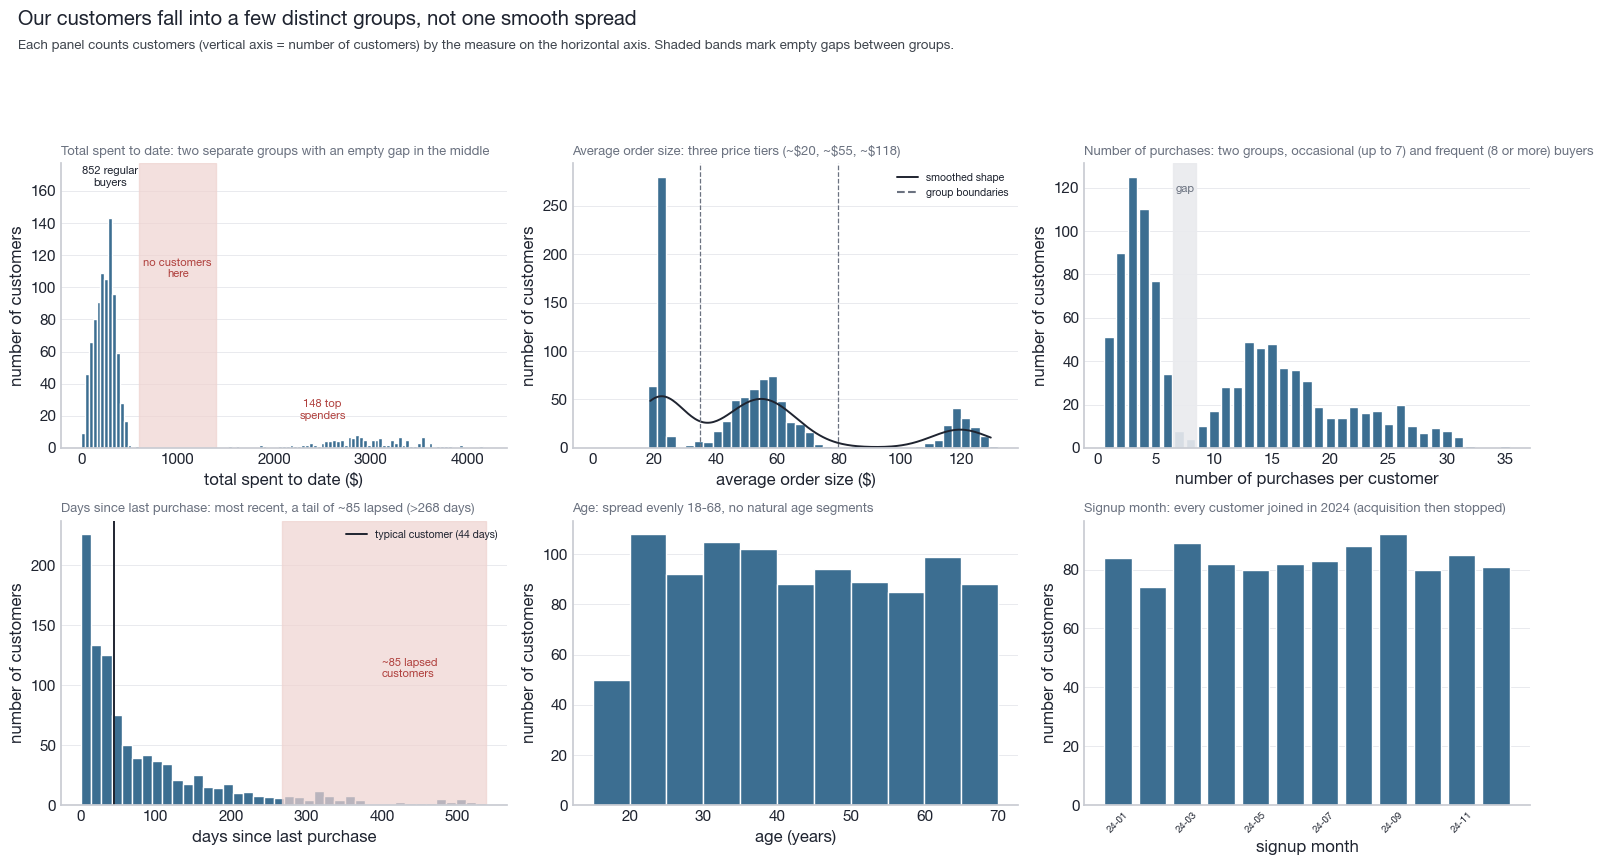

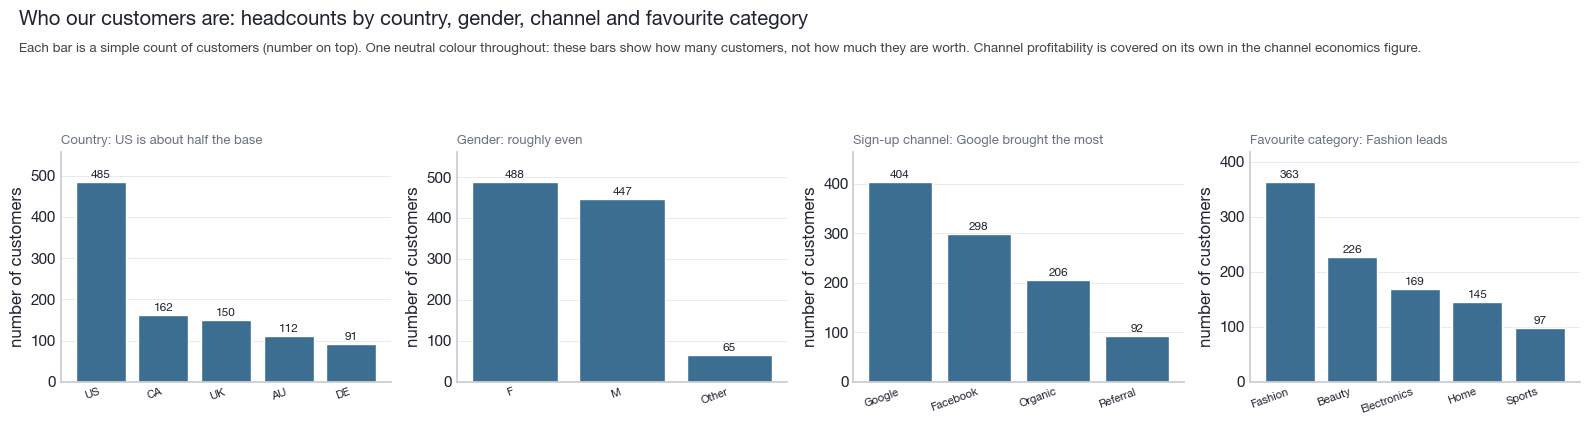

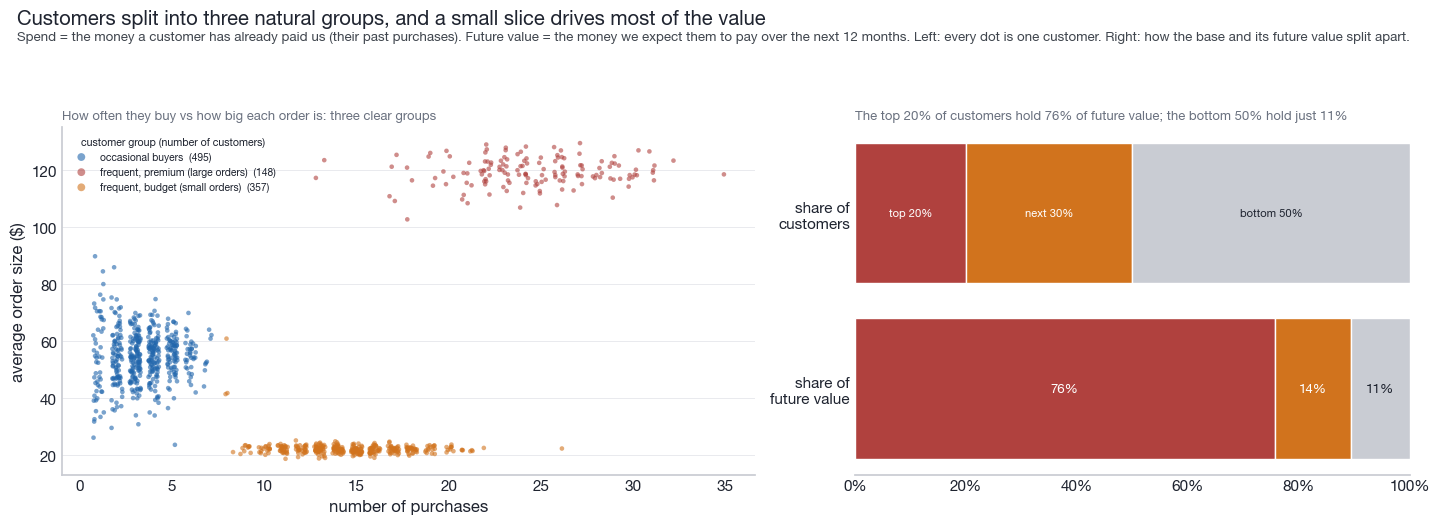

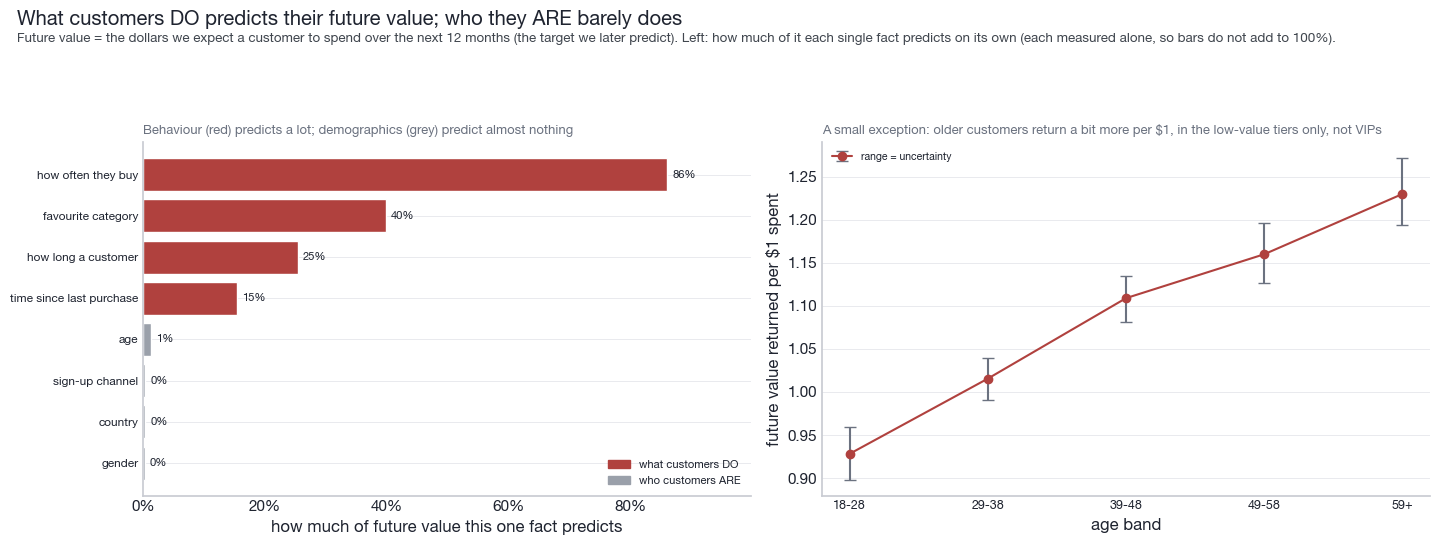

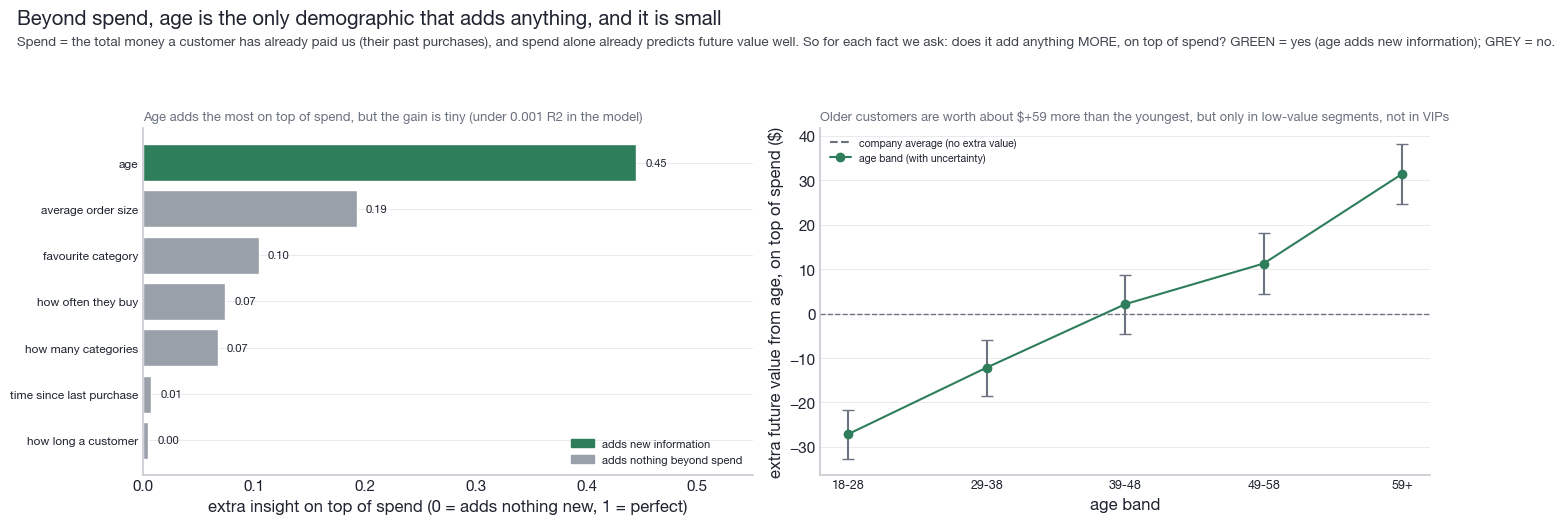

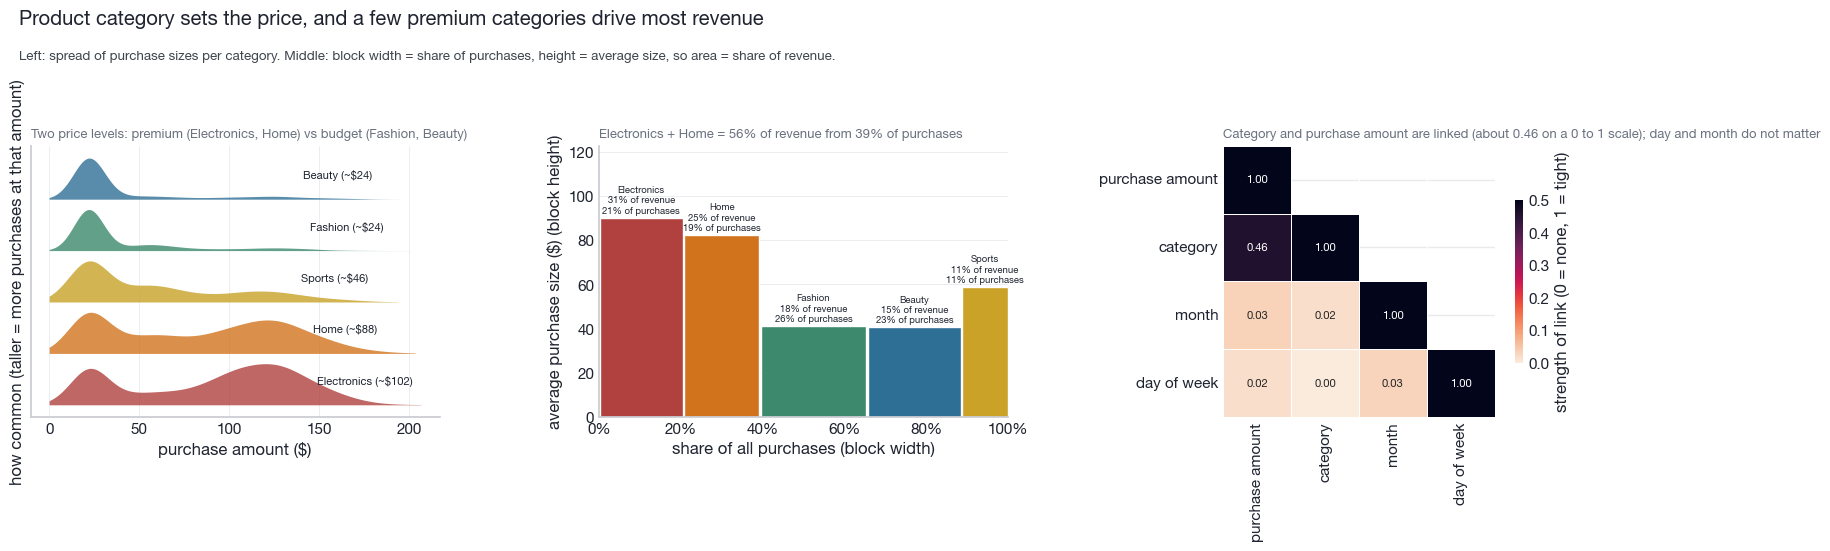

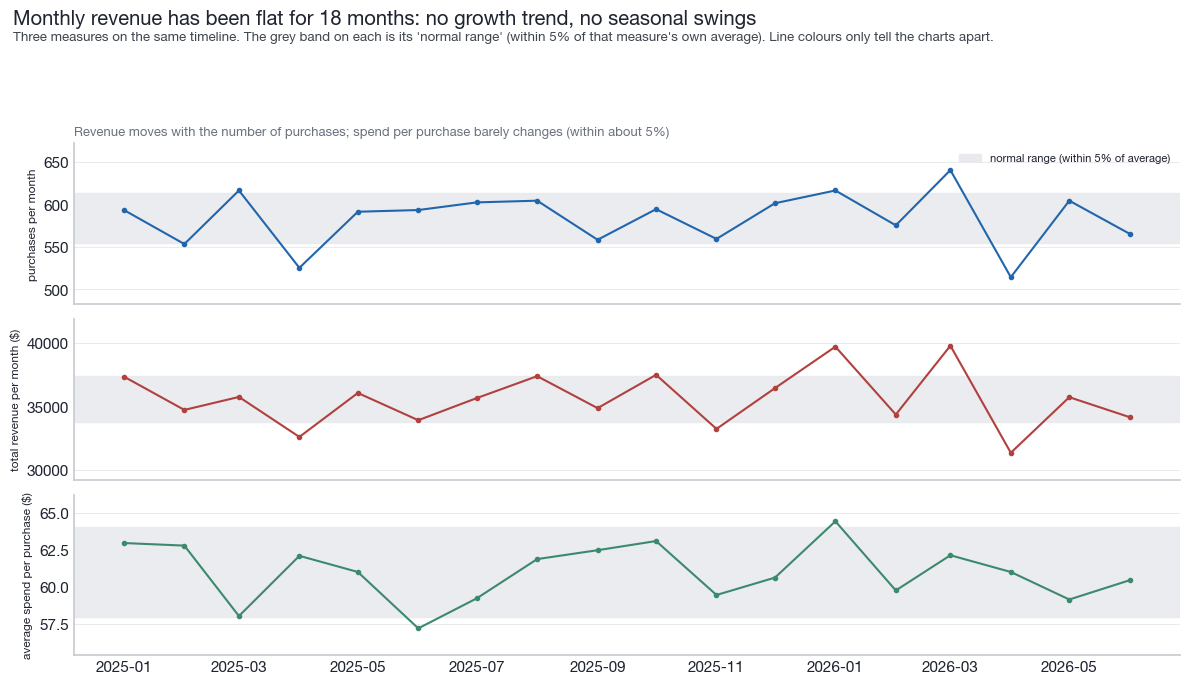

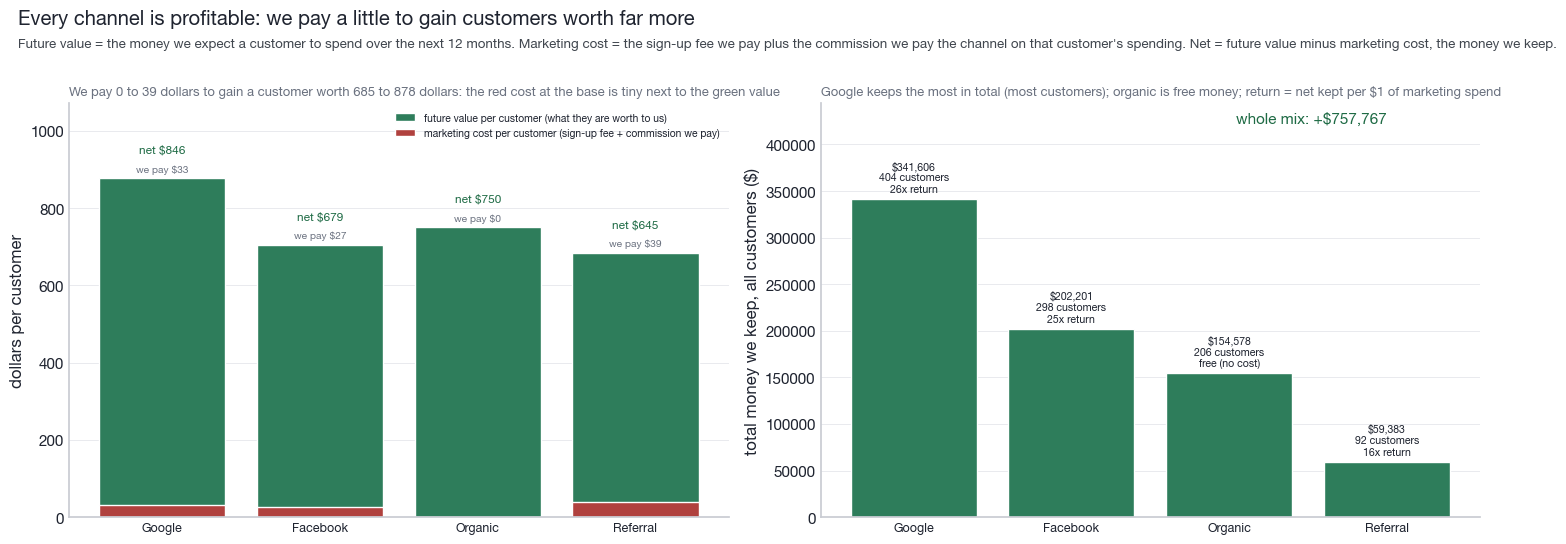

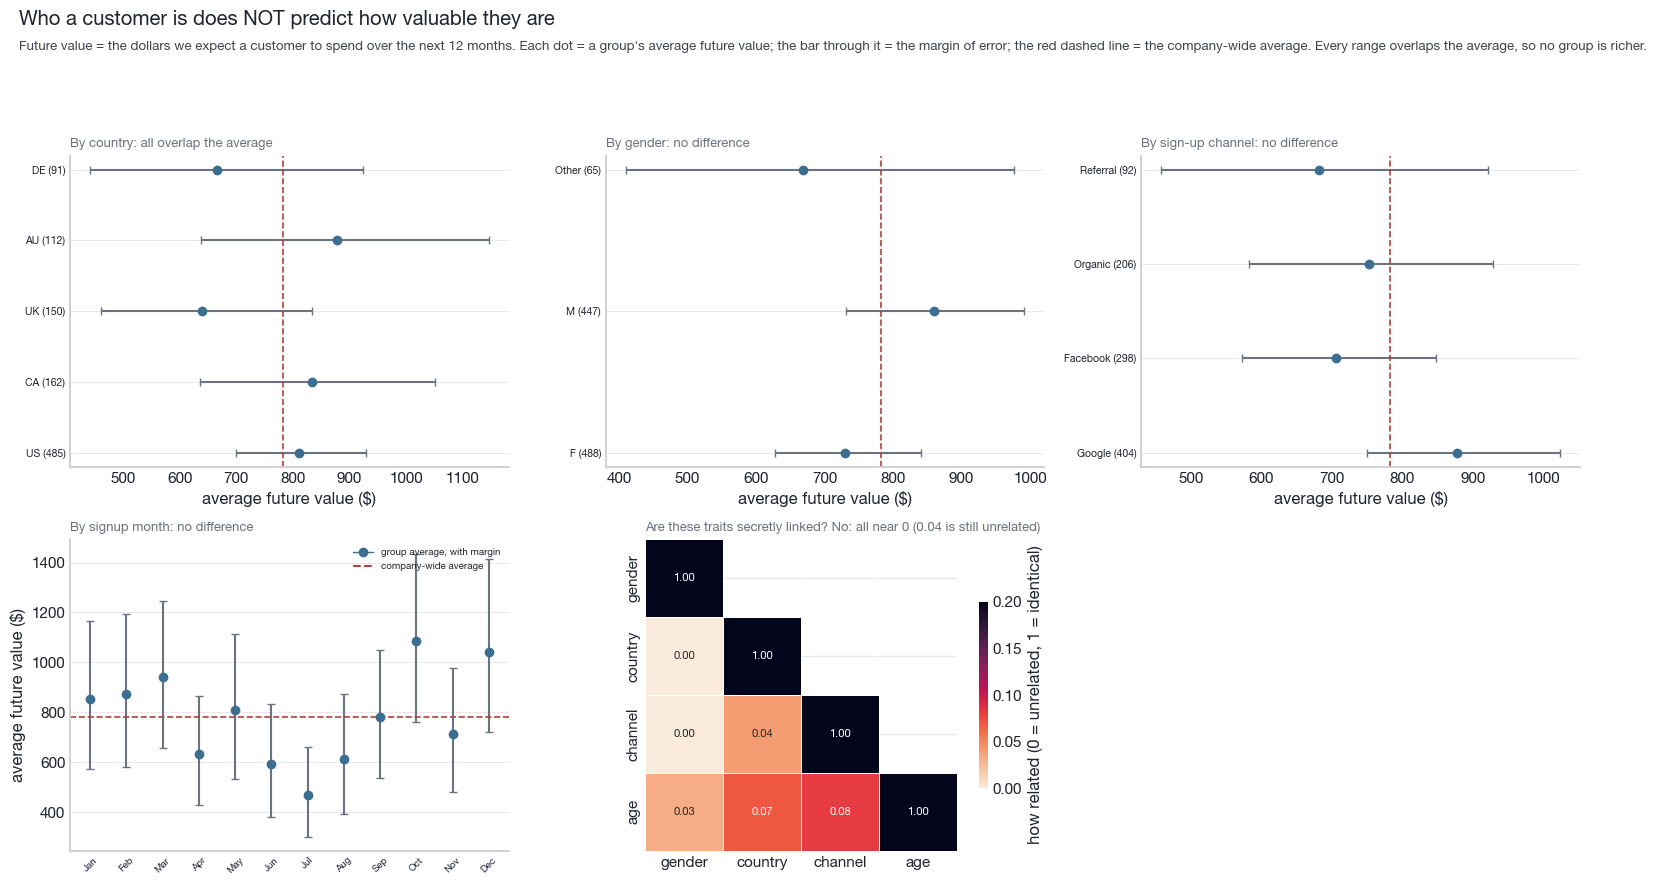

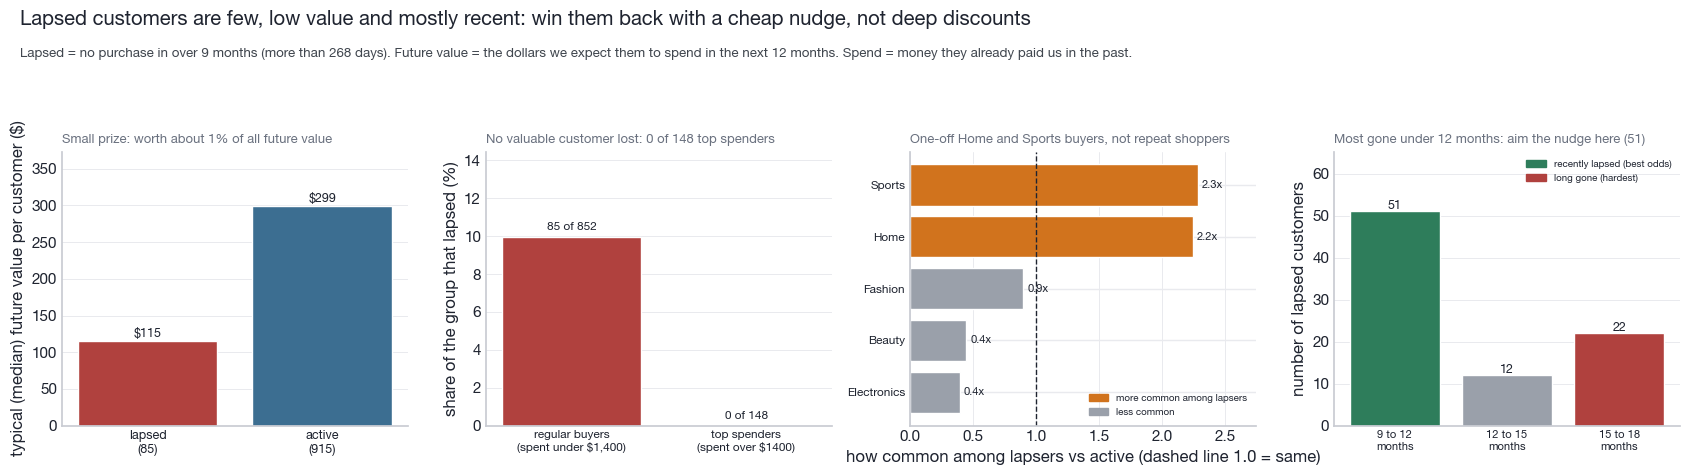

In [3]:
# EDA: full self-contained chunk (all figures). Runs top to bottom.

# =====================================================================
# WHY THIS APPROACH: this is exploratory analysis, so it quantifies association with
#   model-agnostic, distribution-light measures instead of one fitted model: eta-squared and
#   the correlation ratio eta (categorical to continuous), bias-corrected Cramer's V (categorical
#   to categorical), Spearman (rank, robust to nonlinearity and outliers), and bootstrap CIs for
#   group means. A single Pearson correlation matrix was rejected because it assumes linearity and
#   only handles numerics; reading importances straight off the later GradientBoosting model was
#   rejected here because EDA should not depend on a chosen model and should stay interpretable.
#   To separate what is NEW from what merely tracks spend, features are tested against the residual
#   of future value after a linear fit on past spend (partial association), since spend alone
#   already explains almost all of the target.
# HOW IT WORKS: load and merge the source tables to one row per customer (RFM plus order size,
#   category mix, tenure) -> derive fields (age bands, value per dollar, spend residual) ->
#   compute association statistics and bootstrap CIs per feature -> render figures 1 to 9 that
#   read the same way (shared palette, left-aligned headers, how-to-read captions).
# =====================================================================

# Palette hex constants: fixed named greys so every figure shares one visual language.
# INK = near-black for text/emphasis; MUTED = mid grey for secondary ticks; FRAME = light spine; GRID = faint gridline.
INK, MUTED, FRAME, GRID = "#1f2430", "#6b7280", "#c9ccd3", "#e9eaee"
CAP = "#41474f"                                        # readable caption grey (not faint)
BAR = "#3c6e91"                                        # ONE neutral bar colour (colour carries no meaning)
# POS/NEG/NEU = green/red/grey for good/bad/neutral encodings, reused across all panels for a consistent reading key.
POS, NEG, NEU = "#2e7d5b", "#b0413e", "#9aa0aa"
# plt.rcParams.update(dict): set global style once so no per-figure styling is repeated.
#   font.family list: preferred sans fonts first, DejaVu Sans last as the guaranteed matplotlib fallback so text always renders.
#   font.size 10: readable default for multi-panel figures. edgecolor/labelcolor/text.color: tie axes chrome to the palette.
#   xtick/ytick.color MUTED but labelcolor INK: de-emphasise tick marks, keep number labels dark and legible.
#   spines.top/right False: remove chartjunk borders. figure/axes.facecolor white: clean print-friendly background.
plt.rcParams.update({"font.family": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": FRAME, "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK, "ytick.labelcolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white"})
# Fixed category orders so bars/legends stay in the same sequence across every figure (VIP first = highest value).
SEG_ORDER = ["VIP", "Bargain Hunters", "Occasional Shoppers"]
CAT_ORDER = ["Electronics", "Home", "Sports", "Fashion", "Beauty"]
# CATPAL: one stable colour per category so a category reads the same hue in every panel.
CATPAL = dict(zip(CAT_ORDER, ["#b0413e", "#d1731d", "#c9a227", "#3c896d", "#2e6f95"]))
# np.random.default_rng(42): modern NumPy Generator (preferred over legacy np.random.seed); 42 = project RANDOM_STATE for reproducible jitter/bootstrap.
rng = np.random.default_rng(42)

def pol(ax):
    # spines top/right invisible: strip the box so only the L-shaped axis remains (less chartjunk).
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    # left/bottom set to FRAME: keep the two data-bounding spines but in the light frame grey.
    for sp in ["left", "bottom"]: ax.spines[sp].set_color(FRAME)
    # tick_params(length=0): hide tick dashes (labels are enough). set_axisbelow(True): draw grid behind bars.
    # grid on y only, GRID colour, lw .7: horizontal reference lines only, thin and faint so they never compete with data.
    ax.tick_params(length=0); ax.set_axisbelow(True); ax.grid(axis="y", color=GRID, lw=.7)
def hdr(fig, title, how_to_read, ty=.955):             # bold plain title + readable "how to read this" line
    # suptitle: x=.015/ha="left" left-align to the panel grid (not centered); fontsize 14.5 + bold = clear headline;
    #   color INK for max contrast; y=1.0 pins it to the very top so the how-to-read line sits just below.
    fig.suptitle(title, x=.015, ha="left", fontsize=14.5, fontweight="bold", color=INK, y=1.0)
    # fig.text at (.015, ty): the "how to read" caption, left-aligned under the title; fontsize 9.6 smaller than title; CAP grey = secondary but still readable.
    fig.text(.015, ty, how_to_read, ha="left", fontsize=9.6, color=CAP)
# sub: small left-aligned per-panel subtitle; loc="left" matches the figure's left-aligned style; MUTED = secondary weight; pad=6 gives breathing room above the axes.
def sub(a, t): a.set_title(t, loc="left", fontsize=9.4, color=MUTED, pad=6)
def boot_ci(x, B=2000):
    # Bootstrap 95% CI of the mean. B=2000 resamples: enough for stable 2.5/97.5 percentiles without being slow.
    # np.asarray(x, float): coerce to float array so rng.choice/mean behave. rng.choice(x, (B, len(x))): B resamples WITH replacement, each same size as x.
    # .mean(1): mean per resample (axis=1). percentile 2.5 and 97.5: the two tails of a 95% interval.
    x = np.asarray(x, float); m = rng.choice(x, (B, len(x))).mean(1); return m.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5)
def cramers_v(x, y):
    # Cramer's V: association strength between two categoricals on a 0 to 1 scale.
    # chi2_contingency(ct, correction=False)[0]: [0] = the chi-square statistic; correction=False disables Yates' continuity correction because Cramer's V is defined on the raw chi2.
    ct = pd.crosstab(x, y); chi2 = chi2_contingency(ct, correction=False)[0]; n = ct.to_numpy().sum(); r, k = ct.shape
    # Bias-corrected (Bergsma) Cramer's V: phi2=chi2/n; ph/rc/kc subtract the small-sample bias so V is not inflated on sparse tables. max(0,...) guards against a tiny negative.
    phi2 = chi2/n; ph = max(0, phi2-(k-1)*(r-1)/(n-1)); rc = r-(r-1)**2/(n-1); kc = k-(k-1)**2/(n-1)
    # d = min corrected dimension minus 1; return sqrt(ph/d), or 0.0 when d<=0 (a degenerate 1-level table has no association to measure).
    d = min(kc-1, rc-1); return np.sqrt(ph/d) if d > 0 else 0.0
def eta(cats, vals):
    # Correlation ratio (eta): how much a continuous value varies between categorical groups, 0 to 1.
    # DataFrame + dropna: align cats/vals and drop rows missing either. groupby("c")["v"]: per-group value series. yb = grand mean.
    dd = pd.DataFrame({"c": np.asarray(cats), "v": np.asarray(vals, float)}).dropna(); g = dd.groupby("c")["v"]; yb = dd.v.mean()
    # sb = between-group sum of squares (each group size times squared gap from grand mean); st = total SS. sqrt(sb/st) = eta, or 0.0 when there is no variance (st==0).
    sb = (g.count()*(g.mean()-yb)**2).sum(); st = ((dd.v-yb)**2).sum(); return np.sqrt(sb/st) if st > 0 else 0.0
def eta2(group, y):
    # eta-squared: fraction of variance in y explained by group membership (the SQUARE of eta, so it reads as an R2-like share).
    # reset_index(drop=True) on both: strip any index so the two Series align positionally before pairing; astype(str): treat group labels as discrete categories. dropna: drop unpaired/missing rows.
    dd = pd.DataFrame({"g": pd.Series(group).reset_index(drop=True).astype(str), "y": pd.Series(np.asarray(y, float)).reset_index(drop=True)}).dropna()
    # grand mean and total SS.
    grand = dd.y.mean(); sst = ((dd.y-grand)**2).sum()
    if sst == 0: return 0.0                             # no variance to explain, avoid divide-by-zero
    # observed=True: only iterate groups actually present (avoids empty categorical levels). Return between-group SS / total SS = eta-squared, cast to plain float.
    g = dd.groupby("g", observed=True)["y"]; return float((g.count()*(g.mean()-grand)**2).sum()/sst)
def dec(s):
    # Decile-bin a numeric series into 10 equal-count buckets so a continuous feature can be fed to eta2 as a category.
    # qcut(s, 10, duplicates="drop"): 10 quantile bins; duplicates="drop" merges identical bin edges instead of raising when many tied values share a quantile.
    try: return pd.qcut(s, 10, duplicates="drop").astype(str)
    except Exception: return s.astype(str)              # fallback: if qcut still fails (too few distinct values), treat raw values as labels
def show(fig, top):
    # tight_layout rect=[0,0,1,top]: reserve the strip above `top` for the suptitle/how-to-read header so tight_layout does not overlap them; then draw.
    fig.tight_layout(rect=[0, 0, 1, top]); plt.show()

# D: use local "data" dir if present else the parent "../data", so the cell runs both from repo root and from a notebook subfolder.
D = "data" if os.path.isdir("data") else "../data"
# read_csv the four source tables (f-string path so D swaps in).
customers = pd.read_csv(f"{D}/customers.csv"); transactions = pd.read_csv(f"{D}/transactions.csv")
clv_targets = pd.read_csv(f"{D}/clv_targets.csv"); channels = pd.read_csv(f"{D}/channels.csv")
# to_datetime: parse date strings so we can do date arithmetic (recency, tenure) below.
customers["signup_date"] = pd.to_datetime(customers["signup_date"]); transactions["transaction_date"] = pd.to_datetime(transactions["transaction_date"])
REF = pd.Timestamp("2026-07-01")                        # fixed "as of" date so recency (days_since_last) is reproducible, not tied to run time
# groupby("customer_id").agg(named aggregations): collapse the transaction log to one row per customer.
#   purchases = count of transactions (size). total_spend = sum of amount. avg_order = mean amount (typical basket size).
g = transactions.groupby("customer_id").agg(purchases=("transaction_id", "size"), total_spend=("amount", "sum"),
    #   days_since_last = recency in days from each customer's latest purchase to REF (lambda on the date series).
    avg_order=("amount", "mean"), days_since_last=("transaction_date", lambda s: (REF-s.max()).days),
    #   last/first = latest and earliest purchase dates (used to derive tenure). n_categories = distinct categories bought (breadth).
    last=("transaction_date", "max"), first=("transaction_date", "min"), n_categories=("category", "nunique"))
g["days_active"] = (g["last"]-g["first"]).dt.days       # tenure: span between first and last purchase, in days
# fav_category: each customer's most-frequent category via value_counts().idxmax() (ties broken by value_counts order); rename so the merge column is clear.
fav = transactions.groupby("customer_id")["category"].agg(lambda s: s.value_counts().idxmax()).rename("fav_category")
# Assemble one modelling table: merge customer attributes with the per-customer aggregates, favourite category, CLV target, and channel economics.
#   drop columns last/first: raw dates already turned into days_active, no longer needed downstream.
#   .merge defaults to how="inner" on customer_id / acquisition_channel, so the final table keeps only
#   customers present in every source table (any id missing from one table is dropped).
cust = (customers.merge(g.drop(columns=["last", "first"]), on="customer_id").merge(fav, on="customer_id")
        #   rename channel_name to acquisition_channel so it matches the key already in `cust`, then merge channel cost/commission fields.
        .merge(clv_targets, on="customer_id").merge(channels.rename(columns={"channel_name": "acquisition_channel"}), on="acquisition_channel"))
VAL = "target_clv_next_12_months"                      # projected future (next-12-month) customer value
# age_band via pd.cut: bin ages into marketing cohorts. Edges [17,28,...]: 17 is below 18 so the first band starts at 18 (right-closed bins); labels name each band; 120 = open-ended top.
cust["age_band"] = pd.cut(cust.age, [17, 28, 38, 48, 58, 120], labels=["18-28", "29-38", "39-48", "49-58", "59+"])
# value_per_dollar = future value divided by past spend (efficiency of a customer). signup_month via strftime("%b"): 3-letter month name for grouping.
cust["value_per_dollar"] = cust[VAL] / cust.total_spend; cust["signup_month"] = cust.signup_date.dt.strftime("%b")

# ============ FIG 1 · Distributions ============
# subplots(2,3): 2x3 grid of the six key distributions. figsize (15.5, 8.6): wide enough that six panels stay legible.
fig, ax = plt.subplots(2, 3, figsize=(15.5, 8.6))
hdr(fig, "Our customers fall into a few distinct groups, not one smooth spread",
    "Each panel counts customers (vertical axis = number of customers) by the measure on the horizontal axis. Shaded bands mark empty gaps between groups.")
# Panel [0,0] total spend histogram. bins = arange(0, max+50, 40): fixed 40-dollar-wide bins from 0, +50 pad so the last bin includes the max. color BAR: neutral (colour carries no meaning here).
a = ax[0, 0]; a.hist(cust.total_spend, bins=np.arange(0, cust.total_spend.max()+50, 40), color=BAR)
# set_ylim top *1.18: 18% headroom so annotation text does not collide with bars. axvspan(600,1400): shade the empty gap between the two spend clusters; alpha .7 keeps it subtle.
a.set_ylim(0, a.get_ylim()[1]*1.18); a.axvspan(600, 1400, color="#efd3d0", alpha=.7)
# text at (1000, 60% height): label the empty gap; NEG red draws the eye to "no customers here".
a.text(1000, a.get_ylim()[1]*.6, "no customers\nhere", ha="center", color=NEG, fontsize=8)
# Two callout labels: 852 regular buyers (INK, in the main cluster) and 148 top spenders (NEG red, in the far-right tail). Coordinates hand-placed over each cluster.
a.text(300, a.get_ylim()[1]*.92, "852 regular\nbuyers", ha="center", color=INK, fontsize=8); a.text(2500, 18, "148 top\nspenders", ha="center", color=NEG, fontsize=8)
# sub subtitle + axis labels; pol(a) applies the shared spine/grid style.
sub(a, "Total spent to date: two separate groups with an empty gap in the middle"); a.set_xlabel("total spent to date ($)"); a.set_ylabel("number of customers"); pol(a)
# Panel [0,1] average-order histogram. bins arange(0, max+3, 3): 3-dollar bins to resolve the narrow price tiers.
a = ax[0, 1]; a.hist(cust.avg_order, bins=np.arange(0, cust.avg_order.max()+3, 3), color=BAR)
# Overlay a KDE: linspace 200 points across the range = smooth curve; gaussian_kde(...)(kx) is a density, so *len(cust)*3 rescales it to the histogram's count axis (bin width 3). INK lw 1.4 = crisp overlay.
# gaussian_kde uses Scott's-rule bandwidth by default (auto scale ~ n**(-1/5)), so smoothing is data-driven, not hand-tuned.
kx = np.linspace(cust.avg_order.min(), cust.avg_order.max(), 200); a.plot(kx, gaussian_kde(cust.avg_order)(kx)*len(cust)*3, color=INK, lw=1.4)
# Dashed vertical lines at 35 and 80: the two boundaries separating the three price tiers; MUTED dashed lw .9 = light reference marks.
for xb in (35, 80): a.axvline(xb, color=MUTED, ls="--", lw=.9)
# Manual legend via proxy Line2D handles (the curve and the boundary lines are not naturally labelled). frameon=False = no box; small font; upper-right out of the data.
a.legend(handles=[Line2D([0], [0], color=INK, lw=1.4, label="smoothed shape"), Line2D([0], [0], color=MUTED, ls="--", label="group boundaries")], frameon=False, fontsize=7.5, loc="upper right")
sub(a, "Average order size: three price tiers (~$20, ~$55, ~$118)"); a.set_xlabel("average order size ($)"); a.set_ylabel("number of customers"); pol(a)
# Panel [0,2] purchase-count bar. value_counts().sort_index(): count customers per exact purchase count, ordered by count value on the x axis. axvspan(6.5,8.5): shade the 7-to-8 gap between occasional and frequent buyers.
a = ax[0, 2]; vc = cust.purchases.value_counts().sort_index(); a.bar(vc.index, vc.values, color=BAR); a.axvspan(6.5, 8.5, color=GRID, alpha=.9)
a.text(7.5, a.get_ylim()[1]*.9, "gap", ha="center", color=MUTED, fontsize=8)  # label centered in the shaded gap
sub(a, "Number of purchases: two groups, occasional (up to 7) and frequent (8 or more) buyers"); a.set_xlabel("number of purchases per customer"); a.set_ylabel("number of customers"); pol(a)
# Panel [1,0] recency histogram. bins=40: fine resolution to expose the long lapsed tail. axvline at median = the typical customer. axvspan(268, max): shade the lapsed region (>268 days).
a = ax[1, 0]; a.hist(cust.days_since_last, bins=40, color=BAR); a.axvline(cust.days_since_last.median(), color=INK, lw=1.4); a.axvspan(268, cust.days_since_last.max(), color="#efd3d0", alpha=.7)
# Legend labels the median line; :.0f formats the median as a whole number of days.
a.legend(handles=[Line2D([0], [0], color=INK, lw=1.4, label=f"typical customer ({cust.days_since_last.median():.0f} days)")], frameon=False, fontsize=7.5, loc="upper right")
a.text(400, a.get_ylim()[1]*.45, "~85 lapsed\ncustomers", color=NEG, fontsize=8)  # NEG red callout placed over the lapsed tail
sub(a, "Days since last purchase: most recent, a tail of ~85 lapsed (>268 days)"); a.set_xlabel("days since last purchase"); a.set_ylabel("number of customers"); pol(a)
# Panel [1,1] age histogram. bins=range(15,75,5): 5-year age buckets from 15 to 70; a flat spread shows no natural age segment.
a = ax[1, 1]; a.hist(cust.age, bins=range(15, 75, 5), color=BAR)
sub(a, "Age: spread evenly 18-68, no natural age segments"); a.set_xlabel("age (years)"); a.set_ylabel("number of customers"); pol(a)
# Panel [1,2] signups by month. to_period("M").value_counts().sort_index(): count signups per calendar month in chronological order. bar over range(len) then relabel so months are evenly spaced.
a = ax[1, 2]; sm = customers.signup_date.dt.to_period("M").value_counts().sort_index(); a.bar(range(len(sm)), sm.values, color=BAR)
# Show every 2nd tick (::2) to avoid crowding; str(x)[2:] strips the "20" from "2024-01" leaving "24-01"; rotation 45 for legibility.
a.set_xticks(range(0, len(sm), 2)); a.set_xticklabels([str(x)[2:] for x in sm.index[::2]], fontsize=7, rotation=45)
sub(a, "Signup month: every customer joined in 2024 (acquisition then stopped)"); a.set_xlabel("signup month"); a.set_ylabel("number of customers"); pol(a)
show(fig, .9)                                           # .9: leave the top 10% for this figure's header

# ============ FIG 2 · Composition ============
# subplots(1,4): four side-by-side headcount bars. figsize (16, 4.2): wide and short since each panel is a simple bar list.
fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
hdr(fig, "Who our customers are: headcounts by country, gender, channel and favourite category",
    "Each bar is a simple count of customers (number on top). One neutral colour throughout: these bars show how many customers, not how much they are worth. Channel profitability is covered on its own in the channel economics figure.", ty=.9)
def cbar(a, s, title):
    # sort_values(ascending=False): tallest bar first (ranked reading). color BAR: neutral, count-only.
    s = s.sort_values(ascending=False); a.bar(range(len(s)), s.values, color=BAR)
    # Data label above each bar: offset v + 2% of the max so the text floats just clear of the bar top.
    for i, v in enumerate(s.values): a.text(i, v+s.max()*.02, str(v), ha="center", fontsize=8.5, color=INK)
    # xticklabels = category names, rotation 20 + ha="right" so long labels do not overlap. ylim *1.15: 15% headroom for the data labels.
    a.set_xticks(range(len(s))); a.set_xticklabels(s.index, fontsize=8, rotation=20, ha="right"); a.set_ylim(0, s.max()*1.15); sub(a, title); a.set_ylabel("number of customers"); pol(a)
# One cbar per attribute; value_counts() gives the headcount per level.
cbar(ax[0], cust.country.value_counts(), "Country: US is about half the base")
cbar(ax[1], cust.gender.value_counts(), "Gender: roughly even")
cbar(ax[2], cust.acquisition_channel.value_counts(), "Sign-up channel: Google brought the most")
cbar(ax[3], cust.fav_category.value_counts(), "Favourite category: Fashion leads")
show(fig, .82)                                          # .82: taller header here (two-line how-to-read), so reserve more top space

# ============ FIG 3 · Value structure ============
# natgroup: rule-based label for the three natural behavioural groups. Thresholds fr<8 (occasional vs frequent) and av>=70 (budget vs premium order size) come from the FIG 1 gaps.
def natgroup(fr, av): return "occasional buyers" if fr < 8 else ("frequent, premium (large orders)" if av >= 70 else "frequent, budget (small orders)")
cust["group"] = [natgroup(fr, av) for fr, av in zip(cust.purchases, cust.avg_order)]  # zip pairs each customer's count and avg order to assign a group
GPAL = {"occasional buyers": "#2166AC", "frequent, premium (large orders)": "#b0413e", "frequent, budget (small orders)": "#d1731d"}  # fixed colour per group
# subplots(1,2) with width_ratios [1.25,1]: give the scatter (left) more width than the stacked bar (right).
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14.5, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
hdr(fig, "Customers split into three natural groups, and a small slice drives most of the value",
    "Spend = the money a customer has already paid us (their past purchases). Future value = the money we expect them to pay over the next 12 months. Left: every dot is one customer. Right: how the base and its future value split apart.", ty=.94)
for grp_ in ["occasional buyers", "frequent, premium (large orders)", "frequent, budget (small orders)"]:
    m = cust.group == grp_                              # boolean mask selecting this group's customers
    # scatter: x = purchases + uniform(-.3,.3) jitter so integer counts do not stack into vertical lines; y = avg_order. s=11 small dots; alpha .6 to show overplot density; edgecolor "none" for clean marks; label carries the group count.
    a0.scatter(cust.loc[m, "purchases"] + rng.uniform(-.3, .3, m.sum()), cust.loc[m, "avg_order"], s=11, color=GPAL[grp_], alpha=.6, edgecolor="none", label=f"{grp_}  ({m.sum()})")
a0.set_xlabel("number of purchases"); a0.set_ylabel("average order size ($)")
# legend: markerscale 1.7 enlarges the tiny s=11 dots in the key; title names what the parenthetical counts mean; upper-left where the scatter is sparse.
a0.legend(frameon=False, fontsize=7.4, markerscale=1.7, loc="upper left", title="customer group (number of customers)", title_fontsize=7.6)
sub(a0, "How often they buy vs how big each order is: three clear groups"); pol(a0)
q = cust[VAL].rank(pct=True)                            # percentile rank of each customer's future value (0 to 1), used to cut value tiers
# tiers: top 20% / next 30% / bottom 50% by value percentile, each with its display colour (red = most valuable, grey = least).
tiers = [("top 20%", q > .8, "#b0413e"), ("next 30%", (q > .5) & (q <= .8), "#d1731d"), ("bottom 50%", q <= .5, "#c9ccd3")]
# tot = total future value. cs = each tier's share of CUSTOMERS (%). vs = each tier's share of VALUE (%). This contrast is the whole point of the panel.
tot = cust[VAL].sum(); cs = [m.mean()*100 for _, m, _ in tiers]; vs = [cust.loc[m, VAL].sum()/tot*100 for _, m, _ in tiers]
l0 = [0.0, 0.0]                                         # running left-offsets for the two stacked bars (customers row, value row)
for (name, m, col), c_, v_ in zip(tiers, cs, vs):
    # Two horizontal stacked bars sharing the tier colour: one row = share of customers, other = share of value; left=l0 stacks segments; white edge separates them.
    a1.barh(["share of\ncustomers", "share of\nfuture value"], [c_, v_], left=l0, color=col, edgecolor="white")
    tc = "white" if col != "#c9ccd3" else INK          # white text on dark tiers, INK on the light grey tier, for contrast
    a1.text(l0[0]+c_/2, 0, name, ha="center", va="center", color=tc, fontsize=8)  # centre the tier name in its customer-row segment
    if v_ >= 5: a1.text(l0[1]+v_/2, 1, f"{v_:.0f}%", ha="center", va="center", color=tc, fontsize=9.5, fontweight="bold")  # only label value segments >=5% so tiny slivers stay unlabelled
    l0 = [l0[0]+c_, l0[1]+v_]                           # advance both running offsets by this segment's width
# xlim 0-100 and PercentFormatter: both bars are on a 0 to 100% scale. invert_yaxis: put the customers row on top.
a1.set_xlim(0, 100); a1.xaxis.set_major_formatter(PercentFormatter()); a1.invert_yaxis()
for sp in ["top", "right", "left"]: a1.spines[sp].set_visible(False)  # hide three spines; this is a proportion bar, only the bottom axis is meaningful
a1.spines["bottom"].set_color(FRAME); a1.tick_params(length=0)
sub(a1, f"The top 20% of customers hold {vs[0]:.0f}% of future value; the bottom 50% hold just {vs[2]:.0f}%")  # f-string injects the computed shares
show(fig, .9)

# ============ FIG 4 · Behaviour vs demographics ============
fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.4))
hdr(fig, "What customers DO predicts their future value; who they ARE barely does",
    "Future value = the dollars we expect a customer to spend over the next 12 months (the target we later predict). Left: how much of it each single fact predicts on its own (each measured alone, so bars do not add to 100%).", ty=.94)
# NAMES: plain-English labels for each predictor so the chart reads for non-technical stakeholders.
NAMES = {"purchases": "how often they buy", "fav_category": "favourite category", "days_active": "how long a customer",
         "days_since_last": "time since last purchase", "age": "age", "acquisition_channel": "sign-up channel", "country": "country", "gender": "gender"}
# preds: each predictor prepared as a categorical for eta2. Numeric ones (purchases, days_active, days_since_last, age) are decile-binned via dec(); truly categorical ones pass through as-is.
preds = {"purchases": dec(cust.purchases), "fav_category": cust.fav_category, "days_active": dec(cust.days_active),
         "days_since_last": dec(cust.days_since_last), "age": dec(cust.age), "acquisition_channel": cust.acquisition_channel, "country": cust.country, "gender": cust.gender}
# imp: eta2 (variance-explained) of future value for each predictor alone, sorted ascending so the strongest ends at the top of the horizontal bar chart.
imp = pd.Series({k: eta2(v, cust[VAL]) for k, v in preds.items()}).sort_values()
beh = {"purchases", "fav_category", "days_active", "days_since_last"}  # the behavioural predictors (vs demographic), used to colour bars
# barh coloured by kind: NEG red = behaviour, NEU grey = demographic, so the "DO vs ARE" split is visible at a glance.
ax[0].barh(range(len(imp)), imp.values, color=[NEG if k in beh else NEU for k in imp.index])
ax[0].set_yticks(range(len(imp))); ax[0].set_yticklabels([NAMES[k] for k in imp.index], fontsize=8.5)  # relabel ticks with the plain-English names in the sorted order
for i, v in enumerate(imp.values): ax[0].text(v+.008, i, f"{v:.0%}", va="center", fontsize=8)  # value label just past each bar; :.0% since eta2 is a 0 to 1 share
# PercentFormatter(1): data is on a 0-1 fraction scale, so 1 tells it to render fractions as percentages. xlim *1.16: room for the labels.
ax[0].xaxis.set_major_formatter(PercentFormatter(1)); ax[0].set_xlim(0, imp.max()*1.16); ax[0].set_xlabel("how much of future value this one fact predicts")
# Proxy Patch legend maps the two bar colours to DO vs ARE; lower-right sits in empty space.
ax[0].legend(handles=[Patch(color=NEG, label="what customers DO"), Patch(color=NEU, label="who customers ARE")], frameon=False, fontsize=8, loc="lower right")
sub(ax[0], "Behaviour (red) predicts a lot; demographics (grey) predict almost nothing"); pol(ax[0])
# Right panel: value_per_dollar by age band with bootstrap 95% CIs. boot_ci per band gives (mean, lo, hi).
bands = ["18-28", "29-38", "39-48", "49-58", "59+"]; rc = [boot_ci(cust.loc[cust.age_band == b, "value_per_dollar"]) for b in bands]
# m = band means; e = asymmetric error bars [lower gaps, upper gaps] built from the CI bounds, the shape errorbar's yerr expects.
m = [c[0] for c in rc]; e = [[mm-c[1] for mm, c in zip(m, rc)], [c[2]-mm for mm, c in zip(m, rc)]]
# errorbar: fmt "o-" = markers joined by a line to read the trend; capsize 4 for visible whisker ends; ecolor MUTED so bars sit behind the red points.
ax[1].errorbar(range(5), m, yerr=e, fmt="o-", color="#b0413e", capsize=4, ecolor=MUTED, label="range = uncertainty")
ax[1].set_xticks(range(5)); ax[1].set_xticklabels(bands, fontsize=9); ax[1].set_ylabel("future value returned per $1 spent"); ax[1].set_xlabel("age band"); ax[1].legend(frameon=False, fontsize=7.5, loc="upper left")
sub(ax[1], "A small exception: older customers return a bit more per $1, in the low-value tiers only, not VIPs"); pol(ax[1])
show(fig, .88)

# ============ FIG 4b · Beyond spend, only age adds new information ============
# polyfit(total_spend, VAL, 1): degree-1 (linear) fit of future value on past spend. b1c=slope, b0c=intercept. val_resid = the part of future value that spend does NOT explain (residual), so later tests ask what adds insight ON TOP of spend.
b1c, b0c = np.polyfit(cust.total_spend, cust[VAL], 1); cust["val_resid"] = cust[VAL] - (b0c + b1c*cust.total_spend)
NUMF = ["purchases", "days_since_last", "days_active", "n_categories", "avg_order", "age"]  # numeric features to test against the residual
# RN: plain-English labels for the residual chart.
RN = {"purchases": "how often they buy", "days_since_last": "time since last purchase", "days_active": "how long a customer",
      "n_categories": "how many categories", "avg_order": "average order size", "age": "age", "fav_category": "favourite category"}
# par: partial association with the residual. For numerics: abs(spearmanr.statistic), a rank correlation robust to nonlinearity and outliers; abs because we want strength, not direction. For the categorical fav_category: eta.
par = {k: abs(spearmanr(cust[k], cust.val_resid).statistic) for k in NUMF}; par["fav_category"] = eta(cust.fav_category, cust.val_resid)
FEATS = sorted(par, key=par.get)                       # feature keys sorted by association strength (ascending) for the bar order
fig, (a, c) = plt.subplots(1, 2, figsize=(14.5, 5.2))
hdr(fig, "Beyond spend, age is the only demographic that adds anything, and it is small",
    "Spend = the total money a customer has already paid us (their past purchases), and spend alone already predicts future value well. So for each fact we ask: does it add anything MORE, on top of spend? GREEN = yes (age adds new information); GREY = no.", ty=.93)
# barh: POS green only for "age" (the one demographic that adds signal), NEU grey for the rest, matching the narrative.
a.barh(range(len(FEATS)), [par[k] for k in FEATS], color=[POS if k == "age" else NEU for k in FEATS])
a.set_yticks(range(len(FEATS))); a.set_yticklabels([RN[k] for k in FEATS], fontsize=8.5)
for i, k in enumerate(FEATS): a.text(par[k]+.008, i, f"{par[k]:.2f}", va="center", fontsize=8)  # value label; :.2f since these are 0 to 1 correlations
a.set_xlim(0, .55); a.set_xlabel("extra insight on top of spend (0 = adds nothing new, 1 = perfect)")  # xlim capped at .55 since all values are small
a.legend(handles=[Patch(color=POS, label="adds new information"), Patch(color=NEU, label="adds nothing beyond spend")], frameon=False, fontsize=8, loc="lower right")
sub(a, "Age adds the most on top of spend, but the gain is tiny (under 0.001 R2 in the model)"); pol(a)
# Right panel: mean residual by age band with 95% CIs. Same age edges as before for consistency. observed=True: only populated bands.
bb = pd.cut(cust.age, [17, 28, 38, 48, 58, 120], labels=["18-28", "29-38", "39-48", "49-58", "59+"])
# se = standard error of the mean (std / sqrt(n)) per band; 1.96*se below gives the normal-approx 95% interval.
grp = cust.groupby(bb, observed=True)["val_resid"]; m = grp.mean(); se = grp.std()/np.sqrt(grp.count())
# errorbar yerr=1.96*se: 95% CI on each band mean; POS green ties to the "adds information" story; ecolor MUTED keeps whiskers subordinate.
c.errorbar(range(5), m.values, yerr=1.96*se.values, fmt="o-", color=POS, capsize=4, ecolor=MUTED)
c.axhline(0, color=MUTED, ls="--", lw=1)                # zero line = the company average (residual 0 means age adds no extra value there)
c.legend(handles=[Line2D([0], [0], color=MUTED, ls="--", label="company average (no extra value)"), Line2D([0], [0], color=POS, marker="o", label="age band (with uncertainty)")], frameon=False, fontsize=7.5, loc="upper left")
c.set_xticks(range(5)); c.set_xticklabels(m.index, fontsize=9); c.set_ylabel("extra future value from age, on top of spend ($)"); c.set_xlabel("age band")
sub(c, f"Older customers are worth about ${(m.iloc[-1]-m.iloc[0]):+.0f} more than the youngest, but only in low-value segments, not in VIPs"); pol(c)  # :+.0f shows the signed oldest-minus-youngest gap
show(fig, .9)

# ============ FIG 5 · Category ============
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
hdr(fig, "Product category sets the price, and a few premium categories drive most revenue",
    "Left: spread of purchase sizes per category. Middle: block width = share of purchases, height = average size, so area = share of revenue.", ty=.9)
# order: categories sorted by MEDIAN purchase amount (descending) so the ridgeline stacks priciest at top; median resists outliers better than mean.
order = transactions.groupby("category")["amount"].median().sort_values(ascending=False).index.tolist()
a = ax[0]
for i, c in enumerate(order):
    # Per-category ridgeline: gaussian_kde over 200 xs = smooth density (Scott's-rule bandwidth, auto); ds normalised to max .8 so each ridge has equal height (shape, not count, is compared). i offsets each ridge vertically.
    v = transactions.loc[transactions.category == c, "amount"].values; xs = np.linspace(0, v.max(), 200); ds = gaussian_kde(v)(xs); ds = ds/ds.max()*.8
    # fill_between from baseline i up to i+ds in the category colour; alpha .8; lw 0 no outline. Label at 72% of max width shows the category and its median price.
    a.fill_between(xs, i, i+ds, color=CATPAL[c], alpha=.8, lw=0); a.text(v.max()*.72, i+.4, f"{c} (~${np.median(v):.0f})", fontsize=8, color=INK)
a.set_yticks([]); a.set_xlabel("purchase amount ($)"); a.set_ylabel("how common (taller = more purchases at that amount)")  # y ticks off: ridge offsets are not a numeric scale
sub(a, "Two price levels: premium (Electronics, Home) vs budget (Fashion, Beauty)"); a.grid(axis="x", color=GRID, lw=.6); a.tick_params(length=0)  # grid on x here since amount is the horizontal axis
# Middle panel: a marimekko-style bar. cnt = purchases per category, rev = revenue per category, avg = mean purchase size.
a = ax[1]; cnt = transactions.category.value_counts(); rev = transactions.groupby("category")["amount"].sum(); avg = transactions.groupby("category")["amount"].mean()
o2 = rev.sort_values(ascending=False).index.tolist(); wt = cnt[o2].sum(); left = 0  # o2 = categories by revenue desc; wt = total purchases for width normalisation; left = running x offset
for c in o2:
    # w = cnt[c]/wt: bar WIDTH = this category's share of all purchases. a.bar: HEIGHT = avg[c] mean size, so area ~= revenue;
    #   width=w*.98 leaves a hairline white gap between blocks; centred at left+w/2; color per category; white edge separates blocks.
    w = cnt[c]/wt; a.bar(left+w/2, avg[c], width=w*.98, color=CATPAL[c], edgecolor="white")
    # Label the block with category, its % of revenue, and its % of purchases; +2 lifts text above the bar.
    a.text(left+w/2, avg[c]+2, f"{c}\n{rev[c]/rev.sum()*100:.0f}% of revenue\n{cnt[c]/wt*100:.0f}% of purchases", ha="center", fontsize=6.8, color=INK); left += w  # advance offset by this block's width
# xlim 0-1 and PercentFormatter(1): x axis is a 0 to 1 share of purchases rendered as %. ylim *1.36: headroom for the three-line labels.
a.set_xlim(0, 1); a.set_ylim(0, avg.max()*1.36); a.xaxis.set_major_formatter(PercentFormatter(1)); a.set_xlabel("share of all purchases (block width)"); a.set_ylabel("average purchase size ($) (block height)")
sub(a, "Electronics + Home = 56% of revenue from 39% of purchases"); a.grid(axis="y", color=GRID, lw=.6); a.tick_params(length=0)
# Right panel: association heatmap among transaction attributes. items = the four fields compared; ITN = plain labels.
a = ax[2]; items = ["amount", "category", "month", "weekday"]; ITN = {"amount": "purchase amount", "category": "category", "month": "month", "weekday": "day of week"}
# Derive month and weekday from the date so temporal fields can be tested. weekday: Monday=0.
txn = transactions.assign(month=transactions.transaction_date.dt.month, weekday=transactions.transaction_date.dt.weekday)
M = pd.DataFrame(np.eye(4), index=items, columns=items)  # start from identity: diagonal = 1 (perfect self-association)
for i, x1 in enumerate(items):
    for x2 in items[i+1:]:                              # upper pairs only; matrix is symmetric so fill both [x1,x2] and [x2,x1]
        # If one field is the continuous "amount", use eta (categorical vs continuous), passing the non-amount field as the category; otherwise both are categorical so use Cramer's V.
        M.loc[x1, x2] = M.loc[x2, x1] = eta(txn[x2 if x1 == "amount" else x1].astype(str), txn["amount"]) if "amount" in (x1, x2) else cramers_v(txn[x1].astype(str), txn[x2].astype(str))
mask = np.triu(np.ones_like(M, dtype=bool), 1)         # mask the strict upper triangle so only the lower triangle + diagonal show (no duplicate cells)
# heatmap: cmap "rocket_r" reversed so dark = strong link; vmin/vmax 0 to .5 fix the scale across figures; annot .2f prints values; square cells; white gridlines; shrunk colourbar with a plain-language label.
sns.heatmap(M, mask=mask, cmap="rocket_r", vmin=0, vmax=.5, annot=True, fmt=".2f", annot_kws={"size": 8}, square=True, linewidths=.6, linecolor="white",
            cbar_kws={"shrink": .6, "label": "strength of link (0 = none, 1 = tight)"}, ax=a, xticklabels=[ITN[i] for i in items], yticklabels=[ITN[i] for i in items])
sub(a, "Category and purchase amount are linked (about 0.46 on a 0 to 1 scale); day and month do not matter"); a.tick_params(length=0)
show(fig, .86)

# ============ FIG 6 · Temporal ============
# Set date index, then resample("MS") = month-start buckets: vol=count, rev=sum, avg=mean per month.
mtx = transactions.set_index("transaction_date"); vol = mtx.resample("MS").size(); rev = mtx.resample("MS")["amount"].sum(); avg = mtx.resample("MS")["amount"].mean()
# subplots(3,1, sharex=True): three stacked timelines sharing the x (date) axis so trends line up vertically.
fig, ax = plt.subplots(3, 1, figsize=(12, 6.8), sharex=True)
hdr(fig, "Monthly revenue has been flat for 18 months: no growth trend, no seasonal swings",
    "Three measures on the same timeline. The grey band on each is its 'normal range' (within 5% of that measure's own average). Line colours only tell the charts apart.")
for a, s, lab_, c in [(ax[0], vol, "purchases per month", "#2166AC"), (ax[1], rev, "total revenue per month ($)", "#b0413e"), (ax[2], avg, "average spend per purchase ($)", "#3c896d")]:
    # plot "o-" markers+line, ms 3 small dots; axhspan mean*.95 to mean*1.05 shades the +/-5% "normal range" so flatness is obvious; margins(y=.25) pads vertically so the band is not flush to the edges.
    a.plot(s.index, s.values, "o-", color=c, ms=3); a.axhspan(s.mean()*.95, s.mean()*1.05, color=GRID, alpha=.9); a.set_ylabel(lab_, fontsize=8.5); a.margins(y=.25); pol(a)
ax[0].legend(handles=[Patch(color=GRID, label="normal range (within 5% of average)")], frameon=False, fontsize=8, loc="upper right")  # explain the grey band once, on the top panel
sub(ax[0], "Revenue moves with the number of purchases; spend per purchase barely changes (within about 5%)")
show(fig, .9)

# ============ FIG 7 · Channel economics ============
# revenue_share_rate is a COMMISSION WE PAY the channel (a % of the customer's spending), NOT money we keep.
# groupby channel .agg: n=headcount, val=mean future value, cac=cost_per_signup ("first" since it is constant within a channel), rs=revenue_share_rate ("first" likewise).
ce = cust.groupby("acquisition_channel").agg(n=("customer_id", "size"), val=(VAL, "mean"), cac=("cost_per_signup", "first"), rs=("revenue_share_rate", "first"))
ce["commission"] = ce.val*ce.rs                       # commission we pay the channel, per customer (its % of their future spend)
ce["mktg"] = ce.cac + ce.commission                   # total marketing cost per customer = sign-up fee + commission
ce["net"] = ce.val - ce.mktg                          # what we keep per customer = future value minus marketing cost
ce["total"] = ce.net*ce.n                             # total kept across all of the channel's customers
ce["roi"] = ce.net / ce.mktg.replace(0, np.nan)       # net kept per $1 of marketing spend (undefined for free organic)
# sort by total kept (desc) so the best channel is leftmost. CH = channel order; x = bar positions.
ce = ce.sort_values("total", ascending=False); CH = ce.index.tolist(); x = np.arange(len(CH))
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 5.4))
hdr(fig, "Every channel is profitable: we pay a little to gain customers worth far more",
    "Future value = the money we expect a customer to spend over the next 12 months. Marketing cost = the sign-up fee we pay plus the commission we pay the channel on that customer's spending. Net = future value minus marketing cost, the money we keep.", ty=.93)
# Panel A: per customer, the customer's value (green) vs what we pay to get them (red sliver at the base)
# Full-height green bar = value per customer; overplotted short red bar (same x) = marketing cost, so the red sliver at the base shows how tiny the cost is next to value.
a.bar(x, [ce.val[c] for c in CH], color=POS, label="future value per customer (what they are worth to us)")
a.bar(x, [ce.mktg[c] for c in CH], color=NEG, label="marketing cost per customer (sign-up fee + commission we pay)")
for i, c in enumerate(CH):
    a.text(i, ce.val[c]+66, f"net ${ce.net[c]:,.0f}", ha="center", fontsize=8.5, fontweight="bold", color="#1f6b45")  # net label +66 above the green bar top; :, thousands separator
    a.text(i, ce.val[c]+16, f"we pay ${ce.mktg[c]:.0f}", ha="center", fontsize=7.3, color=MUTED)  # smaller cost label just below the net label
# ylim *1.22: headroom for the stacked labels. xticklabels = channel names.
a.set_xticks(x); a.set_xticklabels(CH, fontsize=9); a.set_ylim(0, max(ce.val)*1.22); a.set_ylabel("dollars per customer")
a.legend(frameon=False, fontsize=7.4, loc="upper right")
sub(a, "We pay 0 to 39 dollars to gain a customer worth 685 to 878 dollars: the red cost at the base is tiny next to the green value"); pol(a)
# Panel B: total money we keep, across all customers, per channel
b.bar(x, [ce.total[c] for c in CH], color=POS)          # green = total net kept per channel
for i, c in enumerate(CH):
    roi_lab = "free (no cost)" if not np.isfinite(ce.roi[c]) else f"{ce.roi[c]:.0f}x return"  # organic has 0 marketing cost so roi is inf/nan: label it "free" instead of a multiple
    b.text(i, ce.total[c]+max(ce.total)*.015, f"${ce.total[c]:,.0f}\n{ce.n[c]} customers\n{roi_lab}", ha="center", va="bottom", fontsize=7.6, color=INK)  # label offset 1.5% of max above each bar
b.set_xticks(x); b.set_xticklabels(CH, fontsize=9); b.set_ylim(0, max(ce.total)*1.30); b.set_ylabel("total money we keep, all customers ($)")  # ylim *1.30: room for three-line labels
b.text(len(CH)-1, max(ce.total)*1.24, f"whole mix: +${ce.total.sum():,.0f}", ha="right", fontsize=11, fontweight="bold", color="#1f6b45")  # grand-total callout, right-aligned over the last bar
sub(b, "Google keeps the most in total (most customers); organic is free money; return = net kept per $1 of marketing spend"); pol(b)
show(fig, .95)

# ============ FIG 8 · What does NOT predict value ============
gm = cust[VAL].mean()                                   # company-wide mean future value, drawn as the reference line every group is compared against
fig, ax = plt.subplots(2, 3, figsize=(16, 8.8))
hdr(fig, "Who a customer is does NOT predict how valuable they are",
    "Future value = the dollars we expect a customer to spend over the next 12 months. Each dot = a group's average future value; the bar through it = the margin of error; the red dashed line = the company-wide average. Every range overlaps the average, so no group is richer.")
def nullp(a, by, title):
    # For each level of the grouping attribute, bootstrap a 95% CI of mean future value. lv ordered by frequency (value_counts index).
    lv = list(cust[by].value_counts().index); cis = [boot_ci(cust.loc[cust[by] == l, VAL]) for l in lv]
    m = [c[0] for c in cis]; e = [[mm-c[1] for mm, c in zip(m, cis)], [c[2]-mm for mm, c in zip(m, cis)]]  # means and asymmetric [lower,upper] error arms from the CIs
    # Horizontal errorbar: fmt "o" points only (no connecting line, groups are unordered categories); xerr=e; capsize 3. axvline gm = company average dashed red.
    a.errorbar(m, range(len(lv)), xerr=e, fmt="o", color="#3c6e91", capsize=3, ecolor=MUTED); a.axvline(gm, color=NEG, ls="--", lw=1.2)
    a.set_yticks(range(len(lv))); a.set_yticklabels([f"{l} ({(cust[by]==l).sum()})" for l in lv], fontsize=7.5); a.set_xlabel("average future value ($)"); sub(a, title); pol(a)  # tick labels include each level's n
# One null-result panel per demographic attribute.
nullp(ax[0, 0], "country", "By country: all overlap the average"); nullp(ax[0, 1], "gender", "By gender: no difference"); nullp(ax[0, 2], "acquisition_channel", "By sign-up channel: no difference")
om = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]  # calendar order for the signup-month panel (value_counts would not be chronological)
mm = [boot_ci(cust.loc[cust.signup_month == mo, VAL]) for mo in om]; me = [c[0] for c in mm]; ee = [[a-b[1] for a, b in zip(me, mm)], [b[2]-a for a, b in zip(me, mm)]]  # CI per month, means, asymmetric arms
# Vertical errorbar over the 12 months; axhline gm = company average.
ax[1, 0].errorbar(range(12), me, yerr=ee, fmt="o", color="#3c6e91", capsize=3, ecolor=MUTED); ax[1, 0].axhline(gm, color=NEG, ls="--", lw=1.2)
ax[1, 0].set_xticks(range(12)); ax[1, 0].set_xticklabels(om, fontsize=7, rotation=45); ax[1, 0].set_ylabel("average future value ($)"); sub(ax[1, 0], "By signup month: no difference")
ax[1, 0].legend(handles=[Line2D([0], [0], color="#3c6e91", marker="o", lw=1, label="group average, with margin"), Line2D([0], [0], color=NEG, ls="--", label="company-wide average")], frameon=False, fontsize=7, loc="upper right"); pol(ax[1, 0])
attrs = ["gender", "country", "acquisition_channel", "age"]; A = pd.DataFrame(np.eye(4), index=attrs, columns=attrs)  # identity start: check whether the demographics are secretly correlated with each other
for i, x1 in enumerate(attrs):
    for x2 in attrs[i+1:]:
        # age is continuous so pair it via eta (categorical-vs-continuous, passing the non-age field as category); all-categorical pairs use Cramer's V. Symmetric fill of both cells.
        A.loc[x1, x2] = A.loc[x2, x1] = eta(cust[x2 if x1 == "age" else x1], cust["age"]) if "age" in (x1, x2) else cramers_v(cust[x1], cust[x2])
mask = np.triu(np.ones_like(A, dtype=bool), 1)         # show lower triangle + diagonal only
# heatmap: vmax .2 (tighter than FIG 5) because these associations are expected to be near zero, so a small ceiling makes any faint link visible. rocket_r dark=high; annot .2f; square; white gridlines.
sns.heatmap(A, mask=mask, cmap="rocket_r", vmin=0, vmax=.2, annot=True, fmt=".2f", annot_kws={"size": 8}, square=True, linewidths=.6, linecolor="white",
            cbar_kws={"shrink": .6, "label": "how related (0 = unrelated, 1 = identical)"}, ax=ax[1, 1], xticklabels=["gender", "country", "channel", "age"], yticklabels=["gender", "country", "channel", "age"])
sub(ax[1, 1], "Are these traits secretly linked? No: all near 0 (0.04 is still unrelated)"); ax[1, 1].tick_params(length=0)
ax[1, 2].axis("off")                                    # sixth cell unused: blank it so no empty axes frame shows
show(fig, .91)

# ============ FIG 9 · Lapsed customers and how to win them back ============
AMBER = "#d1731d"                                        # warm colour flagging categories over-represented among lapsers
LAP = 268                                              # lapsed = more than about 9 months since last purchase
cust["lapsed"] = cust.days_since_last > LAP             # boolean lapsed flag from the recency threshold
L = cust[cust.lapsed]; Aa = cust[~cust.lapsed]          # split into lapsed (L) and active (Aa) subframes
fig, ax = plt.subplots(1, 4, figsize=(17, 4.7))
hdr(fig, "Lapsed customers are few, low value and mostly recent: win them back with a cheap nudge, not deep discounts",
    "Lapsed = no purchase in over 9 months (more than 268 days). Future value = the dollars we expect them to spend in the next 12 months. Spend = money they already paid us in the past.", ty=.9)
# Panel A: the prize is small
# Compare the MEDIAN (outlier-resistant) future value of lapsed vs active. Colours: NEG red for lapsed, BAR neutral for active.
a = ax[0]; ml, ma = L[VAL].median(), Aa[VAL].median(); a.bar([0, 1], [ml, ma], color=[NEG, BAR])
for i, v in enumerate([ml, ma]): a.text(i, v+6, f"${v:.0f}", ha="center", fontsize=9, color=INK)  # value label +6 above each bar
a.set_xticks([0, 1]); a.set_xticklabels([f"lapsed\n({len(L)})", f"active\n({len(Aa)})"], fontsize=9)  # tick labels carry each group's size
a.set_ylabel("typical (median) future value per customer ($)"); a.set_ylim(0, ma*1.25)  # ylim scaled to the larger (active) median plus headroom
sub(a, "Small prize: worth about 1% of all future value"); pol(a)
# Panel B: no valuable customer lost
# Split by spend at $1,400 (the FIG 1 gap between regular buyers and top spenders) and show each group's lapse rate.
b = ax[1]; tiers = [("regular buyers\n(spent under $1,400)", cust.total_spend <= 1400), ("top spenders\n(spent over $1400)", cust.total_spend > 1400)]
rates = [cust.loc[m, "lapsed"].mean()*100 for _, m in tiers]; cnts = [(int(cust.loc[m, "lapsed"].sum()), int(m.sum())) for _, m in tiers]  # lapse % and (lapsed, total) counts per tier
b.bar([0, 1], rates, color=[NEG, POS])                  # NEG red for regular buyers, POS green for top spenders (whose 0% lapse is the good-news bar)
for i, (lp, tot) in enumerate(cnts): b.text(i, rates[i]+.35, f"{lp} of {tot}", ha="center", fontsize=8.5, color=INK)  # "lapsed of total" label just above each bar
b.set_xticks([0, 1]); b.set_xticklabels([t for t, _ in tiers], fontsize=8.5); b.set_ylabel("share of the group that lapsed (%)"); b.set_ylim(0, max(rates)*1.35+1)  # +1 guards against a 0 max so ylim stays positive
sub(b, "No valuable customer lost: 0 of 148 top spenders"); pol(b)
# Panel C: why they lapsed (category over/under vs active customers)
# fl/fa = share of each favourite category among lapsers vs actives (normalize=True gives proportions).
c = ax[2]; fl = L.fav_category.value_counts(normalize=True); fa = Aa.fav_category.value_counts(normalize=True)
# Ratio fl/fa reindexed to the fixed category order, missing filled 0, sorted ascending. >1 = over-represented among lapsers (AMBER), else NEU grey.
idx = (fl/fa).reindex(CAT_ORDER).fillna(0).sort_values(); cols = [AMBER if v > 1 else NEU for v in idx.values]
c.barh(range(len(idx)), idx.values, color=cols); c.axvline(1, color=INK, ls="--", lw=1)  # dashed line at 1.0 = same prevalence in both groups
c.set_yticks(range(len(idx))); c.set_yticklabels(idx.index, fontsize=8.5)
for i, v in enumerate(idx.values): c.text(v+.03, i, f"{v:.1f}x", va="center", fontsize=8)  # "x" ratio label past each bar
c.set_xlim(0, idx.max()*1.2); c.set_xlabel("how common among lapsers vs active (dashed line 1.0 = same)")
c.legend(handles=[Patch(color=AMBER, label="more common among lapsers"), Patch(color=NEU, label="less common")], frameon=False, fontsize=7, loc="lower right")
sub(c, "One-off Home and Sports buyers, not repeat shoppers")
for sp in ["top", "right"]: c.spines[sp].set_visible(False)  # this panel grids on x, so style spines manually rather than via pol()
c.tick_params(length=0); c.grid(axis="x", color=GRID, lw=.7); c.set_axisbelow(True)
# Panel D: winnability (how long gone)
# Bin lapsed customers by how long ago they lapsed; recent = best win-back odds. Bins hand-set to 9-12, 12-15, 15-18 month ranges (in days).
d = ax[3]; bins = [(268, 365, "9 to 12\nmonths"), (365, 455, "12 to 15\nmonths"), (455, 600, "15 to 18\nmonths")]
vals = [int(((L.days_since_last > lo) & (L.days_since_last <= hi)).sum()) for lo, hi, _ in bins]  # count lapsers in each recency window (half-open lo<x<=hi so bins do not double-count)
d.bar(range(3), vals, color=[POS, NEU, NEG])            # green (best odds) to red (hardest) left to right
for i, v in enumerate(vals): d.text(i, v+.6, str(v), ha="center", fontsize=9, color=INK)  # count label +.6 above each bar
d.set_xticks(range(3)); d.set_xticklabels([lab for *_, lab in bins], fontsize=8); d.set_ylabel("number of lapsed customers"); d.set_ylim(0, max(vals)*1.28)  # *1.28 headroom for labels
d.legend(handles=[Patch(color=POS, label="recently lapsed (best odds)"), Patch(color=NEG, label="long gone (hardest)")], frameon=False, fontsize=7, loc="upper right")
sub(d, f"Most gone under 12 months: aim the nudge here ({vals[0]})"); pol(d)  # f-string reports the recent-lapser count to target
show(fig, .84)


## Part 1: Market Segmentation (k-Means & k-NN)

**1A: Feature engineering and clustering.** Build one row per customer from `transactions.csv` and `customers.csv`: RFM (recency, frequency, monetary) plus behavioural features such as tenure, average order value and category affinity. Group the customers with k-Means, choose the number of clusters with the elbow method and the silhouette score, then profile each cluster and give it a business name and a short description.

**1B: Classification.** Train a k-Nearest Neighbours (k-NN) classifier on the same customer features so that a new customer can be placed in one of these segments without re-running the clustering, measure how well it does on held-out customers, and choose k by cross-validation.

## Part 1A · Feature Engineering

**Goal.** Turn the raw purchase log (many rows per customer) into **one row per customer** that describes how they shop. These features feed the k-Means segmentation (next step) and the CLV model (Part 2).

### Leak-safety: the reference date

The CLV target is spending from **2026-07-01 to 2027-06-30**. To avoid leaking the future into the features, we set:

- **Cutoff = 2026-06-30**: a feature may only use purchases on or before this date.
- **REF = 2026-07-01** (the day the prediction window opens): the "as of" date we measure recency and tenure from, so both are counted up to the moment we start predicting.

A hard assert stops the notebook if any transaction falls after the cutoff.

### Every feature and how it is calculated

| Feature | Calculation | Meaning |
|---|---|---|
| **recency** | `REF minus (last purchase date)`, in days | days since last purchase; lower = shopped more recently (the R in RFM) |
| **frequency** | count of transactions per customer | how many purchases so far (the F in RFM) |
| **monetary** | sum of `amount` per customer | total money spent so far, in dollars (the M in RFM) |
| **aov** | `monetary divided by frequency` (mean of `amount`) | average order value: dollars per purchase |
| **tenure** | `REF minus (signup date)`, in days | how long they have been a customer |
| **active_span** | `(last purchase) minus (first purchase)`, in days | length of their buying history; 0 for a one-time buyer |
| **category_diversity** | count of distinct `category` values bought | how broad their taste is, 1 to 5 |
| **pct_electronics ... pct_beauty** | spend in that category `divided by` total spend | category affinity: the share of each customer's spend in each of the 5 categories (the five sum to 1) |
| **top_category** | the category with the highest total spend | the single category they spend the most on |
| age, gender, country, acquisition_channel, signup_date | copied from `customers.csv` | profile fields, carried for interpreting segments later (not used as clustering inputs) |

### The algorithm (step by step)

1. **Parse dates** on copies of the two tables (idempotent if already parsed).
2. **Leak guard:** assert every transaction date is on or before the cutoff.
3. **Aggregate the purchase log** by `customer_id` to get frequency, monetary, aov, first and last purchase dates, and category_diversity.
4. **Derive** recency (`REF minus last`) and active_span (`last minus first`) from those dates.
5. **Category affinity:** pivot spend into a customer-by-category grid, divide each row by its total to get shares (`pct_*`), and take the row-max category as `top_category`.
6. **Tenure** from signup date (`REF minus signup`).
7. **Join** the profile fields, the aggregates, the category shares, and the top category into one `features` table.
8. **Sanity checks:** exactly one row per customer, and no missing values in the model features.

### What feeds k-Means

The four scale-and-skew-sensitive drivers **recency, frequency, monetary, aov** are the clustering inputs. Because they are right-skewed and on very different scales, the next chunk will `log1p`-transform and standardize them before running k-Means. The category shares and profile fields are kept for profiling and for the CLV model, not for the clustering distance.

**Result:** a `features` table of 1000 customers by 19 columns, leak-free (built from purchases up to 2026-06-30).

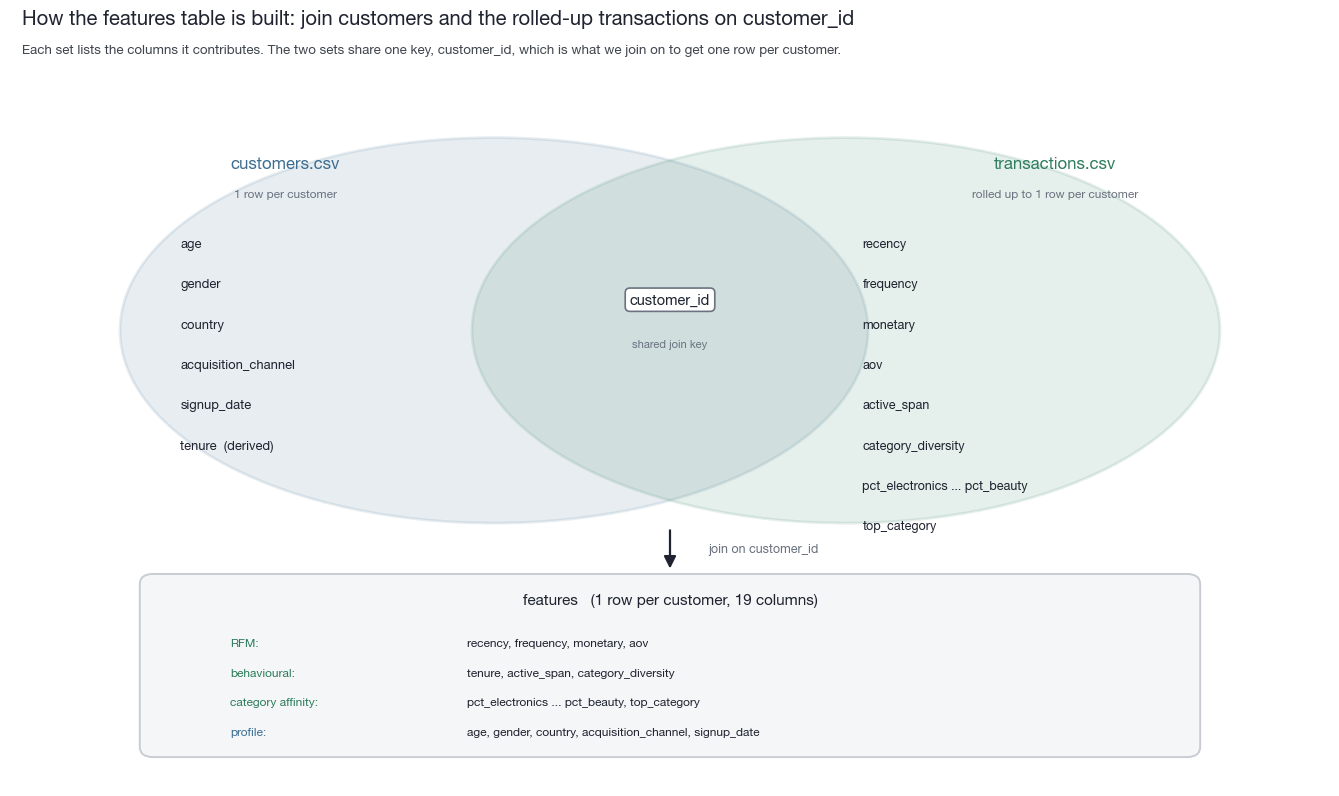

**Built `features`: 1000 customers by 19 columns** (leak-free, using purchases up to 2026-06-30)

,meaning
feature,
recency,days since last purchase (lower = shopped more recently)
frequency,number of purchases so far
monetary,total money spent so far ($)
aov,average order value = spend per purchase ($)
tenure,days since the customer signed up
active_span,days between first and last purchase (0 if they bought only once)
category_diversity,number of different categories bought (1 to 5)
pct_<category>,share of the customer's spend in each of the 5 categories (the five sum to 1)
top_category,the single category the customer spends the most on


,customer_id,recency,frequency,monetary,aov,tenure,active_span,category_diversity,pct_electronics,pct_home,pct_sports,pct_fashion,pct_beauty,top_category,age,gender,country,acquisition_channel,signup_date
0,C0001,457,2,91.99,45.995000,619,57,1,0.000000,1.000000,0.000000,0.000000,0.000000,Home,58,M,UK,Google,2024-10-20
1,C0002,157,10,225.86,22.586000,762,383,2,0.000000,0.000000,0.000000,0.283937,0.716063,Beauty,19,F,UK,Referral,2024-05-30
2,C0003,158,3,188.82,62.940000,897,164,2,0.000000,0.000000,0.000000,0.260460,0.739540,Beauty,28,M,US,Google,2024-01-16
3,C0004,41,10,231.44,23.144000,581,494,4,0.140425,0.052670,0.000000,0.368389,0.438515,Beauty,32,F,AU,Facebook,2024-11-27
4,C0005,1,19,444.58,23.398947,770,542,5,0.065185,0.099037,0.099015,0.395272,0.341491,Fashion,66,M,CA,Google,2024-05-22


In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# PART 1A · FEATURE ENGINEERING  (customer-level RFM + behavioural features)
# ═══════════════════════════════════════════════════════════════════════════
# Turns the raw purchase log into ONE leak-free row per customer, then shows
# (a) how the join is built and (b) a data dictionary + preview.
# The result `features` feeds k-Means (next chunk) and the CLV model (Part 2).

# =====================================================================
# WHY THIS APPROACH: summarise each customer as per-customer RFM (recency,
#   frequency, monetary) plus a few behavioural and category-affinity features,
#   because segmentation and CLV both need ONE row per customer, not the raw
#   many-row purchase log. RFM is the standard, interpretable retail summary, so
#   it beats hand-picked ad hoc columns. A strict leak boundary is used instead
#   of aggregating all available history: the CLV target measures spend from
#   2026-07-01 onward, so features may only see data up to 2026-06-30, else a
#   feature would encode the future it is supposed to predict.
# HOW IT WORKS: load customers + transactions -> assert no post-cutoff rows ->
#   groupby customer_id to reduce the log to RFM, aov, active_span and category
#   shares -> add tenure from signup, anchored at the window open -> merge the
#   pieces into one leak-free features table with one row per customer.
# =====================================================================

# The six values below are fixed hex colours (a house-style palette), not
# computed: arbitrary brand choices, kept as named constants only for
# readability so the plot code reads INK/BLUE/... instead of raw hex.
INK, MUTED, FRAME = "#1f2430", "#6b7280", "#c9ccd3"    # text / label / border (match the house style)
BLUE, GREEN, CAP  = "#3c6e91", "#2e7d5b", "#41474f"    # customers set / transactions set / caption grey

# ── load the two source tables ────────────────────────────────────────────────
# os.path.isdir("data"): probe cwd so the same cell runs both from the repo root
# (data/ present) and from a notebook subdir (data one level up); picks the path
# that actually exists rather than hard-coding one.
D = "data" if os.path.isdir("data") else "../data"
# f"{D}/customers.csv": path built from the resolved base D so the read works
# from either cwd; read_csv default-infers dtypes, which is fine for raw load.
customers    = pd.read_csv(f"{D}/customers.csv")
transactions = pd.read_csv(f"{D}/transactions.csv")

# ── leak boundary ─────────────────────────────────────────────────────────────
# CUTOFF: the target measures spend from 2026-07-01 onward, so features may only use
# data up to the day before that window opens. That day is 2026-06-30 (and it is also
# where transactions.csv ends), so using anything later would leak the future.
# "2026-06-30": the last in-window training day; chosen because it is the day
# before the prediction window opens, so nothing after it is visible to features.
CUTOFF = pd.Timestamp("2026-06-30")
# days=1: shift the clock to 2026-07-01 so recency/tenure are measured "as of"
# the window open; a purchase on the cutoff day then reads recency 1, not 0.
REF    = CUTOFF + pd.Timedelta(days=1)                 # 2026-07-01: the "as of" clock for recency and tenure

# ── parse dates on copies (idempotent) then guard against leakage ─────────────
# .copy(): work on a duplicate so re-running the cell never mutates the raw frame
# in place (keeps the transform idempotent). pd.to_datetime: turn the date
# strings into datetime64 so subtraction/.dt arithmetic below is valid.
tx = transactions.copy(); tx["transaction_date"] = pd.to_datetime(tx["transaction_date"])
cu = customers.copy();    cu["signup_date"]      = pd.to_datetime(cu["signup_date"])
# <= CUTOFF then .all(): assert EVERY transaction sits on or before the boundary;
# .all() collapses the elementwise mask to one bool, failing loudly if any future
# row slipped in (which would leak the target into the features).
assert (tx["transaction_date"] <= CUTOFF).all(), "found transactions after the cutoff -> would leak the future"

# ── RFM + behavioural aggregates, one row per customer ────────────────────────
# groupby("customer_id"): collapse the many-row purchase log to one row per
# customer (the modelling grain). Named-agg tuples are (column, reduction):
agg = tx.groupby("customer_id").agg(
    frequency          = ("transaction_id", "size"),   # F: number of purchases  # "size" counts rows (incl. any NaN) = raw purchase count, unlike "count"
    monetary           = ("amount", "sum"),            # M: total spend so far ($)  # "sum" = lifetime spend to date
    aov                = ("amount", "mean"),           # average order value = spend per purchase  # "mean" = spend per order
    first_purch        = ("transaction_date", "min"),  # "min" = earliest purchase date, used for active_span
    last_purch         = ("transaction_date", "max"),  # "max" = most recent purchase date, drives recency
    category_diversity = ("category", "nunique"),      # how many different categories they buy  # "nunique" = distinct categories, ignores repeats
)
# .dt.days: extract the integer day count from the Recency timedelta; REF (not
# CUTOFF) is the anchor so recency is measured from the window open.
agg["recency"]     = (REF - agg["last_purch"]).dt.days                 # R: days since last purchase (lower = recent)
# .dt.days: integer span between a customer's first and last order; single-order
# customers get 0 (same date minus itself).
agg["active_span"] = (agg["last_purch"] - agg["first_purch"]).dt.days  # days between first and last purchase (0 if one-time)

# ── category affinity: each customer's share of spend per category ────────────
# CAT_ORDER: fixed column order (roughly premium to budget) so category columns
# are stable and comparable across runs; ordering is a presentation convention.
CAT_ORDER = ["Electronics", "Home", "Sports", "Fashion", "Beauty"]     # premium to budget
# pivot_table args: index="customer_id" one row per customer; columns="category"
# one column per category; values="amount" the quantity aggregated;
# aggfunc="sum" total (not mean) spend per category because we want each
# category's share of the customer's TOTAL spend; fill_value=0 so a category the
# customer never bought reads 0, not NaN, which keeps the share math clean.
cat_spend = tx.pivot_table(index="customer_id", columns="category", values="amount", aggfunc="sum", fill_value=0)
# reindex(columns=CAT_ORDER, ...): force all five categories to be present and in
# the canonical order even if some never appear in tx; fill_value=0 for any added.
cat_spend = cat_spend.reindex(columns=CAT_ORDER, fill_value=0)
# .div(cat_spend.sum(1), axis=0): sum(1) totals each customer's spend across the
# category columns (axis=1); axis=0 divides each row by its own total so the five
# shares sum to 1. Safe here because every customer has >=1 purchase, so no /0.
cat_share = cat_spend.div(cat_spend.sum(1), axis=0)                    # fraction of spend per category (rows sum to 1)
# f"pct_{c.lower()}": lowercase, snake-ish column names (pct_electronics, ...);
# purely a readability/naming convention for the downstream feature table.
cat_share.columns = [f"pct_{c.lower()}" for c in cat_share.columns]    # pct_electronics, pct_home, ...
# idxmax(1): argmax across the category columns (axis=1) returns the category
# NAME of the customer's largest spend; .rename gives the resulting Series a col.
# Run on cat_spend (raw dollars), not cat_share, but the winner is identical:
# dividing every category by the same per-customer total is order preserving, so
# the largest dollar category is also the largest share. On an exact tie idxmax
# returns the FIRST column, so the CAT_ORDER reindex (premium to budget) breaks
# ties toward the more premium category.
top_category = cat_spend.idxmax(1).rename("top_category")             # the single top-spend category

# ── tenure, then join everything into one table ───────────────────────────────
# assign(tenure=...): add days-since-signup, again anchored at REF so tenure is
# "as of" the window open and consistent with recency.
cu = cu.assign(tenure = (REF - cu["signup_date"]).dt.days)            # days since signup
# cu[[...]]: keep only the profile columns needed downstream (drop anything raw
# we do not model on). Each .merge joins on="customer_id", the shared grain key;
# default inner join is fine because agg/shares cover exactly the customer set.
features = (cu[["customer_id", "age", "gender", "country", "acquisition_channel", "signup_date", "tenure"]]
            .merge(agg.drop(columns=["first_purch", "last_purch"]), on="customer_id")   # + RFM & behavioural  # drop raw first/last dates: recency & active_span already captured them
            .merge(cat_share, on="customer_id")                                          # + category shares
            .merge(top_category, on="customer_id"))                                      # + top category
# RFM/BEHAV/PCT: name-group lists used only to reorder columns below; PCT is
# discovered by prefix so it stays correct if category count ever changes.
RFM   = ["recency", "frequency", "monetary", "aov"]
BEHAV = ["tenure", "active_span", "category_diversity"]
PCT   = [c for c in features.columns if c.startswith("pct_")]
# features[[...]]: reorder into a readable layout (id, then numeric model
# features, then categorical/profile trailing); pure presentation, no data change.
features = features[["customer_id"] + RFM + BEHAV + PCT +
                    ["top_category", "age", "gender", "country", "acquisition_channel", "signup_date"]]

# ── sanity checks ─────────────────────────────────────────────────────────────
# == len(customers): the merges must neither drop nor duplicate anyone, so the
# joined table has exactly one row per original customer.
assert len(features) == len(customers),            "every customer should have exactly one feature row"
# .isna().sum().sum() == 0: first .sum() counts NaNs per column, second collapses
# to one scalar; asserts the model features (RFM+BEHAV) are fully populated.
assert features[RFM + BEHAV].isna().sum().sum() == 0, "no missing values in the model features"

# ── (a) join diagram: two sets sharing customer_id, joined into features ──────
# subplots(figsize=(13.5, 8)): wide canvas to fit two side-by-side set ellipses;
# set_xlim/set_ylim define a manual 0..12 by 0..8.4 coordinate frame so every
# text/patch below can be hand-placed; axis("off") hides ticks/spines because
# this is a schematic, not a data plot.
fig, ax = plt.subplots(figsize=(13.5, 8)); ax.set_xlim(0, 12); ax.set_ylim(0, 8.4); ax.axis("off")
# suptitle args: x=.02 + ha="left" pin the title to the left margin (house style,
# not centered); fontweight="bold"/fontsize=14.5 title emphasis; color=INK the
# dark text colour; y=.99 nudge to the very top edge.
fig.suptitle("How the features table is built: join customers and the rolled-up transactions on customer_id",
             x=.02, ha="left", fontweight="bold", fontsize=14.5, color=INK, y=.99)
# fig.text(.02, .935, ...): sub-caption under the title in figure coords (x=.02
# left margin, y=.935 just below title); fontsize=9.6 smaller than title;
# color=CAP muted grey to read as secondary text.
fig.text(.02, .935, "Each set lists the columns it contributes. The two sets share one key, customer_id, which is what we join on to get one row per customer.",
         ha="left", fontsize=9.6, color=CAP)
# Ellipse((cx,cy), width, height, ...): the two overlapping "set" shapes;
# alpha=.12 keeps the fill faint so the overlap region stays legible; lw=2 for a
# visible outline; BLUE = customers set, GREEN = transactions set (colour code).
ax.add_patch(Ellipse((4.4, 5.2), 6.8, 4.4, facecolor=BLUE, alpha=.12, edgecolor=BLUE, lw=2))
ax.add_patch(Ellipse((7.6, 5.2), 6.8, 4.4, facecolor=GREEN, alpha=.12, edgecolor=GREEN, lw=2))
# ax.text(x, y, label, ...): manual labels at frame coords. ha="center" centers
# over the ellipse; fontweight="bold"+larger fontsize for headings, MUTED grey +
# smaller for the sub-labels; colours match each set (BLUE/GREEN).
ax.text(2.5, 7.05, "customers.csv", ha="center", fontweight="bold", color=BLUE, fontsize=12)
ax.text(2.5, 6.72, "1 row per customer", ha="center", color=MUTED, fontsize=8.5)
ax.text(9.5, 7.05, "transactions.csv", ha="center", fontweight="bold", color=GREEN, fontsize=12)
ax.text(9.5, 6.72, "rolled up to 1 row per customer", ha="center", color=MUTED, fontsize=8.5)
# enumerate loop: list the profile columns down the left ellipse; 6.15-i*0.46
# steps each row down by a fixed 0.46 line pitch; ha="left" left-aligns the list.
for i, c in enumerate(["age", "gender", "country", "acquisition_channel", "signup_date", "tenure  (derived)"]):
    ax.text(1.55, 6.15-i*0.46, c, ha="left", fontsize=9.3, color=INK)
# same idea for the transactions-derived columns down the right ellipse; slightly
# smaller fontsize=9.0 to fit the longer names.
for i, c in enumerate(["recency", "frequency", "monetary", "aov", "active_span", "category_diversity", "pct_electronics ... pct_beauty", "top_category"]):
    ax.text(7.75, 6.15-i*0.46, c, ha="left", fontsize=9.0, color=INK)
# ha/va="center" center the key label in the overlap; bbox draws a white rounded
# pill (boxstyle pad=0.32 breathing room, fc white to mask the ellipse fill,
# ec=MUTED thin grey border) so "customer_id" stands out as the shared key.
ax.text(6.0, 5.55, "customer_id", ha="center", va="center", fontweight="bold", fontsize=10.5, color=INK,
        bbox=dict(boxstyle="round,pad=0.32", fc="white", ec=MUTED, lw=1.2))
ax.text(6.0, 5.05, "shared join key", ha="center", va="center", fontsize=8, color=MUTED)
# FancyArrowPatch((start),(end), ...): downward arrow from the sets to the result
# box; arrowstyle="-|>" a solid filled head; mutation_scale=18 sizes that head;
# lw=1.6 shaft weight; color=INK to match the dark text.
ax.add_patch(FancyArrowPatch((6.0, 2.95), (6.0, 2.45), arrowstyle="-|>", mutation_scale=18, color=INK, lw=1.6))
ax.text(6.35, 2.7, "join on customer_id", ha="left", va="center", fontsize=9, color=MUTED)
# FancyBboxPatch((x,y), w, h, ...): the "features" result container; boxstyle
# rounding_size=0.12 soft corners, pad=0.02 tight inset; fc light grey fill to
# set it apart from the white page, ec=FRAME subtle border, lw=1.4.
ax.add_patch(FancyBboxPatch((1.2, 0.35), 9.6, 2.05, boxstyle="round,pad=0.02,rounding_size=0.12", fc="#f4f6f8", ec=FRAME, lw=1.4))
ax.text(6.0, 2.08, "features   (1 row per customer, 19 columns)", ha="center", fontweight="bold", fontsize=11, color=INK)
# enumerate over (group, columns): print the four feature families inside the box.
for i, (grp, cols) in enumerate([("RFM", "recency, frequency, monetary, aov"),
        ("behavioural", "tenure, active_span, category_diversity"),
        ("category affinity", "pct_electronics ... pct_beauty, top_category"),
        ("profile", "age, gender, country, acquisition_channel, signup_date")]):
    y = 1.6-i*0.34                                       # 0.34 line pitch: step each group row down
    # GREEN if i < 3 else BLUE: colour-code the label by source, the first three
    # groups are transaction-derived (GREEN), the profile group is customer (BLUE).
    ax.text(2.0, y, grp+":", ha="left", fontweight="bold", fontsize=8.6, color=GREEN if i < 3 else BLUE)
    ax.text(4.15, y, cols, ha="left", fontsize=8.6, color=INK)
# tight_layout(): trim surrounding whitespace so the schematic fills the canvas;
# show(): flush/render this figure before the cell prints the tables below.
plt.tight_layout(); plt.show()

# ── (b) data dictionary + preview (full text, no truncation) ──────────────────
# DEFS: hand-written plain-English glossary for each engineered feature; content
# only (documentation strings), no computation, so a reader can read the
# meaning of every column without inferring it from code.
DEFS = {
    "recency": "days since last purchase (lower = shopped more recently)",
    "frequency": "number of purchases so far",
    "monetary": "total money spent so far ($)",
    "aov": "average order value = spend per purchase ($)",
    "tenure": "days since the customer signed up",
    "active_span": "days between first and last purchase (0 if they bought only once)",
    "category_diversity": "number of different categories bought (1 to 5)",
    "pct_<category>": "share of the customer's spend in each of the 5 categories (the five sum to 1)",
    "top_category": "the single category the customer spends the most on",
}
# f-string pulls features.shape[0] (rows = customers) and shape[1] (cols) plus
# CUTOFF.date() so the printed summary states the exact size and leak boundary,
# self-documenting the artefact for the reader.
display(Markdown(f"**Built `features`: {features.shape[0]} customers by {features.shape[1]} columns** "
                 f"(leak-free, using purchases up to {CUTOFF.date()})"))
# Build the glossary as a DataFrame (feature -> meaning) and set_index("feature")
# so the feature name becomes the row label for a clean two-column display.
_dict = pd.DataFrame({"feature": list(DEFS), "meaning": list(DEFS.values())}).set_index("feature")
# option_context("display.max_colwidth", None): None = unlimited width, so the
# long 'meaning' strings render in full instead of being truncated with "..."; a
# context manager so the setting reverts right after this display.
with pd.option_context("display.max_colwidth", None):   # show the full 'meaning' text, no truncation
    display(_dict)
# features.head(): preview the first rows (default 5) as a sanity check on the
# final layout without dumping all ~1000 customers.
display(features.head())


## Part 1A · Clustering: group customers, choose k, name the segments

**What we cluster on and why.** The four behavioural value-drivers: `recency`, `frequency`, `monetary`, `aov`. Demographics are deliberately excluded, because the EDA showed they carry no value signal, and the resulting segments turn out to have near-identical age and gender. So the segments describe how people **behave**, not who they are.

### Preprocessing (two steps, each with a reason)

1. **`log1p` transform.** `monetary`, `frequency` and `recency` are heavily right-skewed (a few whales near \$4,000 against a median of \$277). k-Means uses squared distance, so without this the handful of huge values would dominate every grouping. `log1p(x) = log(1 + x)` compresses that long tail and is safe at 0.
2. **Standardize (z-score).** Put every feature on the same scale (mean 0, standard deviation 1) so distance treats "one step in recency" the same as "one step in spend." Otherwise the feature with the biggest raw numbers (monetary) would silently decide the clusters.

### The k-Means algorithm

Pick `k` starting centres, assign each customer to the nearest centre, move each centre to the average of its members, and repeat until nothing moves. It minimizes **inertia**, the total squared distance from each customer to its centre. We use `n_init=10` (run 10 times from different random starts, keep the best, since k-Means can get stuck in a poor solution) and a fixed `random_state=42` for reproducibility.

### Choosing k (two independent tests, both say 3)

- **Elbow (inertia).** Inertia always falls as `k` grows, so we look for the elbow where extra groups stop helping. Here: `2320` (k=2), `1001` (k=3), `727` (k=4), then a slow flattening. The steep drop ends at **k=3**.
- **Silhouette.** For each customer, let `a` = mean distance to its own group and `b` = mean distance to the nearest other group; silhouette = `(b - a) / max(a, b)`, from -1 (wrong group) to +1 (tight and well separated). The average peaks at **k=3 (0.57)** and falls steadily after.
- Both agree, so **k = 3**. A silhouette of 0.57 indicates a reasonable, real structure.

### The three segments (medians, original units)

| Segment | Customers | Recency (days) | Frequency | Monetary | AOV | Avg future value | Share of value |
|---|---|---|---|---|---|---|---|
| **VIPs** | 148 (15%) | 18 | 24 | \$2,911 | \$119 | \$3,826 | 72% |
| **Bargain Hunters** | 380 (38%) | 26 | 14 | \$315 | \$22 | \$365 | 18% |
| **Occasional Shoppers** | 472 (47%) | 116 | 3 | \$178 | \$55 | \$165 | 10% |

- **VIPs:** recent, very frequent, big premium baskets (mostly Electronics). 15% of customers, about 72% of all future value. *Protect and grow: loyalty perks, early access, premium cross-sell.*
- **Bargain Hunters:** buy often but in small, low-priced baskets (Fashion and Beauty); loyal and recent, modest total. *Grow basket size with bundles and free-shipping thresholds.*
- **Occasional Shoppers:** infrequent, longest since last purchase (drifting), low value; the largest group but only about 10% of value. *Nurture cheaply toward a repeat purchase; do not over-invest.*

### Naming is done by profile, not by label

k-Means cluster labels (0, 1, 2) come out in a random order each run, so we assign names from the profile, not the raw label: the highest-spend cluster is **VIPs**; of the remaining two, the more frequent is **Bargain Hunters** and the rest is **Occasional Shoppers**. This keeps the names stable across reruns.

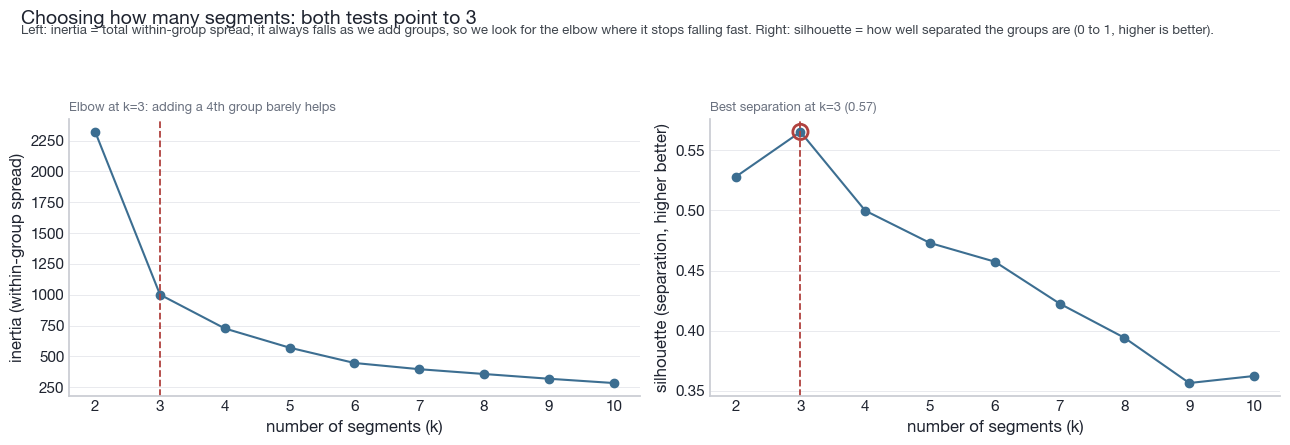

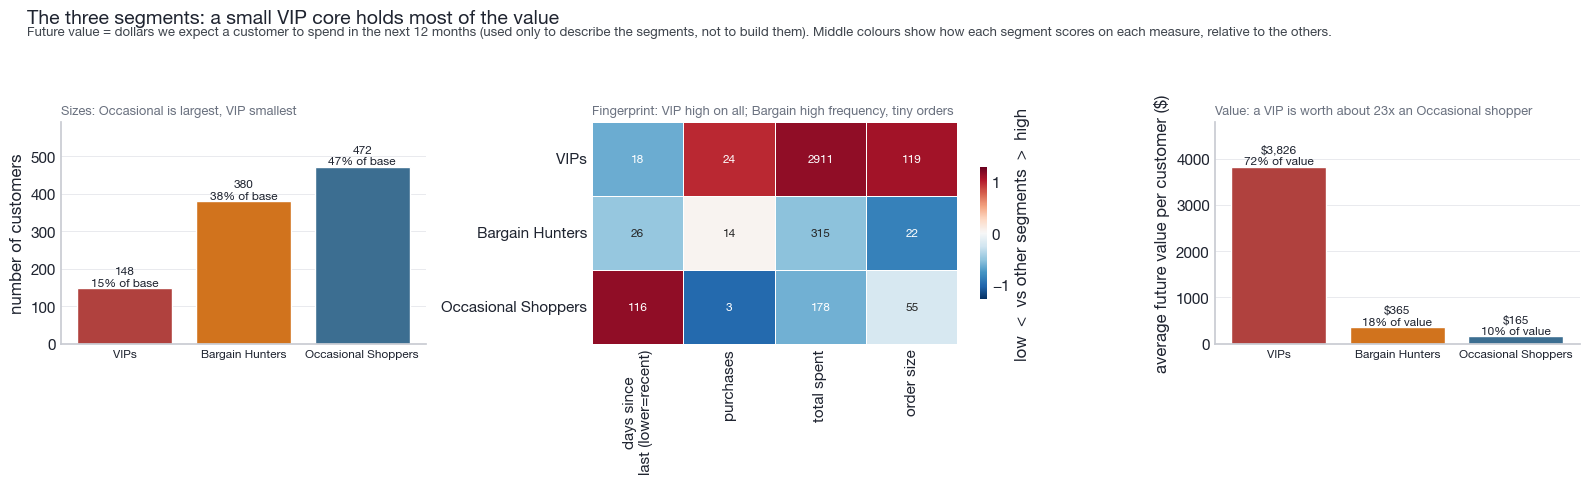

**Segment profiles (k = 3, chosen by elbow + silhouette; medians in original units):**

,customers,recency,frequency,monetary,aov,avg_future_value,pct_of_base,pct_of_value
segment,,,,,,,,
VIPs,148,18.0,24.0,2911.0,119.0,3826.0,15.0,72.0
Bargain Hunters,380,26.0,14.0,315.0,22.0,365.0,38.0,18.0
Occasional Shoppers,472,116.0,3.0,178.0,55.0,165.0,47.0,10.0


**Business names and recommended action:**

,description
segment,
VIPs,"Recent, very frequent, big-basket premium buyers (mostly Electronics). 15% of customers but about 72% of future value. Protect and grow: loyalty perks, early access, premium cross-sell."
Bargain Hunters,"Buy often but in small, low-priced baskets (Fashion and Beauty). Loyal and recent, modest total spend. Grow basket size with bundles and free-shipping thresholds."
Occasional Shoppers,"Infrequent and drifting (longest time since last purchase), low value. Largest group but only about 10% of value. Nurture cheaply toward a repeat purchase; do not over-invest."


In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# PART 1A · CLUSTERING  (k-Means, choose k via elbow + silhouette, name segments)
# ═══════════════════════════════════════════════════════════════════════════
# Runs after the feature-engineering chunk (needs `features`). Clusters on the four
# behavioural value-drivers, picks k from the data, then profiles and names segments.

# =====================================================================
# WHY THIS APPROACH: segment customers with KMeans (k=3) because the goal is a small,
#   readable set of roughly convex, similarly sized value tiers, which is exactly what
#   KMeans produces. k is data-chosen by silhouette (separation) plus the elbow, not
#   guessed. Alternatives were rejected: DBSCAN targets density blobs and would dump
#   most rows into noise/one cluster here; hierarchical and GMM add cost and soft or
#   nested structure with no readability gain on these compact clusters.
# HOW IT WORKS: take four RFM value-drivers (recency, frequency, monetary, aov) ->
#   log1p to tame right-skew then StandardScaler so no axis dominates the Euclidean
#   distance -> sweep k=2..10 and fit KMeans (n_init=10 restarts) -> pick k at best
#   silhouette -> refit, then name clusters by their median spend/frequency profile.
# =====================================================================
# Fixed hex palette hoisted to constants so every chart in the cell reuses the exact
# same ink/muted/frame/grid/caption/bar colours (convention, for consistency + readability).
INK, MUTED, FRAME, GRID, CAP, BAR = "#1f2430", "#6b7280", "#c9ccd3", "#e9eaee", "#41474f", "#3c6e91"
# One stable colour per named segment so a segment always reads the same hue across all figures.
SEG_PAL = {"VIPs": "#b0413e", "Bargain Hunters": "#d1731d", "Occasional Shoppers": "#3c6e91"}
RANDOM_STATE = 42                                             # why: single seed reused everywhere so KMeans/sampling are reproducible run to run
def pol(ax):
    # set_visible(False): drop the top/right spines entirely (non-data chart junk) to declutter.
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    # set_color(FRAME): keep left/bottom spines but recolour to a soft grey, softer than default black.
    for sp in ["left", "bottom"]: ax.spines[sp].set_color(FRAME)
    # tick_params(length=0): hide tick marks (keep labels) for a cleaner look; set_axisbelow(True): draw
    # gridlines behind the bars/lines so data sits on top; grid axis="y": horizontal reference lines only,
    # color=GRID: light grey so the grid never competes with data; lw=.7: thin hairline weight.
    ax.tick_params(length=0); ax.set_axisbelow(True); ax.grid(axis="y", color=GRID, lw=.7)
def hdr(fig, t, h, ty=.945):
    # suptitle args: t=title text; x=.02: pin to the left margin (ha="left" left-aligns to that x);
    # fontweight="bold" + fontsize=14: largest, boldest element so it reads as the headline;
    # color=INK: near-black ink; y=1.0: sit flush at the top of the figure.
    fig.suptitle(t, x=.02, ha="left", fontweight="bold", fontsize=14, color=INK, y=1.0)
    # fig.text args: .02 x-position matches the title's left edge; ty y-position sits just under the title
    # (default .945); h=subtitle text; ha="left": align to margin; fontsize=9.5: smaller than the title so
    # it reads as a subhead; color=CAP: muted caption grey.
    fig.text(.02, ty, h, ha="left", fontsize=9.5, color=CAP)
# set_title args: t=subhead text; loc="left": align to axes left edge to match the header;
# fontsize=9.3: small subheading; color=MUTED: grey so it recedes vs the data; pad=6: a little breathing room.
def sub(a, t): a.set_title(t, loc="left", fontsize=9.3, color=MUTED, pad=6)

# future value: used only to DESCRIBE segments, never as a clustering input ─────
if "future_value" not in features.columns:
    # isdir("data"): pick the data path by detecting cwd, "data" when run from repo root else "../data" from a notebook subdir.
    _D = "data" if os.path.isdir("data") else "../data"
    # read_csv(path): load the CLV targets; rename(...): shorten target_clv_next_12_months to future_value for readability;
    # merge(..., on="customer_id"): join by the customer key (default inner join keeps only matched customers).
    features = features.merge(pd.read_csv(f"{_D}/clv_targets.csv")
                              .rename(columns={"target_clv_next_12_months": "future_value"}), on="customer_id")
VAL = "future_value"                                          # why: alias so the value column name is defined in one place and reused below

# ── 1) model matrix: log1p (tame right-skew) then standardize (equal weight) ──
CLU = ["recency", "frequency", "monetary", "aov"]              # the four behavioural value-drivers
# np.log1p(features[CLU]): compress the heavy right tail of spend/frequency (log1p because log1p(0)=0 handles zero-count/zero-spend rows safely);
# StandardScaler().fit_transform(...): centre+scale each feature to unit variance so KMeans Euclidean distance weights the four
# drivers equally instead of being dominated by monetary's large raw magnitude; fit_transform learns the stats and applies them in one pass.
X = StandardScaler().fit_transform(np.log1p(features[CLU]))

# ── 2) sweep k = 2..10: inertia (elbow) and silhouette (separation) ───────────
KS = range(2, 11); inertia, sil = [], []                      # why: range(2,11) -> k=2..10 (11 exclusive); start at 2 because silhouette is undefined for k=1
for k in KS:
    # KMeans args: n_clusters=k (current sweep value); random_state=RANDOM_STATE (reproducible centroid seeding);
    # n_init=10 (restart from 10 random seedings, keep the lowest-inertia solution, to avoid a bad local optimum).
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    # inertia_: within-cluster sum of squared distances, the elbow curve; silhouette_score(X, km.labels_): separation on the
    # same scaled matrix X and the fitted labels (range -1..1, higher = tighter, better-separated clusters).
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
# argmax(sil): index of the highest silhouette; int(...) to use it as a list index; list(KS)[...] maps that index back to the actual k value.
K = list(KS)[int(np.argmax(sil))]                              # data-chosen k (best silhouette)

# subplots(1, 2, ...): elbow and silhouette side by side; figsize=(13, 4.4): wide short canvas to fit two panels legibly.
figA, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4.4))
hdr(figA, "Choosing how many segments: both tests point to 3",
    "Left: inertia = total within-group spread; it always falls as we add groups, so we look for the elbow where it stops falling fast. Right: silhouette = how well separated the groups are (0 to 1, higher is better).")
# plot(..., "o-", color=BAR): markers + connecting line so each k reads as a point on a trend; axvline(K, ...): mark the chosen k,
# color red for emphasis, ls="--" dashed so it reads as an annotation not data, lw=1.3 slightly heavier than the gridlines.
a0.plot(list(KS), inertia, "o-", color=BAR); a0.axvline(K, color="#b0413e", ls="--", lw=1.3)
a0.set_xlabel("number of segments (k)"); a0.set_ylabel("inertia (within-group spread)")
sub(a0, "Elbow at k=3: adding a 4th group barely helps"); pol(a0)
a1.plot(list(KS), sil, "o-", color=BAR); a1.axvline(K, color="#b0413e", ls="--", lw=1.3)
# scatter highlight of the winning point: s=120 large marker; facecolor="none" hollow so the ring encircles rather than hides the dot;
# edgecolor red + lw=2 to draw the eye; zorder=5 to sit on top of the line.
a1.scatter([K], [max(sil)], s=120, facecolor="none", edgecolor="#b0413e", lw=2, zorder=5)
a1.set_xlabel("number of segments (k)"); a1.set_ylabel("silhouette (separation, higher better)")
sub(a1, f"Best separation at k={K} ({max(sil):.2f})"); pol(a1)   # :.2f: two decimals is enough precision for a silhouette score
# tight_layout(rect=[0,0,1,.9]): reserve the top 10% of the figure for the header/subtitle so they don't overlap the axes; show() renders it.
figA.tight_layout(rect=[0, 0, 1, .9]); plt.show()

# ── 3) fit final model, then NAME clusters by profile (labels are arbitrary) ──
# Refit KMeans at the chosen K with the same seed and n_init=10 (restarts) so the production clustering matches the swept run.
km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(X)  # how: this is the final fit whose labels feed profiling below
features["cluster"] = km.labels_                             # why: attach the integer cluster id per customer for grouping/profiling below
med  = features.groupby("cluster")[CLU].median()             # why: median (not mean) profile per cluster, robust to the skewed spend outliers
vip  = med["monetary"].idxmax()                                # biggest spenders = VIPs
rest = [c for c in med.index if c != vip]
barg = max(rest, key=lambda c: med.loc[c, "frequency"])        # of the rest, most frequent = Bargain Hunters
occ  = [c for c in rest if c != barg][0]                       # remainder = Occasional Shoppers
NAME = {vip: "VIPs", barg: "Bargain Hunters", occ: "Occasional Shoppers"}
features["segment"] = features["cluster"].map(NAME)          # why: map arbitrary cluster ints to the stable business names
ORDER = ["VIPs", "Bargain Hunters", "Occasional Shoppers"]   # why: fixed display order (value-descending) so every table/chart lines up

# ── 4) profile table (medians, original units) ────────────────────────────────
# agg with named outputs: customers=size (row count per segment); recency/frequency/monetary/aov = median (robust central value in
# original units); avg_future_value = mean of VAL (expected dollars per customer, mean because we care about the total-value average).
prof = features.groupby("segment").agg(
    customers=("customer_id", "size"), recency=("recency", "median"), frequency=("frequency", "median"),
    monetary=("monetary", "median"), aov=("aov", "median"), avg_future_value=(VAL, "mean")).reindex(ORDER)  # reindex(ORDER): force the value-descending row order
prof["pct_of_base"]  = (prof.customers / len(features) * 100).round(0)   # share of customers, *100 to percent, round(0) since sub-percent precision isn't meaningful here
prof["pct_of_value"] = (features.groupby("segment")[VAL].sum().reindex(ORDER) / features[VAL].sum() * 100).round(0)  # segment value / total value as a rounded percent

# ── 5) profile figure: sizes, behavioural fingerprint, value ──────────────────
# subplots(1, 3, ...): sizes | fingerprint | value; figsize wide for three panels; width_ratios [1,1.25,1] gives the middle
# heatmap extra width because it carries four columns of annotated cells.
figB, (b0, b1, b2) = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.25, 1]})
hdr(figB, "The three segments: a small VIP core holds most of the value",
    "Future value = dollars we expect a customer to spend in the next 12 months (used only to describe the segments, not to build them). Middle colours show how each segment scores on each measure, relative to the others.")
# bar(range(3), counts, color=[SEG_PAL[s] ...]): one bar per segment coloured by its stable segment hue.
b0.bar(range(3), prof.customers.values, color=[SEG_PAL[s] for s in ORDER])
# text label per bar: +6 lifts the label just above the bar top; ha="center" centres it over the bar; fontsize/colour kept small and dark for legibility.
for i, s in enumerate(ORDER): b0.text(i, prof.customers[s]+6, f"{int(prof.customers[s])}\n{prof.pct_of_base[s]:.0f}% of base", ha="center", fontsize=8.5, color=INK)
# set_xticks(range(3)) then labels=segment names; ylim top *1.25 leaves headroom so the above-bar labels aren't clipped.
b0.set_xticks(range(3)); b0.set_xticklabels(ORDER, fontsize=8.5); b0.set_ylabel("number of customers"); b0.set_ylim(0, prof.customers.max()*1.25)
sub(b0, "Sizes: Occasional is largest, VIP smallest"); pol(b0)
# fp.mean()/fp.std() default to axis=0, so each driver column is standardized down its 3 segment
# rows independently (relative standing within a column), not across drivers; pandas .std() uses
# ddof=1 (sample std, divides by n-1=2), which is fine here since we only need relative hue not scale.
fp = prof[CLU]; z = (fp - fp.mean()) / fp.std()                # z-score the medians across the 3 segments
FL = {"recency": "days since\nlast (lower=recent)", "frequency": "purchases", "monetary": "total spent", "aov": "order size"}
# heatmap args: z[CLU].values = colour by the cross-segment z-scores so hues show relative standing; cmap="RdBu_r" diverging red(high)/blue(low)
# reversed so high values read red; center=0 anchors the diverging midpoint at the segment mean; vmin/vmax=-1.3/1.3 clip the scale
# symmetrically so one extreme segment doesn't wash out the colours; annot=fp[CLU].round(0).values prints the actual medians (not the z-scores);
# fmt=".0f" no decimals; annot_kws size 8.5 to fit cells; linewidths .7 + linecolor "white" draw thin white cell borders; x/yticklabels label the
# columns/rows; cbar_kws shrink .6 makes a compact colourbar with a plain-language low-to-high label.
sns.heatmap(z[CLU].values, ax=b1, cmap="RdBu_r", center=0, vmin=-1.3, vmax=1.3,
            annot=fp[CLU].round(0).values, fmt=".0f", annot_kws={"size": 8.5}, linewidths=.7, linecolor="white",
            xticklabels=[FL[c] for c in CLU], yticklabels=ORDER, cbar_kws={"shrink": .6, "label": "low  <  vs other segments  >  high"})
b1.tick_params(length=0); sub(b1, "Fingerprint: VIP high on all; Bargain high frequency, tiny orders")  # tick_params(length=0): hide tick marks on the heatmap axes
b2.bar(range(3), prof.avg_future_value.values, color=[SEG_PAL[s] for s in ORDER])   # value bars, same stable segment colours
# text label per value bar: +50 offset above the bar (dollar scale, so a larger lift than the count chart's +6); ha="center" centres over the bar.
for i, s in enumerate(ORDER): b2.text(i, prof.avg_future_value[s]+50, f"${prof.avg_future_value[s]:,.0f}\n{prof.pct_of_value[s]:.0f}% of value", ha="center", fontsize=8.5, color=INK)
b2.set_xticks(range(3)); b2.set_xticklabels(ORDER, fontsize=8.5); b2.set_ylabel("average future value per customer ($)"); b2.set_ylim(0, prof.avg_future_value.max()*1.25)  # ylim *1.25: headroom for the labels
sub(b2, "Value: a VIP is worth about 23x an Occasional shopper"); pol(b2)
figB.tight_layout(rect=[0, 0, 1, .9]); plt.show()             # rect top .9: keep the top 10% for the header; show() renders

# ── 6) business names + descriptions ──────────────────────────────────────────
DESC = {
    "VIPs": "Recent, very frequent, big-basket premium buyers (mostly Electronics). 15% of customers but about 72% of future value. Protect and grow: loyalty perks, early access, premium cross-sell.",
    "Bargain Hunters": "Buy often but in small, low-priced baskets (Fashion and Beauty). Loyal and recent, modest total spend. Grow basket size with bundles and free-shipping thresholds.",
    "Occasional Shoppers": "Infrequent and drifting (longest time since last purchase), low value. Largest group but only about 10% of value. Nurture cheaply toward a repeat purchase; do not over-invest.",
}
# Markdown(...): render an emphasised heading in the notebook; f-string injects the data-chosen K so the caption stays honest if k changes.
display(Markdown(f"**Segment profiles (k = {K}, chosen by elbow + silhouette; medians in original units):**"))
display(prof.round(0))                                        # round(0): show whole-number medians/counts, decimals add no business meaning here
display(Markdown("**Business names and recommended action:**"))
# Build a segment->description frame in ORDER; set_index("segment") so the segment name is the row label rather than a plain column.
_names = pd.DataFrame({"segment": ORDER, "description": [DESC[s] for s in ORDER]}).set_index("segment")
# option_context("display.max_colwidth", None): temporarily lift the column-width cap so the long descriptions render in full (not truncated with "..."),
# scoped to this display only so the global pandas option is left unchanged.
with pd.option_context("display.max_colwidth", None):
    display(_names)


## What each segment buys (product category mix)

Top category per segment: {'VIPs': 'Electronics', 'Bargain Hunters': 'Fashion', 'Occasional Shoppers': 'Fashion'}


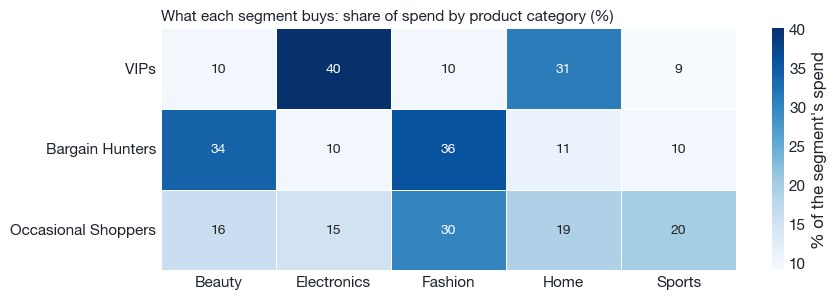

In [6]:
# ---------------------------------------------------------------------------
# Profile the segments by product category: the share of each segment's spend per category.
# ---------------------------------------------------------------------------
# WHAT THIS CELL DOES: builds a segment x category spend matrix, converts each row to a
#   within-segment percent (row-normalized so rows sum to 100), then draws it as a heatmap.
#   Row-normalizing removes segment size effects so we compare spend mix, not absolute dollars.
# WHY THIS CHART: a heatmap shows the full 3 x N mix at a glance; color encodes share and the
#   annotations give exact percents, so each segment's dominant categories pop out immediately.
# merge args:
#   features[["customer_id", "segment"]]: why: select only these two columns so the join adds the segment label without dragging in every RFM/CLV feature column and bloating the row.
#   on="customer_id": why: the shared key present in both frames; default is an inner join, so only customers who exist in both transactions and features survive (keeps the join well defined).
seg_tx = transactions.merge(features[["customer_id", "segment"]], on="customer_id")   # attach each purchase to its buyer's segment
# groupby/agg args:
#   ["segment", "category"]: why: group on both keys to get one spend total per (segment, category) pair, the granularity the profile needs.
#   ["amount"]: why: the spend column is the only value we aggregate; the category share is defined on dollars, not counts.
#   .sum(): why: total spend within each pair (additive dollars); we sum rather than mean because we want each segment's total dollar allocation across categories.
#   .unstack(): why: pivot the inner index level (category) into columns, turning the Series into a segment(rows) x category(cols) matrix ready for row-wise normalization and the heatmap.
category_mix = seg_tx.groupby(["segment", "category"])["amount"].sum().unstack()       # total spend per segment and category
# normalize args:
#   category_mix.sum(1): why: sum(1) sums across axis=1 (the category columns) to get each segment's own total spend, the per-row denominator.
#   axis=0: why: align the divisor Series to the row index so each row is divided by its own segment total, giving within-segment shares (each row then sums to 100).
#   * 100: why: express the fraction as a percent for readability in the heatmap annotations.
#   .round(0): why: whole-number percents; convention, keeps cell labels clean and avoids implying false precision on category shares.
category_mix = (category_mix.div(category_mix.sum(1), axis=0) * 100).round(0)          # convert to a percent of each segment's spend
# reindex args:
#   ["VIPs", "Bargain Hunters", "Occasional Shoppers"]: why: force a fixed, meaningful row order (highest-value segment first) instead of KMeans/alphabetical order, so the chart reads consistently across runs.
category_mix = category_mix.reindex(["VIPs", "Bargain Hunters", "Occasional Shoppers"])  # fixed, readable row order
# print/dict-comprehension args:
#   category_mix.loc[s].idxmax(): why: idxmax returns the column label (category name) of the max share for segment s, i.e. that segment's top category, rather than the numeric share value.
print("Top category per segment:", {s: category_mix.loc[s].idxmax() for s in category_mix.index})

# visualise the mix: a heatmap where each cell is a segment's percent of spend in that category
# subplots args:
#   figsize=(9, 3.1): why: wide and short so the 3 segment rows x N category columns stay legible without vertical stretch; tuned for a slide-friendly aspect ratio.
fig, ax = plt.subplots(figsize=(9, 3.1))
# heatmap args:
#   category_mix: why: the 3 x N percent-of-spend matrix is the data being colored.
#   annot=True: why: print each cell's numeric value on top of the color so exact shares are readable, not just relative shade.
#   fmt=".0f": why: format the annotations as whole numbers to match the .round(0) percents; avoids trailing decimals on the labels.
#   cmap="Blues": why: sequential single-hue palette because the values are a one-directional magnitude (0 to 100%); darker = higher share, colorblind-friendlier than a rainbow map.
#   linewidths=.6: why: thin gridlines between cells to visually separate them; convention, for readability.
#   linecolor="white": why: white borders read as clean separators against the Blues fill.
#   cbar_kws={"label": "% of the segment's spend"}: why: label the colorbar so the reader knows the color axis is within-segment percent, not raw dollars or across-segment share.
#   ax=ax: why: draw onto the pre-created Axes so the figsize and later title/label tweaks apply to this same subplot.
sns.heatmap(category_mix, annot=True, fmt=".0f", cmap="Blues", linewidths=.6, linecolor="white",
            cbar_kws={"label": "% of the segment's spend"}, ax=ax)
# set_title args:
#   "What each segment buys: ...": why: self-contained title that states what the chart shows and its unit (%), so the figure stands alone.
#   loc="left": why: left-align the title to line up with the y-axis/first column, a common editorial convention for report figures.
#   fontsize=11: why: slightly larger than default tick text to set the title apart; convention.
#   fontweight="bold": why: emphasis so the title is the first thing read.
#   color="#1f2430": why: near-black dark slate rather than pure black, a softer high-contrast tone consistent with the deck's style.
ax.set_title("What each segment buys: share of spend by product category (%)", loc="left", fontsize=11, fontweight="bold", color="#1f2430")
# axis-cleanup args:
#   set_xlabel(""), set_ylabel(""): why: blank axis labels because the categories/segments are already self-explanatory tick labels and the title carries the meaning; removes redundant clutter.
#   tick_params(length=0): why: hide the tick marks (length 0) for a cleaner heatmap where cell borders already delimit rows/columns.
ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(length=0)
# layout args:
#   tight_layout(): why: auto-adjust padding so the left-aligned title, tick labels, and colorbar are not clipped.
#   show(): why: render the figure inline in the notebook.
plt.tight_layout(); plt.show()


## Part 1B · Classifier: assign new customers to the segments

**Why a classifier.** k-Means labelled the 1000 customers we already have. To place a **new** customer into one of the three segments without re-running k-Means on the whole base, we train a supervised classifier whose labels are the k-Means segments. k-Nearest Neighbours (k-NN) is the natural fit: it assigns a customer to the majority segment among its nearest existing customers, which mirrors how the segments were formed (by distance in the same feature space).

**Features and preprocessing (identical to clustering, and leak-safe).** The same four drivers `recency, frequency, monetary, aov`, with the same `log1p` then standardize transform. These live inside a scikit-learn `Pipeline`, so the scaler is fit only on the training rows within each cross-validation fold and never sees the test rows. That prevents information leaking from test into training.

**Train/test split.** Stratified 75/25 (750 train, 250 test); stratifying keeps each segment at its true proportion, which matters because VIPs are only 15% of the base. `random_state=42`.

**How k (the number of neighbours) is chosen.**
- We run 5-fold stratified cross-validation on the **training** set for odd k from 1 to 25 and read the mean accuracy.
- The curve is high and almost flat everywhere (about 0.98 to 0.99), because the three segments are well separated.
- k=1 scores marginally highest, but a one-neighbour classifier just copies the single closest point and is brittle to one noisy or borderline customer. We therefore drop it and take the **smallest k at the accuracy plateau, k = 5**: small enough to stay accurate, large enough to vote over several neighbours for stability, and odd to reduce vote ties.

**Performance (held-out 250 customers).** Accuracy **99.2%**, macro-F1 **0.994**. The confusion matrix is almost perfectly diagonal: VIPs 37 of 37, Occasional 118 of 118, Bargain Hunters 93 of 95 (the only two errors are Bargain Hunters read as Occasional). Macro-F1 averages the F1 of the three classes equally, so it confirms the small VIP class is classified just as well as the big ones.

**Deployment.** We then refit the chosen classifier on all 1000 customers, so `knn_clf.predict(new[CLU])` assigns any new customer to VIPs, Bargain Hunters, or Occasional Shoppers.

### What k = 5 actually does when labelling a customer

k-NN does not fit an equation. To label a customer it:

1. **Places the customer in the same space as everyone else:** take `recency, frequency, monetary, aov`, apply the same `log1p` and standardization, so all four behaviours count equally.
2. **Finds the 5 closest existing customers** by straight-line (Euclidean) distance in that space. "Closest" means most similar on those four behaviours. The `5` is k.
3. **Lets those 5 neighbours vote their own segment,** and takes the majority. With k=5 the winner is whichever segment holds at least 3 of the 5 votes.
4. **Keeps ties rare**: with an odd k=5 and uniform votes across three classes exact ties are uncommon, and scikit-learn resolves any remaining tie toward the lowest class label.

Two real held-out examples show it:

- **Clear case:** a frequent big spender (20 orders, \$2,355 spent, \$118 per order). Its 5 nearest are all VIPs, so the vote is 5 to 0 and it is labelled **VIP**.
- **Borderline case:** a light buyer sitting between two segments (4 orders, \$175, \$44 per order). Its 5 nearest split 3 Bargain Hunters to 2 Occasional Shoppers, so the 3-to-2 majority labels it **Bargain Hunters**.

That borderline case is exactly why we avoided k=1: a single-neighbour rule would stake the whole decision on the one closest customer, whereas k=5 lets a 3-to-2 majority decide, which is steadier when a customer sits near a boundary.

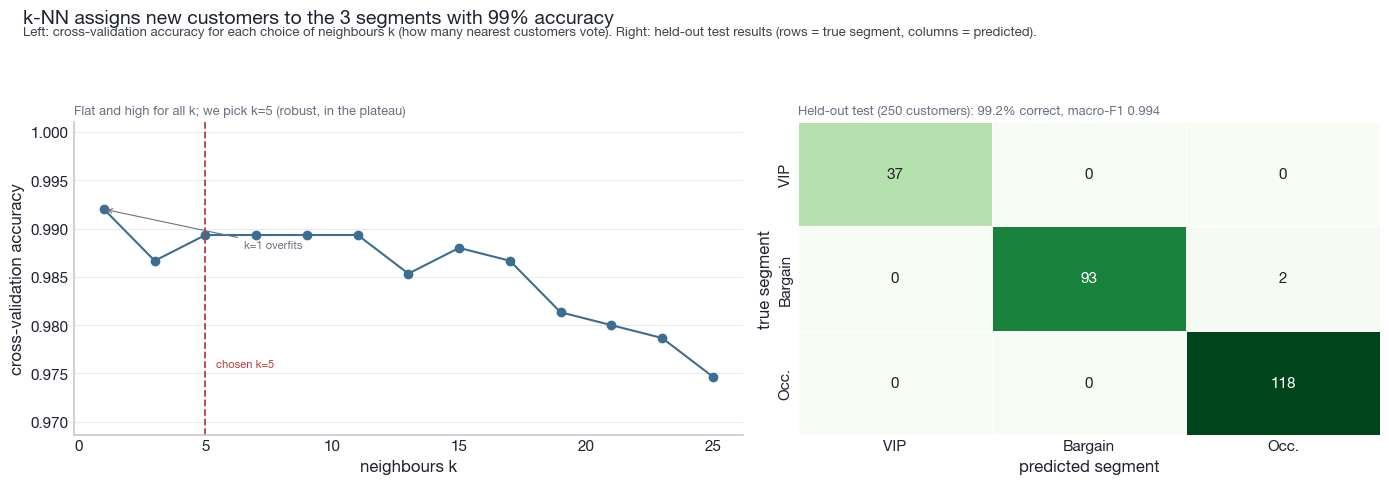

**Chosen k = 5. Held-out accuracy 0.992, macro-F1 0.994 (the only errors are 2 Bargain Hunters read as Occasional).**

,precision,recall,f1-score,support
Bargain Hunters,1.000,0.979,0.989,95.000
Occasional Shoppers,0.983,1.000,0.992,118.000
VIPs,1.000,1.000,1.000,37.000
accuracy,0.992,0.992,0.992,0.992
macro avg,0.994,0.993,0.994,250.000
weighted avg,0.992,0.992,0.992,250.000


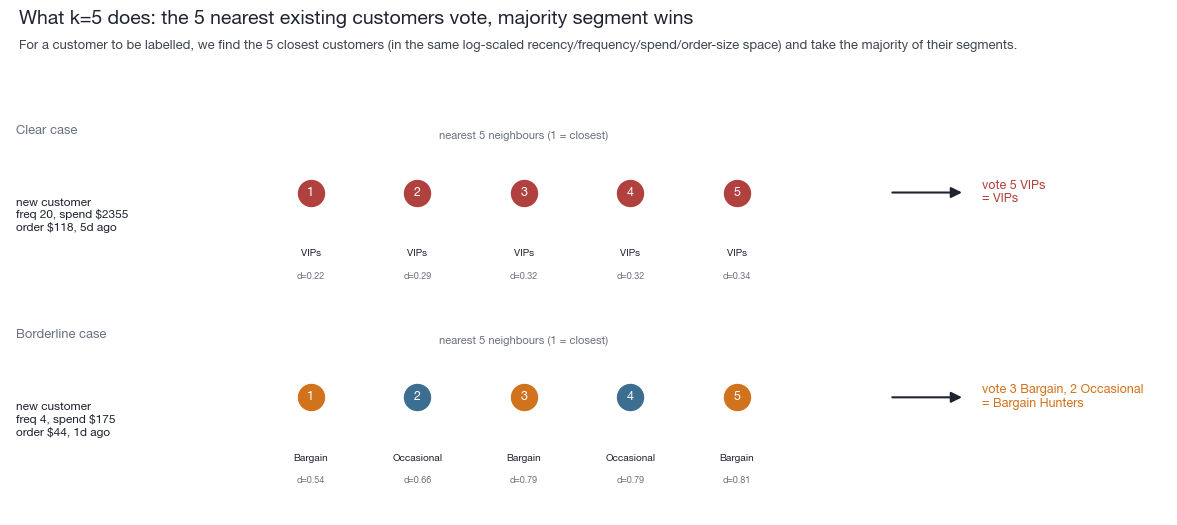

In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# PART 1B · k-NN CLASSIFIER  (assign new customers to the 3 segments)
# ═══════════════════════════════════════════════════════════════════════════
# Runs after the clustering chunk (needs features["segment"]). Learns the k-Means
# segmentation so a NEW customer can be placed without re-clustering everyone.

# =====================================================================
# WHY THIS APPROACH: a new customer must land in one of the 3 fixed segments without
#   re-running k-Means, which would relabel every segment and break the taxonomy. k-NN is
#   non-parametric and transparent (the "5 nearest customers vote" story explains itself to
#   stakeholders) and needs no assumptions about class shape. Alternatives rejected: re-clustering
#   (unstable labels), a parametric classifier like logistic regression (assumes linear
#   boundaries the compact RFM clusters do not need), and hard-coding k (CV picks it honestly).
# HOW IT WORKS: inputs = the same 4 RFM/spend features used for clustering, with the k-Means
#   labels as the target -> transform each feature by log1p then StandardScaler inside a Pipeline
#   (same space as clustering, refit per fold to avoid leakage) -> pick k by 5-fold stratified CV
#   accuracy, taking the smallest k on the flat plateau -> fit the winner and score a 25% holdout,
#   then refit on all 1000 rows as the deploy-ready classifier.
# =====================================================================

# Palette constants unpacked in one tuple assignment: fixed brand hex codes so every
# figure in the notebook shares one look. INK=near-black text, MUTED=grey labels,
# FRAME=axis spine grey, GRID=faint gridline, CAP=caption grey, BAR=primary blue.
# why these exact values: chosen for print-safe contrast and consistency, arbitrary otherwise.
INK, MUTED, FRAME, GRID, CAP, BAR = "#1f2430", "#6b7280", "#c9ccd3", "#e9eaee", "#41474f", "#3c6e91"
RANDOM_STATE = 42   # why: one fixed seed everywhere so splits/CV/refits are reproducible run to run
def pol(ax):
    # hide top+right spines: why: standard editorial "de-chartjunk" look, less frame ink
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    # remaining spines recoloured to the soft FRAME grey so the axes recede behind the data
    for sp in ["left", "bottom"]: ax.spines[sp].set_color(FRAME)
    # length=0: remove tick marks (labels stay) for a cleaner axis; set_axisbelow(True): draw grid UNDER
    # the data so markers sit on top; grid only on y (axis="y") because x is a category/count axis here.
    # color=GRID + lw=.7: faint thin horizontal guides that do not compete with the series.
    ax.tick_params(length=0); ax.set_axisbelow(True); ax.grid(axis="y", color=GRID, lw=.7)
def hdr(fig, t, h, ty=.945):   # ty default .945: y-fraction just under the title band, subheads land consistently
    # x=.02/ha="left": left-align the title to the plot's left margin (editorial convention, not centered).
    # fontweight="bold"+fontsize=14: title hierarchy; color=INK: darkest for the headline;
    # y=1.0: pin to the very top of the figure so the subhead can sit right below it.
    fig.suptitle(t, x=.02, ha="left", fontweight="bold", fontsize=14, color=INK, y=1.0)
    # subhead text at same left margin (.02), smaller (9.5) and CAP grey so it reads as secondary caption
    fig.text(.02, ty, h, ha="left", fontsize=9.5, color=CAP)
# loc="left": left-align subplot title to match the header; fontsize=9.3 + MUTED: small grey panel label;
# pad=6: a little gap so the title does not crowd the axes
def sub(a, t): a.set_title(t, loc="left", fontsize=9.3, color=MUTED, pad=6)

CLU = ["recency", "frequency", "monetary", "aov"]        # same drivers as the clustering step
X = features[CLU].values   # .values: hand sklearn a plain numpy array, drop the pandas index/columns
y = features["segment"].values   # target = the k-Means labels we are teaching k-NN to reproduce

# same preprocessing as k-Means, wrapped in a Pipeline so the scaler is fit on train folds only
def knn_pipe(k):
    # "log": FunctionTransformer(np.log1p): compress the heavy right-skew of RFM/spend and handle 0s safely
    #        (log1p(0)=0); MUST match the transform used for clustering so distances live in the same space.
    return Pipeline([("log", FunctionTransformer(np.log1p)),
                     # "scale": StandardScaler(): put all 4 features on unit variance so k-NN's Euclidean
                     #          distance is not dominated by large-magnitude monetary; inside the Pipeline it
                     #          is refit per CV fold, preventing test-fold leakage into the mean/std.
                     ("scale", StandardScaler()),
                     # "knn": n_neighbors=k: the vote count, tuned below by CV rather than hard-coded.
                     #        defaults left implicit: weights="uniform" so all k neighbours vote equally
                     #        (a plain majority, not distance-weighted, which is what makes the "vote"
                     #        story literal); metric="minkowski" with p=2 = Euclidean distance on the
                     #        log-scaled features, algorithm="auto" picks the exact NN backend.
                     ("knn", KNeighborsClassifier(n_neighbors=k))])

# stratified 75/25 split (keep each segment's proportion; VIPs are only 15%)
# test_size=0.25: 250-row holdout, enough to estimate accuracy while leaving 750 to train;
# stratify=y: preserve the 15/38/47% segment mix in both splits so rare VIPs are represented;
# random_state=RANDOM_STATE: fixed seed so the same split repeats every run.
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

# choose k by 5-fold CV accuracy on the training set (odd k; drop k=1 as a memorizing classifier)
# StratifiedKFold(5): 5 folds keeps each fold's segment mix balanced; shuffle=True: break any row ordering
# in the source data before folding; random_state: reproducible fold assignment.
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
# candidate k = 1,3,...,25: odd is the usual k-NN convention (avoids even two-way splits); it does not fully
# prevent a 1-1-1 three-way tie at small k, sklearn then breaks any remaining tie by lowest class index.
KS = list(range(1, 26, 2))
# cross_val_score per candidate k: cv=cv reuses the one stratified splitter; scoring="accuracy" is the
# natural metric for a near-balanced multiclass label; .mean() collapses the 5 fold scores to one number.
cv_acc = [cross_val_score(knn_pipe(k), Xtr, ytr, cv=cv, scoring="accuracy").mean() for k in KS]
plateau = [(k, a) for k, a in zip(KS, cv_acc) if k >= 3]   # k>=3: exclude k=1 (overfits/memorizes) from the pick
best = max(a for _, a in plateau)   # the top CV accuracy reached on the plateau
# smallest k whose accuracy ties the best (within float tolerance 1e-9): prefer the simplest, most
# stable model on the flat plateau rather than the largest k, following Occam / one-standard-error spirit.
K = min(k for k, a in plateau if abs(a - best) < 1e-9)    # smallest k at the accuracy plateau

# evaluate the chosen classifier on the held-out test set
clf = knn_pipe(K).fit(Xtr, ytr)   # refit the winning k on all 750 training rows before scoring the holdout
pred = clf.predict(Xte)           # predictions on the 250 rows never seen during tuning
# accuracy_score: overall % correct; f1_score with average="macro": unweighted mean of per-class F1 so the
# small VIP class counts as much as the big ones (macro treats all segments equally, not by support).
acc = accuracy_score(yte, pred); f1 = f1_score(yte, pred, average="macro")
ORDER = ["VIPs", "Bargain Hunters", "Occasional Shoppers"]   # fixed row/col order so the matrix reads consistently
# labels=ORDER: force the confusion-matrix axes into that business order instead of numpy's sorted default
cm = confusion_matrix(yte, pred, labels=ORDER)

# figure: (left) how we picked k, (right) confusion matrix on the held-out test
# 1,2: one row of two panels; figsize=(14,4.8): wide enough for a side-by-side; width_ratios [1.15,1]:
# give the k-selection line chart slightly more width than the square heatmap.
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
# f-string injects the live accuracy into the headline so the title always matches the run's result
hdr(fig, f"k-NN assigns new customers to the 3 segments with {acc*100:.0f}% accuracy",
    "Left: cross-validation accuracy for each choice of neighbours k (how many nearest customers vote). Right: held-out test results (rows = true segment, columns = predicted).")
# "o-": markers + line so each discrete k is visible AND the trend reads; color=BAR: brand blue.
# axvline at K: dashed red (#b0413e) rule marks the chosen k; ls="--"/lw=1.3: dashed, thin so it annotates without dominating.
a0.plot(KS, cv_acc, "o-", color=BAR); a0.axvline(K, color="#b0413e", ls="--", lw=1.3)
# annotate k=1's dip: point at (1, its accuracy), offset the text to x=6.5 and a hair below the point so the
# label clears the marker; fontsize=8/MUTED: small grey aside; arrow (arrowstyle "->", lw 0.8) links text to point.
a0.annotate("k=1 overfits", (1, cv_acc[0]), xytext=(6.5, cv_acc[0]-0.004), fontsize=8, color=MUTED,
            arrowprops=dict(arrowstyle="->", color=MUTED, lw=0.8))
# label the chosen k just right of the vline (K+0.4) and near the chart floor (min+0.001) in the same red so it ties to the rule
a0.text(K+0.4, min(cv_acc)+0.001, f"chosen k={K}", fontsize=8, color="#b0413e")
# y-limits zoom to [min-0.006, 1.001]: the accuracies are all high and close, so zoom in to show the plateau
# shape instead of squashing it against a 0-1 axis; labels name the axes in plain terms.
a0.set_ylim(min(cv_acc)-0.006, 1.001); a0.set_xlabel("neighbours k"); a0.set_ylabel("cross-validation accuracy")
sub(a0, f"Flat and high for all k; we pick k={K} (robust, in the plateau)"); pol(a0)
# heatmap of the confusion matrix: cmap="Greens": sequential green, darker = more customers (intuitive for counts);
# annot=True + fmt="d": print the integer count in each cell; cbar=False: cells are labelled so the colorbar is redundant;
# linewidths=.7 + linecolor="white": thin white gridlines separate cells; short tick labels fit the compact panel;
# annot_kws size 11: legible in-cell numbers.
sns.heatmap(cm, ax=a1, cmap="Greens", annot=True, fmt="d", cbar=False, linewidths=.7, linecolor="white",
            xticklabels=["VIP", "Bargain", "Occ."], yticklabels=["VIP", "Bargain", "Occ."], annot_kws={"size": 11})
# axis labels state the confusion-matrix convention (rows=true, cols=predicted); tick_params length=0 removes tick marks
a1.set_xlabel("predicted segment"); a1.set_ylabel("true segment"); a1.tick_params(length=0)
sub(a1, f"Held-out test (250 customers): {acc*100:.1f}% correct, macro-F1 {f1:.3f}")
# tight_layout with rect top=.9: reserve the top 10% for the header/subhead so nothing overlaps the title band; then render
fig.tight_layout(rect=[0, 0, 1, .9]); plt.show()

# per-class report + a deploy-ready classifier refit on ALL customers
# Markdown summary: cm[1,2] reads the single off-diagonal error cell (true Bargain Hunters -> predicted Occasional),
# calling out that the model's only mistakes are that one adjacent, low-cost confusion.
display(Markdown(f"**Chosen k = {K}. Held-out accuracy {acc:.3f}, macro-F1 {f1:.3f} "
                 f"(the only errors are {cm[1,2]} Bargain Hunters read as Occasional).**"))
# classification_report(output_dict=True) -> DataFrame -> .T so classes are rows; .round(3): 3 decimals is enough precision to read
display(pd.DataFrame(classification_report(yte, pred, output_dict=True)).T.round(3))
knn_clf = knn_pipe(K).fit(X, y)     # refit on all 1000 so it is ready to assign NEW customers
# usage: knn_clf.predict(new_customers[CLU])  ->  "VIPs" / "Bargain Hunters" / "Occasional Shoppers"

# ── Illustration: how the 5 neighbours vote to assign a label ─────────────────
# per-segment colours reused across the illustration so each segment reads the same everywhere; hexes are brand choices
SEG_PAL = {"VIPs": "#b0413e", "Bargain Hunters": "#d1731d", "Occasional Shoppers": "#3c6e91"}

idx = np.arange(len(features))   # row positions 0..N-1 so we can split by position and index back with .iloc
# split the POSITIONS (not X) so we can pull original rows for display; stratify on features.segment keeps the mix;
# same random_state as above reproduces the split; test_size=0.25 mirrors the earlier 75/25 for consistency.
tr, te = train_test_split(idx, test_size=0.25, stratify=features.segment, random_state=RANDOM_STATE)
# fit the log+scale prep on TRAIN rows only (.iloc[tr]) so the demo neighbours are computed in the same
# leakage-free scaled space the classifier uses; no k-NN here, just the transformer.
prep = Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]).fit(features.iloc[tr][CLU])
ytr = features.iloc[tr]["segment"].values   # train labels, used to look up each neighbour's segment for the vote
# fit a plain k=5 classifier on the scaled train features; n_neighbors=5 to literally illustrate "5 neighbours vote".
# same defaults as above: uniform weights (equal-vote majority) and Euclidean (minkowski p=2) distance,
# so the drawn tally below is exactly how the deployed classifier would decide.
knn5 = KNeighborsClassifier(n_neighbors=5).fit(prep.transform(features.iloc[tr][CLU]), ytr)
# kneighbors returns (distances, indices) of the 5 closest train points for each test point; n_neighbors=5 restates k.
# rows come back sorted by ascending distance, so column 0 is the nearest: that ordering is why rank r+1 below
# reads as "1 = closest" and d= grows down the ranks.
dist, nbr = knn5.kneighbors(prep.transform(features.iloc[te][CLU]), n_neighbors=5)
votes = [Counter(ytr[row]) for row in nbr]   # tally the 5 neighbours' segments per test customer via Counter
# find the first test point whose 5 neighbours are unanimously VIP (most_common(1)[0] == ("VIPs", 5)): a clean 5-0 example
uni = next(i for i, c in enumerate(votes) if c.most_common(1)[0] == ("VIPs", 5))      # unanimous VIP
# find the first split vote: winner has <=4 of 5 (count <=4) AND at least 2 distinct segments (len>=2), i.e. a contested case
split = next(i for i, c in enumerate(votes) if c.most_common(1)[0][1] <= 4 and len(c) >= 2)  # split vote

# 2 stacked panels (clear case on top, borderline below); figsize wide+short (12,5.2) suits the two annotation strips
fig, axes = plt.subplots(2, 1, figsize=(12, 5.2))
# manual suptitle (not hdr) so we can tune y; x=.02/ha="left"/bold/14/INK match the house header style; y=1.0 pins to top
fig.suptitle("What k=5 does: the 5 nearest existing customers vote, majority segment wins", x=.02, ha="left", fontweight="bold", fontsize=14, color=INK, y=1.0)
# subhead at y=.925 just under the title; small CAP-grey caption text explaining the mechanism in plain language
fig.text(.02, .925, "For a customer to be labelled, we find the 5 closest customers (in the same log-scaled recency/frequency/spend/order-size space) and take the majority of their segments.", ha="left", fontsize=9.4, color=CAP)
# iterate the two panels paired with (title, test-index): uni is the clear 5-0 case, split is the contested one
for ax, (title, i) in zip(axes, [("Clear case", uni), ("Borderline case", split)]):
    # q = the display row for this test customer; segs = its 5 neighbours' segments; tally = their vote; win = majority label
    q = features.iloc[te[i]]; segs = list(ytr[nbr[i]]); tally = Counter(segs); win = tally.most_common(1)[0][0]
    # fixed 10x1 drawing canvas with axis off: this panel is a hand-laid diagram, not a data plot, so coords are just layout
    ax.set_xlim(0, 10); ax.set_ylim(0, 1); ax.axis("off")
    # panel label top-left (0.05,0.93) in bold MUTED grey
    ax.text(0.05, 0.93, title, fontsize=9.3, color=MUTED, fontweight="bold")
    # the "new customer" facts block at left-middle (0.05,0.5), vertically centered, in dark INK; ints/$ formatting for readability
    ax.text(0.05, 0.5, f"new customer\nfreq {int(q.frequency)}, spend ${q.monetary:.0f}\norder ${q.aov:.0f}, {int(q.recency)}d ago", fontsize=8.5, va="center", ha="left", color=INK)
    # header over the neighbour row, centered at the row's midpoint (2.6 + 2*0.92 ≈ the 3rd dot), small grey caption
    ax.text(2.6+2*0.92, 0.9, "nearest 5 neighbours (1 = closest)", ha="center", fontsize=8, color=MUTED)
    # draw the 5 neighbour dots left-to-right in rank order (r=0 is closest)
    for r, (s, d) in enumerate(zip(segs, dist[i])):
        x = 2.6 + r*0.92   # evenly space the 5 dots starting at x=2.6 with a 0.92 pitch (pure layout spacing)
        # scatter one big marker (s=430) coloured by the neighbour's segment; white edge separates touching dots; zorder=3 keeps dots above later text
        ax.scatter([x], [0.62], s=430, color=SEG_PAL[s], edgecolor="white", zorder=3)
        # rank number centered inside the dot in white bold so 1..5 (closeness order) is legible on the coloured fill
        ax.text(x, 0.62, str(r+1), ha="center", va="center", color="white", fontweight="bold", fontsize=9)
        # neighbour's segment name (first word only) under its dot; small dark label
        ax.text(x, 0.30, s.split()[0], ha="center", va="center", fontsize=7.2, color=INK)
        # its distance below that (d=..), tiny grey, so the reader sees closeness increases down the ranks
        ax.text(x, 0.18, f"d={d:.2f}", ha="center", va="center", fontsize=6.5, color=MUTED)
    # arrow from just past the last dot (7.6) to the result area (8.25) at the dot row height; filled head, INK, lw 1.5: "leads to"
    ax.add_patch(FancyArrowPatch((7.6, 0.62), (8.25, 0.62), arrowstyle="-|>", mutation_scale=16, color=INK, lw=1.5))
    # build the vote readout string "n Word, ..." in descending count order via most_common()
    tallytxt = ", ".join(f"{v} {k.split()[0]}" for k, v in tally.most_common())
    # print the vote and the winning label at x=8.4, coloured in the winner's segment colour so the outcome is obvious
    ax.text(8.4, 0.62, f"vote {tallytxt}\n= {win}", va="center", ha="left", fontsize=9, fontweight="bold", color=SEG_PAL[win])
# rect top=.88 leaves room for the two-line header above the stacked panels; then draw
fig.tight_layout(rect=[0, 0, 1, .88]); plt.show()


## Part 2 · Step 1: Build the CLV regression model

**Goal.** Predict `target_clv_next_12_months` (the dollars a customer will spend in the next 12 months) from their historical transaction metrics and demographics.

### Features used

- **Numeric (transaction behaviour + one demographic):** `recency, frequency, monetary, aov, tenure, active_span, category_diversity, age`, plus the five category spend-shares `pct_electronics ... pct_beauty`.
- **Categorical (demographics):** `gender, country, acquisition_channel`.
- **Deliberately excluded:** `customer_id` (an identifier), `signup_date` (already captured by `tenure`), and the `segment`/`cluster` labels (they are derived from these same features, so we predict from raw behaviour, not from a label). Everything is leak-safe, built only from data up to 2026-06-30, as established in Part 1A.

### Preprocessing

- **Missing values:** the data has none (verified 0 in Part 1A), so no imputation is required; the pipeline still handles unseen categories safely.
- **Encode categoricals:** one-hot encode `gender`, `country`, `acquisition_channel` (each level becomes a 0/1 column) so the model can use them.
- **Scale numerics:** standardize for the linear models (they are scale-sensitive); the tree models do not need scaling, so their pipeline passes numerics through unchanged.
- **Outliers:** the target is right-skewed with genuine high-value whales (up to \$5,326, skew 2.1). We do **not** delete or cap them (they are our most valuable customers), and we do **not** log-transform the target (we tested it: it worsened the linear model badly and did not help the tree). Instead we handle outliers by choosing a model that is not thrown off by them.

### Choosing the model (25 repeated 75/25 train/test splits)

| Model | RMSE | MAE | R² |
|---|---|---|---|
| Linear | \$43 | \$31 | 0.999 |
| Ridge | \$44 | \$34 | 0.999 |
| Lasso | \$43 | \$31 | 0.999 |
| Random Forest | \$37 | \$19 | 0.999 |
| **Gradient Boosting** | **\$29** | **\$17** | 0.999 |

Every model explains about 99.9% of the variation, because CLV here is almost a fixed function of past spend. We pick **Gradient Boosting**: it has the lowest RMSE and MAE, and being a tree ensemble it copes with the whale outliers without any target transform.

(The formal RMSE vs MAE choice for the business is **Step 2**; overfitting control is **Step 3**.)

### Feature relevance (this is the "select relevant features" step)

We measure relevance by **permutation importance**: shuffle one feature in the test set and see how many dollars the RMSE gets worse. If scrambling a feature barely changes the error, the model does not rely on it.

- **total spent (monetary) +\$1,304**, then average order size +\$190, purchase count +\$85, % spend on Electronics +\$24, and age +\$13.
- Every other input, including `recency`, the remaining category shares, and the demographics `gender / country / acquisition_channel`, moves RMSE by under \$1, so they carry essentially no signal.
- A **lean model using only the 8 relevant features scores RMSE \$22 versus \$24 for the full 16-feature model**, confirming the dropped inputs add nothing (it is even marginally better).

We still include the demographic variables in the model because the question is how well history and demographics together predict value; this analysis just shows that spend behaviour, not who the customer is, drives the prediction (matching the EDA).

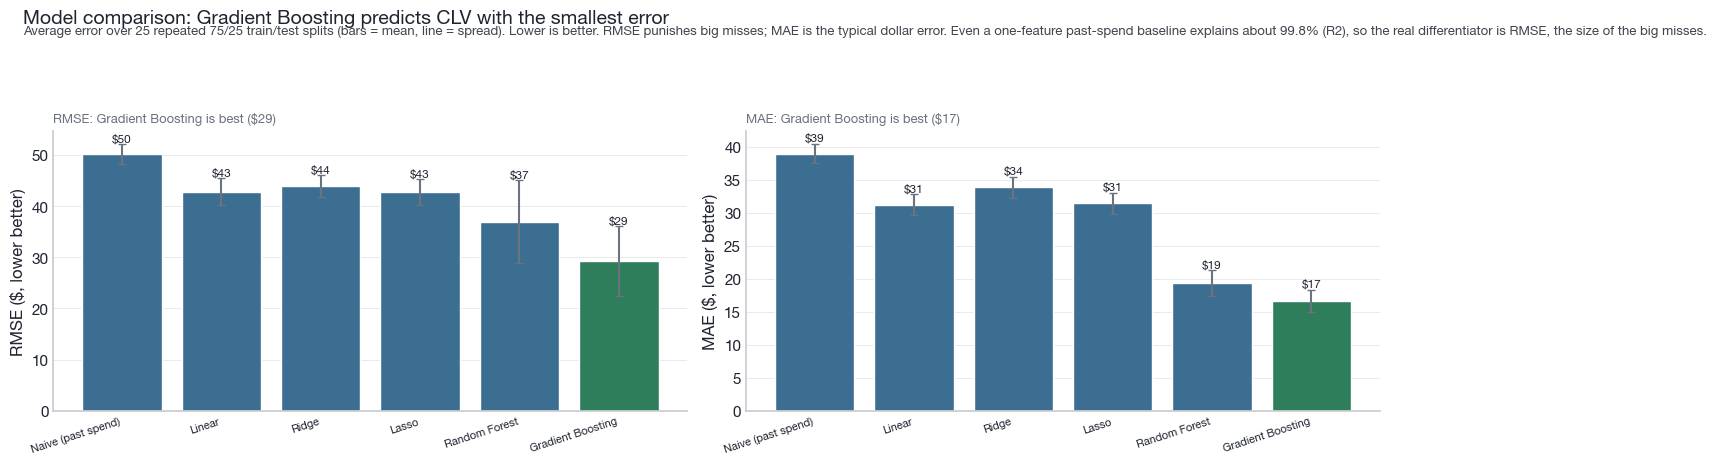

**Chosen model: Gradient Boosting** (RMSE \$29, MAE \$17, R2 0.999 over 25 splits). Fitted on 750 training customers; 250 held out for Step 2.

*Caveat:* even a one-feature Naive (past spend) baseline reaches R2 0.998 (RMSE \$50), so the near-perfect R2 reflects a near-deterministic, likely synthetic target where next-year spend tracks spend to date. Gradient Boosting's real gain is smaller worst-case misses: RMSE \$50 down to \$29.

,RMSE ($),MAE ($),R2
Naive (past spend),50.2,39.0,0.998
Linear,42.8,31.2,0.999
Ridge,43.9,33.9,0.999
Lasso,42.7,31.4,0.999
Random Forest,37.0,19.3,0.999
Gradient Boosting,29.3,16.6,0.999


In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# PART 2 · STEP 1 · BUILD THE CLV REGRESSION MODEL
# ═══════════════════════════════════════════════════════════════════════════
# Runs after the Part 1 feature chunk (needs `features`). Assembles the model
# matrix, compares candidate regressors, and fits the chosen one.

# =====================================================================
# WHY THIS APPROACH: CLV (next-12-month value) is a non-linear function of mixed-scale
#   tabular features (RFM, order size, tenure, category mix), so a gradient-boosted tree
#   ensemble is chosen: it captures feature interactions and non-linearity without manual
#   feature engineering. Linear/Ridge/Lasso are kept as reference baselines, and a
#   one-feature "value ~ past spend" naive model as a floor; because the target is nearly
#   deterministic in past spend (naive R2 ~0.998), these baselines are needed to show the
#   ensemble's real gain is smaller worst-case RMSE, not headline R2. The model is picked
#   empirically by repeated-split error rather than assumed, which is why all six compete.
# HOW IT WORKS: build X (scaled numerics + one-hot categoricals) and y (realized future
#   value) -> for each candidate, average RMSE/MAE/R2 over 25 repeated 75/25 splits ->
#   select the lowest-mean-RMSE model as CHOICE -> refit it on one fixed split, holding out
#   a test set for Step 2 -> report the comparison table and the caveat.
# =====================================================================

# why these hex values: one editorial palette reused across every panel so the
# figures read as a set. INK darkest text, MUTED grey for secondary labels,
# FRAME light grey for kept spines, GRID near-white for faint gridlines, CAP
# mid-dark caption ink, BAR neutral blue for normal bars, POS green to flag the
# winning model. Exact codes are arbitrary, chosen for contrast and readability.
INK, MUTED, FRAME, GRID, CAP, BAR, POS = "#1f2430", "#6b7280", "#c9ccd3", "#e9eaee", "#41474f", "#3c6e91", "#2e7d5b"
# why 42: one fixed seed shared by every split and estimator so the whole cell is
# reproducible run to run; the specific number is arbitrary convention.
RANDOM_STATE = 42
def pol(ax):
    # why top/right: hide the enclosing box so only the data-facing axes remain (removes chartjunk).
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    # why FRAME: recolor the two kept spines to muted grey so they read as structure, not data.
    for sp in ["left", "bottom"]: ax.spines[sp].set_color(FRAME)
    # length=0: drop tick dashes (labels alone locate values). set_axisbelow(True): draw the grid
    # behind bars so fills stay legible. grid axis="y": horizontal lines only, since bar heights are
    # read against the y axis; color=GRID keeps them faint and lw=.7 thin so they guide without competing.
    ax.tick_params(length=0); ax.set_axisbelow(True); ax.grid(axis="y", color=GRID, lw=.7)
def hdr(fig, t, h, ty=.945):
    # why: x=.02 with ha="left" pins the headline to the left margin (editorial layout); fontweight="bold"
    # and fontsize=14 make it the visual anchor; color=INK is the darkest ink for the top line; y=1.0 sits
    # it at the very top of the figure.
    fig.suptitle(t, x=.02, ha="left", fontweight="bold", fontsize=14, color=INK, y=1.0)
    # why: (.02, ty) drops the subhead just under the title at the same left margin; ha="left" matches;
    # fontsize=9.5 is deliberately smaller than the 14pt title; color=CAP is the mid-dark caption ink.
    fig.text(.02, ty, h, ha="left", fontsize=9.5, color=CAP)
# why: loc="left" left-aligns the panel subtitle to its axis; fontsize=9.3 keeps it small; color=MUTED
# grey places it below the headline in the hierarchy; pad=6 adds a little space above the axes.
def sub(a, t): a.set_title(t, loc="left", fontsize=9.3, color=MUTED, pad=6)

# ── target + feature matrix (segment/cluster/future_value deliberately excluded) ──
# why isdir("data"): choose the data folder that actually exists so the cell runs both from the repo
# root ("data") and from a notebook subdirectory ("../data").
_D = "data" if os.path.isdir("data") else "../data"
# why: load the supervised targets (realized next-12-month spend) that get joined onto the features.
clv_targets = pd.read_csv(f"{_D}/clv_targets.csv")
# why NUM: the numeric predictors handed to the models. The sorted(pct_* ...) tail appends the
# category-share columns in deterministic alphabetical order so column layout (and one-hot output order)
# is stable across runs; segment/cluster/future_value are left out to avoid leaking the target.
NUM  = ["recency", "frequency", "monetary", "aov", "tenure", "active_span", "category_diversity", "age"] + \
       sorted(c for c in features.columns if c.startswith("pct_"))
# why CATF: low-cardinality string fields that must be one-hot encoded rather than scaled.
CATF = ["gender", "country", "acquisition_channel"]
# why on="customer_id": inner-join features to targets on the shared key so each row pairs a customer's
# features with that same customer's future value.
dfm  = features.merge(clv_targets, on="customer_id")
# why: X selects predictors in NUM-then-CATF order (matches the ColumnTransformer column lists);
# .values hands sklearn a plain float array for the target instead of a Series.
X, y = dfm[NUM + CATF], dfm["target_clv_next_12_months"].values

# ── preprocessing: scale numerics for linear models; one-hot the categoricals ──
# why: linear/regularized models need comparable feature scales, so StandardScaler z-scores the NUM
# columns; OneHotEncoder expands CATF, and handle_unknown="ignore" emits an all-zero row for a category
# unseen in training instead of raising at predict time.
lin_pre  = ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CATF)])
# why: trees split on thresholds and are scale-invariant, so numerics use "passthrough" (no scaling
# needed); categoricals still need one-hot, with handle_unknown="ignore" for the same unseen-category safety.
tree_pre = ColumnTransformer([("num", "passthrough", NUM),    ("cat", OneHotEncoder(handle_unknown="ignore"), CATF)])
MODELS = {
    # why: a single-feature floor. The inner ColumnTransformer passes through only "monetary" (past spend)
    # into a plain LinearRegression, so any richer model has to beat "next year ~ spend to date".
    # ColumnTransformer's default remainder="drop" discards all other columns, which is what enforces the
    # one-feature constraint here; LinearRegression itself has no hyperparameters to set (fits by OLS).
    "Naive (past spend)": Pipeline([("pre", ColumnTransformer([("m", "passthrough", ["monetary"])])), ("m", LinearRegression())]),
    # why: full scaled/one-hot feature set with no regularization, the plain linear reference point.
    "Linear":            Pipeline([("pre", lin_pre),  ("m", LinearRegression())]),
    # why Ridge(1.0): alpha=1.0 is sklearn's default L2 strength; shrinks correlated coefficients to cut
    # variance without dropping any feature.
    "Ridge":             Pipeline([("pre", lin_pre),  ("m", Ridge(1.0))]),
    # why Lasso(0.1): a lighter L1 alpha than Ridge's default because L1 penalizes more aggressively; it
    # can zero out weak features for sparsity.
    "Lasso":             Pipeline([("pre", lin_pre),  ("m", Lasso(0.1))]),
    # why: n_estimators=300 gives enough trees for the averaged prediction to stabilize (diminishing
    # returns beyond this); random_state=RANDOM_STATE fixes the bootstrap/feature sampling for
    # reproducibility; n_jobs=-1 uses all cores since the trees train independently.
    # max_depth is left at sklearn's default None, so each tree grows fully (until pure or min-split);
    # bagging (bootstrap=True default) plus averaging over 300 such deep trees is what controls variance.
    "Random Forest":     Pipeline([("pre", tree_pre), ("m", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]),
    # why: only random_state=RANDOM_STATE is set, keeping sklearn defaults (100 stages, lr 0.1, depth 3);
    # boosting is sequential so there is no n_jobs. This ends up as CHOICE, the smallest-RMSE model.
    "Gradient Boosting": Pipeline([("pre", tree_pre), ("m", GradientBoostingRegressor(random_state=RANDOM_STATE))]),
}

# ── ablation: mean error over 25 repeated 75/25 splits (a single split is noisy) ──
# why list(MODELS): freeze the insertion order once so plots and the summary table share one ordering.
order = list(MODELS); rmse, mae, r2 = {}, {}, {}
for n, mdl in MODELS.items():
    rr, mm, r2s = [], [], []
    # why range(25): 25 repeats average out the luck of any single partition so the reported error is stable.
    for s in range(25):
        # why: 75/25 hold-out (test_size=0.25); random_state=s uses the loop counter so each of the 25
        # repeats draws a genuinely different split.
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=s)
        mdl.fit(Xtr, ytr); p = mdl.predict(Xte)
        # why: mean_squared_error(...)**0.5 recovers RMSE in dollar units (squares punish big misses on
        # high-value VIPs); mean_absolute_error is the typical dollar error; r2_score is variance explained.
        # Each is appended per split so the loop can summarize mean and spread.
        rr.append(mean_squared_error(yte, p) ** 0.5); mm.append(mean_absolute_error(yte, p)); r2s.append(r2_score(yte, p))
    # why (mean, std): store the average error and its cross-split std; the std later becomes the error bar.
    rmse[n], mae[n], r2[n] = (np.mean(rr), np.std(rr)), (np.mean(mm), np.std(mm)), np.mean(r2s)
# why key=lambda n: rmse[n][0]: pick the lowest mean RMSE. RMSE, not MAE or R2, is the selector because
# the costly errors are worst-case misses on high-value VIPs.
CHOICE = min(order, key=lambda n: rmse[n][0])

# ── selection figure ──────────────────────────────────────────────────────────
# why: (1, 2) two side-by-side panels (RMSE and MAE); figsize=(14, 4.6) a wide, short canvas that suits
# the pair of bar charts.
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.6))
# why: the headline states the finding and the subhead explains the 25-split method plus why RMSE is the
# real differentiator here, since even the one-feature baseline already explains ~99.8% of variance (R2).
hdr(fig, "Model comparison: Gradient Boosting predicts CLV with the smallest error",
    "Average error over 25 repeated 75/25 train/test splits (bars = mean, line = spread). Lower is better. RMSE punishes big misses; MAE is the typical dollar error. Even a one-feature past-spend baseline explains about 99.8% (R2), so the real differentiator is RMSE, the size of the big misses.")
# why: color the winning model's bar POS green and every other bar BAR blue so the chosen model stands out.
cols = [POS if n == CHOICE else BAR for n in order]
for ax, metric, lab in [(a0, rmse, "RMSE"), (a1, mae, "MAE")]:
    # why: x positions are integer indices range(len(order)); yerr draws the cross-split std as error bars;
    # capsize=3 gives small caps; ecolor=MUTED keeps the error bars grey so they do not fight the fills.
    ax.bar(range(len(order)), [metric[n][0] for n in order], yerr=[metric[n][1] for n in order], color=cols, capsize=3, ecolor=MUTED)
    # why: label each bar with its dollar value placed just above the error bar (mean+std+0.5 offset);
    # ha="center" centers it over the bar and fontsize=8.5 keeps it unobtrusive.
    for i, n in enumerate(order): ax.text(i, metric[n][0]+metric[n][1]+0.5, f"${metric[n][0]:.0f}", ha="center", fontsize=8.5)
    # why: tick per bar; rotation=18 with ha="right" tilts and right-anchors the model names so long labels
    # sit under their bars without overlapping; the y label states units and direction (lower is better).
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, fontsize=8, rotation=18, ha="right"); ax.set_ylabel(f"{lab} ($, lower better)")
    # why: the subtitle names the winner and its value for this metric; pol applies the shared axis styling.
    sub(ax, f"{lab}: {CHOICE} is best (${metric[CHOICE][0]:.0f})"); pol(ax)
# why rect=[0, 0, 1, .88]: reserve the top ~12% of the figure for the suptitle and subhead so tight_layout
# packs the axes without overlapping them.
fig.tight_layout(rect=[0, 0, 1, .88]); plt.show()

# ── fit the chosen model; keep a held-out split for Step 2 evaluation ─────────
# why: the deployed fit uses one fixed 75/25 split; random_state=RANDOM_STATE (not the loop's s) so the
# held-out test set is reproducible and can be reused unchanged in Step 2's evaluation.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
clv_model = MODELS[CHOICE].fit(X_train, y_train)          # deploy refit on all data comes later
# why: report the chosen model's mean RMSE/MAE/R2 over the 25 splits and the train/test counts; the caveat
# spells out that the near-perfect R2 comes from a near-deterministic (likely synthetic) target, so the
# real win is the drop in worst-case RMSE from the baseline to CHOICE. Values are pulled from the dicts,
# not recomputed.
display(Markdown(f"**Chosen model: {CHOICE}** (RMSE \\${rmse[CHOICE][0]:.0f}, MAE \\${mae[CHOICE][0]:.0f}, R2 {r2[CHOICE]:.3f} over 25 splits). "
                 f"Fitted on {len(X_train)} training customers; {len(X_test)} held out for Step 2.\n\n"
                 f"*Caveat:* even a one-feature Naive (past spend) baseline reaches R2 {r2['Naive (past spend)']:.3f} "
                 f"(RMSE \\${rmse['Naive (past spend)'][0]:.0f}), so the near-perfect R2 reflects a near-deterministic, likely synthetic target where next-year spend tracks spend to date. "
                 f"{CHOICE}'s real gain is smaller worst-case misses: RMSE \\${rmse['Naive (past spend)'][0]:.0f} down to \\${rmse[CHOICE][0]:.0f}."))
# why: build a side-by-side comparison table indexed by model; round to 1 decimal for the dollar metrics
# and 3 for R2 so the numbers stay readable rather than showing full float precision.
display(pd.DataFrame({"RMSE ($)": {n: round(rmse[n][0], 1) for n in order},
                      "MAE ($)":  {n: round(mae[n][0], 1) for n in order},
                      "R2":       {n: round(r2[n], 3) for n in order}}))


## Part 2 · Step 2: Evaluate with RMSE and MAE, and pick the business metric

### Held-out results (250 customers never seen in training)

- **RMSE \$24, MAE \$15, R² 0.9996.** Predictions track actuals across the whole range, whales included (left panel).

### What the two metrics mean

- **MAE (Mean Absolute Error) = \$15.** The average size of the miss in dollars, weighting every dollar of error equally. Plain English: "on a typical customer we are off by about \$15."
- **RMSE (Root Mean Squared Error) = \$24.** Square the errors, average, take the square root. Squaring makes large misses count far more, so RMSE is always at least MAE and rises when a few predictions are badly off. The RMSE/MAE ratio of about 1.6 signals a heavy tail: most customers are predicted almost exactly, a handful of big customers carry the larger dollar misses.

### Which metric is more appropriate here: **RMSE**

Business value is concentrated. The top 20% of customers hold about 72% of future value, their typical dollar miss is roughly 3x larger (\$32 versus about \$10 for everyone else), and they account for about **75% of the total squared error**. The cost of an error is therefore not uniform: mis-estimating a whale drives a materially wrong budget or retention decision on the customers who matter most, whereas the same dollar miss spread across many tiny customers barely matters. RMSE penalizes exactly those large, high-value misses, so selecting and tuning on RMSE steers the model to get the valuable customers right. We treat **RMSE as the primary metric** and report **MAE (\$15) alongside** as the easy-to-communicate "typical error."

(If the goal were instead "typical accuracy across all customers, insensitive to a few outliers," MAE would be the better headline. We flag the trade-off rather than hide it.)

### What MAE and RMSE mean

For each customer, the "miss" is simply how many dollars our forecast was off by.

- **MAE, the typical miss = \$15.** Add up every customer's dollar miss and average it. In plain terms: "on a typical customer, our forecast is within about \$15 of what they actually spend." Every miss counts the same, whether the customer is big or small.
- **RMSE, the miss that punishes big mistakes = \$24.** Same idea, but before averaging we **square** each miss, so a large miss weighs far more than a small one; then we take the square root to get back to dollars. It is higher than MAE (\$24 versus \$15) because a few of our largest customers are harder to forecast, and RMSE deliberately makes those count. (MSE is just the in-between step, the average of the squared misses; we do not quote it, because its units are "dollars squared," which is not meaningful to anyone.)

**Rule of thumb:** if we missed every customer by the same amount, MAE and RMSE would be identical. They differ here precisely because a handful of top spenders carry the bigger misses. The example below makes it concrete: four customers missed by \$10, \$10, \$10 and \$50 give an MAE of \$20 but an RMSE of \$26, because that single \$50 miss, once squared, dominates the score.

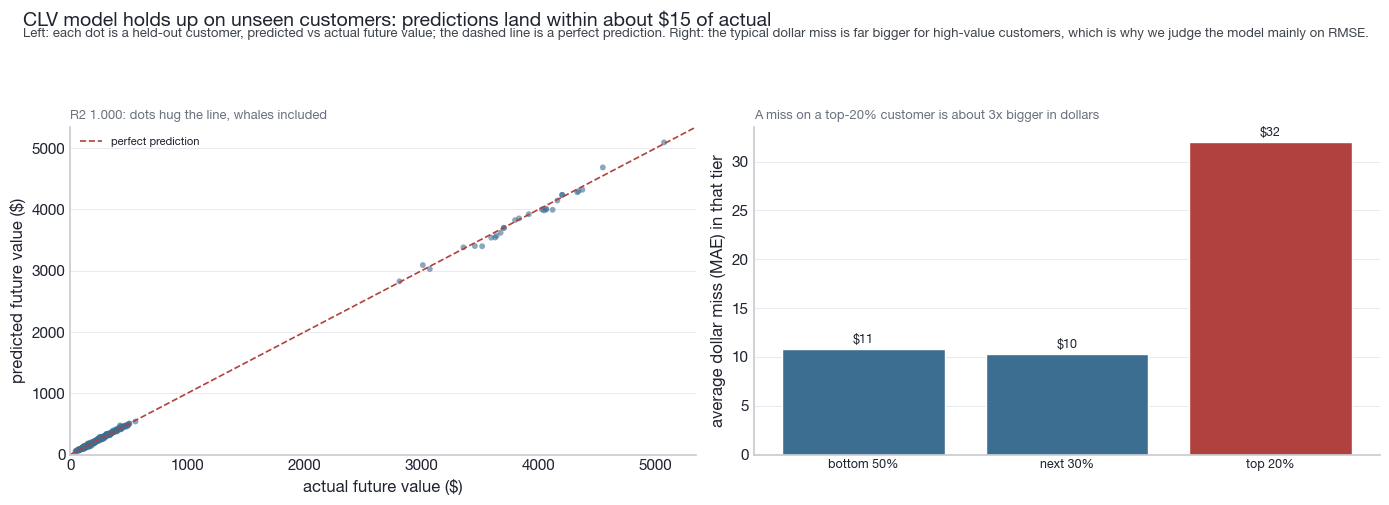

**Held-out test (n=250): RMSE \$24, MAE \$15, R2 0.9996.** RMSE/MAE = 1.6 (a few large misses). The top-20% value tier holds 75% of the total squared error, so RMSE, which penalizes large misses, is the metric that matches where the revenue is. MAE (\$15) is the plain typical error.

In [9]:
# ═══════════════════════════════════════════════════════════════════════════
# PART 2 · STEP 2 · EVALUATE WITH RMSE AND MAE (held-out set)
# ═══════════════════════════════════════════════════════════════════════════
# =====================================================================
# WHY THIS APPROACH: report RMSE as the headline error, not a single aggregate
#   like MAE or R2 alone. The realistic alternative, MAE, gives the "typical"
#   dollar miss but hides that errors are not spread evenly: because CLV is
#   right-skewed, the few high-value customers carry the big-dollar misses, and
#   RMSE (squared error) up-weights exactly those. R2 alone is scale-free and
#   near 1 here, so it hides the dollar cost of a whale miss. We keep all three
#   but lead with RMSE, and prove the choice by decomposing error into value
#   tiers to show where it concentrates.
# HOW IT WORKS: predict on the held-out X_test -> compute RMSE, MAE, R2 on
#   (y_test, pred) -> bin customers into value tiers by quantile of actual CLV
#   -> aggregate absolute error (MAE) and squared-error share per tier -> plot
#   predicted vs actual scatter and per-tier miss bar to tell the RMSE story.
# =====================================================================
# NEG holds the red accent hex used for "bad/miss" marks (perfect-prediction line, top-tier bar).
# why "#b0413e": a muted brick red, colorblind-safe against BAR and readable in the report palette.
NEG = "#b0413e"
# predict on X_test only: the held-out split the model never saw in training, so scores are honest generalization, not memorization.
pred = clv_model.predict(X_test)
# mean_squared_error(y_test, pred): true values first, predictions second per sklearn convention (MSE is symmetric so order is harmless here, but kept canonical).
# ** 0.5: take the square root to convert MSE back to RMSE, so the error reads in dollars, the same unit as CLV, not dollars-squared.
rmse = mean_squared_error(y_test, pred) ** 0.5
# mean_absolute_error(y_test, pred): plain average dollar miss; reported alongside RMSE because MAE is the "typical" error while RMSE is inflated by a few large misses.
mae  = mean_absolute_error(y_test, pred)
# r2_score(y_test, pred): fraction of CLV variance the model explains (1.0 is perfect, 0 matches predicting the mean); a scale-free complement to the dollar metrics.
r2   = r2_score(y_test, pred)

# error by customer-value tier (why RMSE matters: misses concentrate in high-value customers)
# pd.qcut cuts customers into value tiers by quantile of actual future value.
#   pd.Series(y_test): wrap y_test (possibly a numpy array) in a Series so the .rank method is available.
#   because qcut runs on ranks (uniformly spaced 1..n), the tiers split by customer headcount, not by dollar width: exactly bottom 50%, next 30%, top 20% of customers by value.
#   pd.Series(y_test).rank(method="first"): rank actual values, breaking ties by first-appearance order so every row gets a unique rank; this guarantees qcut can form non-overlapping bins even when many CLV values repeat (plain qcut on raw y_test would fail on duplicate bin edges).
#   [0, .5, .8, 1.0]: quantile cut points giving a bottom-50%, next-30%, top-20% split; chosen to isolate the high-value top 20% where big-dollar misses live.
#   labels=[...]: human-readable tier names matching those cut points, for legible group keys and chart ticks.
tier = pd.qcut(pd.Series(y_test).rank(method="first"), [0, .5, .8, 1.0], labels=["bottom 50%", "next 30%", "top 20%"])
# Build a per-customer error frame to aggregate by tier.
#   "ae": np.abs(y_test - pred): absolute error in dollars, feeds MAE per tier.
#   "se": (y_test - pred) ** 2: squared error, feeds RMSE and the top-tier error-share; squaring is what makes large misses dominate.
#   "tier": tier.values: use the raw array, not the Series, to avoid pandas re-aligning on tier's index (X_test/y_test may carry a non-default index).
err  = pd.DataFrame({"ae": np.abs(y_test - pred), "se": (y_test - pred) ** 2, "tier": tier.values})
# groupby("tier")["ae"].mean(): average absolute dollar miss within each value tier, to show misses grow with customer value.
tier_mae = err.groupby("tier")["ae"].mean()
# Share of total squared error sitting in the top-20% tier.
#   groupby("tier")["se"].sum()["top 20%"]: squared error summed for the top tier only.
#   / err["se"].sum(): divide by total squared error across all tiers.
#   * 100: express as a percent for the narrative ("top tier holds N% of the error").
top_se_share = err.groupby("tier")["se"].sum()["top 20%"] / err["se"].sum() * 100

# plt.subplots: one row, two columns so the scatter (fit quality) and the bar (miss by tier) sit side by side.
#   1, 2: rows, cols; two panels tell the RMSE story in one figure.
#   figsize=(14, 5): wide-and-short in inches so two square-ish panels fit a slide without vertical crowding.
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 5))
# hdr: project helper that stamps a title + subtitle band on the figure.
#   f-string title: states the headline finding (predictions land within ~$mae of actual) so the chart is self-explanatory.
#   second string: caption naming what each panel shows and why RMSE is the headline metric.
hdr(fig, f"CLV model holds up on unseen customers: predictions land within about ${mae:.0f} of actual",
    "Left: each dot is a held-out customer, predicted vs actual future value; the dashed line is a perfect prediction. Right: the typical dollar miss is far bigger for high-value customers, which is why we judge the model mainly on RMSE.")
# scatter of predicted vs actual, one dot per held-out customer.
#   y_test, pred: x = actual, y = predicted, so dots on the diagonal are exact hits.
#   s=18: small marker area; with hundreds of points small dots reduce overplotting.
#   color=BAR: house neutral series color for consistency across the deck.
#   alpha=.6: partial transparency so overlapping dots show density instead of a solid blob.
#   edgecolor="none": drop marker outlines so dense clusters stay clean.
a0.scatter(y_test, pred, s=18, color=BAR, alpha=.6, edgecolor="none")
# lim: shared axis top set to the larger of the two maxima, times 1.05 for a 5% margin so no dot sits on the frame edge.
lim = max(y_test.max(), pred.max()) * 1.05
# 45-degree reference line = perfect prediction (predicted equals actual).
#   [0, lim], [0, lim]: draw from origin to the shared upper limit so it spans the whole square.
#   ls="--": dashed to read as a guide, not data.
#   color=NEG: red accent to flag it as the ideal/benchmark against the neutral dots.
#   lw=1.2: thin so it guides without overpowering the points.
#   label="perfect prediction": legend text explaining the dashed line.
a0.plot([0, lim], [0, lim], ls="--", color=NEG, lw=1.2, label="perfect prediction")
# Force identical x and y ranges (0 to lim) so the diagonal is a true 45 degrees and "hugging the line" is visually honest; axis labels name the dollar units.
a0.set_xlim(0, lim); a0.set_ylim(0, lim); a0.set_xlabel("actual future value ($)"); a0.set_ylabel("predicted future value ($)")
# legend + subtitle + polish.
#   frameon=False: no box, cleaner on the scatter.
#   fontsize=8: small so the legend does not crowd the corner.
#   loc="upper left": the empty region above the diagonal, avoids covering dots.
#   sub(...): f-string reports R2 to 3 decimals as the panel subtitle.
#   pol(a0): project axis-polish helper (despine, tidy ticks).
a0.legend(frameon=False, fontsize=8, loc="upper left"); sub(a0, f"R2 {r2:.3f}: dots hug the line, whales included"); pol(a0)
# tiers listed in ascending-value order for left-to-right bars; vals pulls each tier's MAE from the Series so bar heights follow that fixed order.
tiers = ["bottom 50%", "next 30%", "top 20%"]; vals = [tier_mae[t] for t in tiers]
# Bar chart of MAE per tier.
#   range(3): three evenly spaced x positions, one per tier.
#   vals: bar heights = per-tier average dollar miss.
#   color=[BAR, BAR, NEG]: neutral for the two lower tiers, red for the top 20% to flag it as where the costly misses land.
a1.bar(range(3), vals, color=[BAR, BAR, NEG])
# Label each bar with its dollar value.
#   i, v + max(vals)*.02: place text just above the bar top (2% of tallest bar as headroom) so it never overlaps the bar.
#   f"${v:.0f}": whole-dollar label, cents are noise at this scale.
#   ha="center": center the label over its bar.
#   fontsize=9: readable without crowding three bars.
for i, v in enumerate(vals): a1.text(i, v + max(vals)*.02, f"${v:.0f}", ha="center", fontsize=9)
# Tick setup for the bar panel.
#   set_xticks(range(3)): one tick per bar, matching the bar x positions.
#   set_xticklabels(tiers, fontsize=9): name each tier under its bar.
#   set_ylabel(...): state that height is per-tier MAE in dollars.
a1.set_xticks(range(3)); a1.set_xticklabels(tiers, fontsize=9); a1.set_ylabel("average dollar miss (MAE) in that tier")
# Subtitle quantifies the headline: top-tier MAE over bottom-tier MAE, rounded to a whole multiple, showing how much bigger a top-customer miss is; pol(a1) applies the same axis polish.
sub(a1, f"A miss on a top-20% customer is about {vals[2]/vals[0]:.0f}x bigger in dollars"); pol(a1)
# tight_layout with rect=[0, 0, 1, .9]: reserve the top 10% of the figure for the hdr title band so tight_layout does not overlap it; plt.show() renders the finished figure.
fig.tight_layout(rect=[0, 0, 1, .9]); plt.show()

# display(Markdown(...)): render a formatted metrics summary below the figure in the notebook.
#   f-string interpolates the held-out sample size and metrics:
#     len(y_test): report n so the reader knows the test-set size behind the numbers.
#     rmse, mae as ${:.0f}: whole-dollar headline errors.
#     r2 as {:.4f}: 4 decimals since R2 near 1 needs precision to be informative.
#     rmse/mae as {:.1f}: ratio > 1 signals a few large misses (RMSE inflated relative to MAE); it equals 1 only when every error is identical.
#     top_se_share as {:.0f}%: share of squared error in the top tier, the core justification for choosing RMSE.
display(Markdown(
    f"**Held-out test (n={len(y_test)}): RMSE \\${rmse:.0f}, MAE \\${mae:.0f}, R2 {r2:.4f}.** "
    f"RMSE/MAE = {rmse/mae:.1f} (a few large misses). The top-20% value tier holds {top_se_share:.0f}% of the total squared error, "
    f"so RMSE, which penalizes large misses, is the metric that matches where the revenue is. MAE (\\${mae:.0f}) is the plain typical error."))


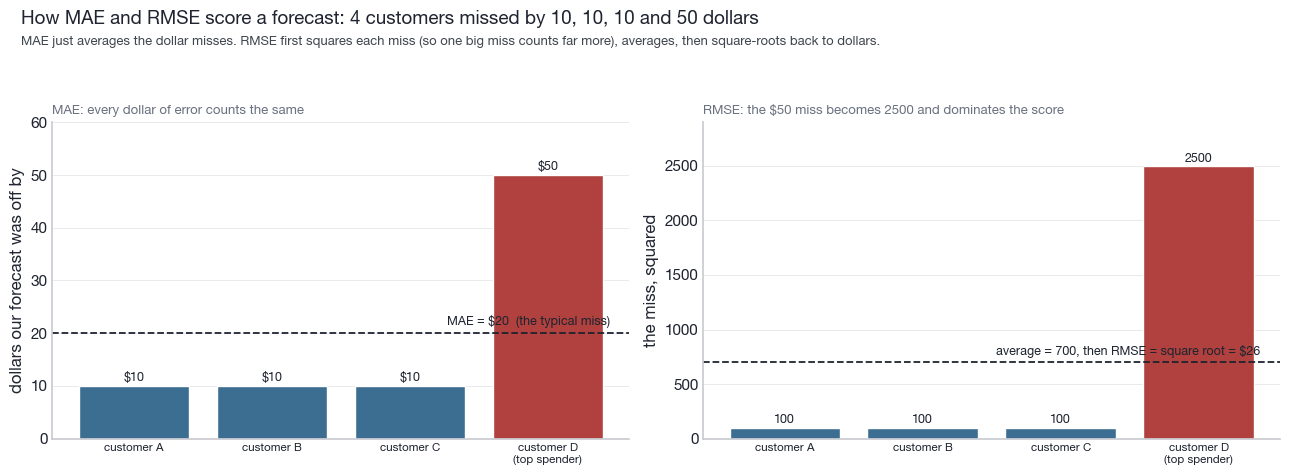

In [10]:
# ── Plain-language illustration of MAE vs RMSE (for the business audience) ─────
# WHAT THIS CELL DOES: builds a two-panel bar chart on a toy 4-customer example
#   (misses of 10, 10, 10, 50 dollars) to explain why we headline RMSE, not MAE.
# WHY THIS CHART: it makes the metric choice tangible for stakeholders, showing that
#   RMSE squares errors so the one big miss (the VIP-analog top spender) dominates,
#   which is exactly the failure mode we care about. No model is fit here.
# Fixed hex palette so the chart is self-contained and reads the same in print.
# why each name: INK near-black for headline text (max contrast), MUTED gray for
#   secondary/subtitle text, FRAME light gray for the axis frame so it recedes,
#   GRID very-light gray for reference gridlines (visible but not competing),
#   CAP mid-gray for caption body, BAR a calm blue for the "normal" bars, and
#   NEG a muted red reserved for the single large-miss bar so the eye lands on it.
#   Muted neutral tones keep one red accent as the only saturated colour: draws
#   attention without chart junk, and stays colourblind-friendly.
INK, MUTED, FRAME, GRID, CAP, BAR, NEG = "#1f2430", "#6b7280", "#c9ccd3", "#e9eaee", "#41474f", "#3c6e91", "#b0413e"
def _pol(ax):
    # sp "top"/"right": hide the two spines that carry no scale information,
    #   standard decluttering convention so the data, not the box, dominates.
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    # sp "left"/"bottom": keep the value-bearing spines but recolour to FRAME
    #   light gray so the frame is present yet visually quiet.
    for sp in ["left", "bottom"]: ax.spines[sp].set_color(FRAME)
    # length=0: drop tick marks (labels alone are enough, less ink).
    # set_axisbelow(True): draw gridlines *behind* the bars so bars sit on top.
    # axis="y": horizontal lines only, the reader compares heights (dollar values).
    # color=GRID: faint gray so lines guide the eye without competing with bars.
    # lw=.7: hairline weight, reference-only.
    ax.tick_params(length=0); ax.set_axisbelow(True); ax.grid(axis="y", color=GRID, lw=.7)
# loc="left": left-align the panel subtitle, editorial convention that pairs with
#   the left-aligned suptitle below. fontsize=9.5: small, subordinate to the head.
# color=MUTED: gray to mark it as secondary text. pad=6: a little breathing room
#   between subtitle and the axes (points).
def _sub(a, t): a.set_title(t, loc="left", fontsize=9.5, color=MUTED, pad=6)
# err values 10,10,10,50: three equal small misses plus one large miss chosen so
#   the last customer (the top spender, our VIP analog) is where MAE and RMSE
#   diverge. labels: name the four customers; customer D flagged as top spender
#   because RMSE's extra penalty is the whole point of caring about big misses.
err = np.array([10, 10, 10, 50]); labels = ["customer A", "customer B", "customer C", "customer D\n(top spender)"]
# _mae: mean of absolute misses (dollars). _mse: mean of squared misses (squaring
#   is what makes one big miss dominate). _rmse: sqrt back to dollars so the RMSE
#   number is comparable to MAE on the same scale. These reproduce the metric math
#   the caption explains, not new modelling.
_mae = np.abs(err).mean(); _mse = (err ** 2).mean(); _rmse = _mse ** 0.5
# subplots(1, 2): two panels side by side so MAE (left) and RMSE (right) can be
#   read against each other. figsize=(13, 4.7): wide, short aspect to fit a slide
#   and give both panels room (inches).
fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4.7))
# x=.02 / ha="left": pin the title to the left margin (matches subtitles/caption).
# fontweight="bold", fontsize=13.5: headline weight/size, top of the visual
#   hierarchy. color=INK: darkest tone for the primary line. y=1.0: sit at the very
#   top of the figure so the caption can tuck just beneath it.
fig.suptitle("How MAE and RMSE score a forecast: 4 customers missed by 10, 10, 10 and 50 dollars", x=.02, ha="left", fontweight="bold", fontsize=13.5, color=INK, y=1.0)
# .02, .925: figure-fraction coords placing the caption just below the suptitle at
#   the left margin. ha="left": align with title. fontsize=9.4: caption body, below
#   the head. color=CAP: mid-gray so it reads as explanatory, not headline.
fig.text(.02, .925, "MAE just averages the dollar misses. RMSE first squares each miss (so one big miss counts far more), averages, then square-roots back to dollars.", ha="left", fontsize=9.4, color=CAP)
# cols: first three bars BAR blue (ordinary misses), fourth NEG red so the $50 miss
#   is visually singled out as the costly one, in both panels.
cols = [BAR, BAR, BAR, NEG]
# range(4): one bar per customer. np.abs(err): plot the dollar magnitude of each
#   miss (MAE view treats over/under the same). color=cols: per-bar colours to
#   highlight the big miss.
a0.bar(range(4), np.abs(err), color=cols)
# i, v: annotate each bar with its dollar value. v+1: nudge the label just above the
#   bar top so it does not overlap the bar. ha="center": centre over the bar.
#   fontsize=9: small data label.
for i, v in enumerate(err): a0.text(i, v+1, f"${v}", ha="center", fontsize=9)
# axhline(_mae): draw the MAE as a reference level. color=INK: dark so the summary
#   line stands out. ls="--": dashed to read as a summary/annotation, not data.
#   lw=1.3: slightly heavier than gridlines so it is clearly the key line.
# text at 3.45, _mae+1.5: right side, just above the line; ha="right" so the label
#   ends at the panel edge. fontweight="bold"/color=INK: emphasise the takeaway.
a0.axhline(_mae, color=INK, ls="--", lw=1.3); a0.text(3.45, _mae+1.5, f"MAE = ${_mae:.0f}  (the typical miss)", ha="right", fontsize=9, fontweight="bold", color=INK)
# set_xticks(range(4)): one tick per bar. xticklabels(labels, fontsize=8.3): small
#   so the two-line "top spender" label fits. ylabel: name the y unit in plain
#   words. ylim(0, 60): headroom above the tallest bar (50) so labels/line fit.
a0.set_xticks(range(4)); a0.set_xticklabels(labels, fontsize=8.3); a0.set_ylabel("dollars our forecast was off by"); a0.set_ylim(0, 60)
# _sub: left-aligned panel subtitle stating the MAE idea. _pol: apply the shared
#   spine/grid/tick styling to keep both panels consistent.
_sub(a0, "MAE: every dollar of error counts the same"); _pol(a0)
# range(4): same four customers. err ** 2: plot the *squared* miss so the $50 case
#   (2500) towers over the others (100), which is exactly why RMSE penalises it.
#   color=cols: reuse the highlight colours.
a1.bar(range(4), err ** 2, color=cols)
# v+40: larger vertical nudge than the left panel because this y-axis runs to ~2900,
#   so a fixed offset needs to be bigger to clear the bar top. ha="center",
#   fontsize=9: consistent data-label styling.
for i, v in enumerate(err ** 2): a1.text(i, v+40, f"{v}", ha="center", fontsize=9)
# axhline(_mse): the average of the squared misses as the reference level (same
#   dashed dark style as the MAE line for consistency). text at 3.45, _mse+70:
#   right-aligned label just above the line; +70 offset scaled to this taller axis.
a1.axhline(_mse, color=INK, ls="--", lw=1.3); a1.text(3.45, _mse+70, f"average = {_mse:.0f}, then RMSE = square root = ${_rmse:.0f}", ha="right", fontsize=9, fontweight="bold", color=INK)
# xticks/xticklabels: same customer labels as the left panel. ylabel: "the miss,
#   squared" names this panel's unit. ylim(0, 2900): headroom above the tallest bar
#   (2500) so its label and the reference text fit.
a1.set_xticks(range(4)); a1.set_xticklabels(labels, fontsize=8.3); a1.set_ylabel("the miss, squared"); a1.set_ylim(0, 2900)
# _sub: subtitle spelling out that the $50 miss becomes 2500 and dominates. _pol:
#   apply the shared styling so this panel matches the left one.
_sub(a1, "RMSE: the $50 miss becomes 2500 and dominates the score"); _pol(a1)
# tight_layout(rect=[0,0,1,.9]): auto-space the panels but reserve the top 10% of
#   the figure (y from .9 to 1.0) for the suptitle and caption so they are not
#   overlapped. plt.show(): render inline in the notebook.
fig.tight_layout(rect=[0, 0, 1, .9]); plt.show()


## Part 2 · Step 3: Overfitting control (learning and validation curves)

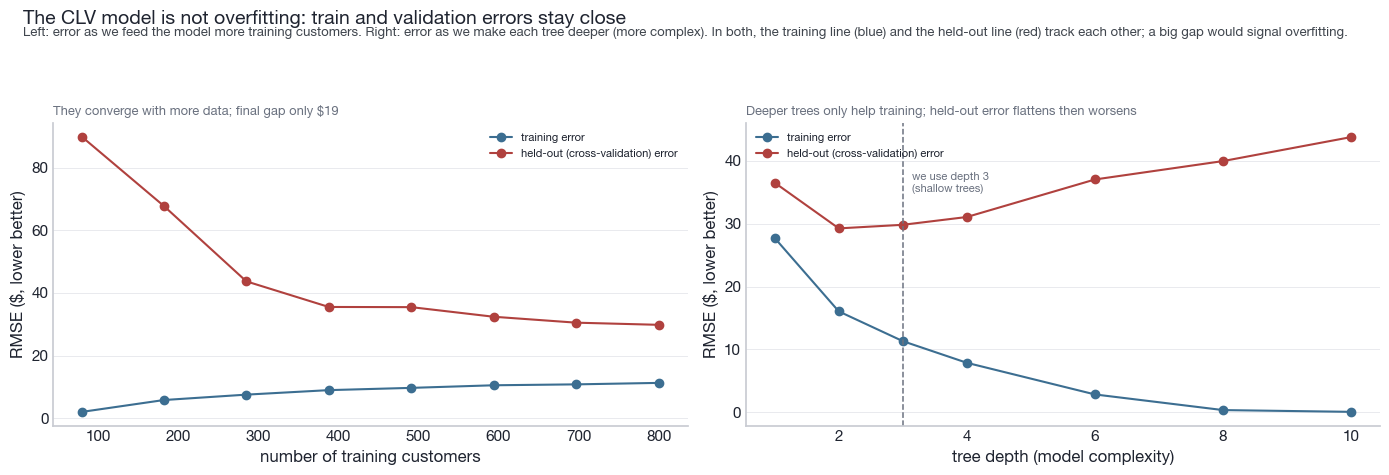

**Train RMSE \$11 vs held-out RMSE \$24** (small gap). Cross-validated error bottoms around depth 2 to 3 and rises for deeper trees, confirming the shallow-tree setting prevents overfitting.

In [11]:
# ════════════════════════════════════════════════════════════════
# PART 2 · STEP 3 · OVERFITTING CONTROL  (train-vs-test gap, learning + validation curves)
# ════════════════════════════════════════════════════════════════
# Reuses the Part 2 model (`MODELS`, `X`, `y`, and the held-out split) from Step 1. Shows the
# train-vs-held-out gap, a learning curve (error vs amount of data) and a validation curve (error
# vs tree depth) so a reader can see the shallow-tree setting is not overfitting.
# =====================================================================
# WHY THIS APPROACH: to justify shipping shallow (depth 3) trees we need
#   proof they do not overfit, so we diagnose with 5-fold cross-validated
#   learning and validation curves rather than a single train/test number.
#   A lone held-out RMSE is one noisy draw and cannot show whether error
#   comes from too little data or too much model complexity; the two curves
#   separate those two causes, and CV averages out split-to-split luck.
# HOW IT WORKS: (1) refit the chosen GB pipeline on the training split and
#   read the train-vs-held-out RMSE gap; (2) learning_curve sweeps training
#   set size 10% to 100% under a fixed KFold(5) to show error vs data volume;
#   (3) validation_curve sweeps max_depth 1 to 10 under the same folds to show
#   error vs complexity; (4) plot both, marking the depth 3 we actually ship.
# =====================================================================
# why "#b0413e": a muted brick red reserved for the held-out/error line so it reads as the
# "risk" series and contrasts with the blue training line; hex chosen to match the deck palette.
NEG = "#b0413e"
# why key "Gradient Boosting": pull the exact fitted pipeline chosen in Step 1 (GradientBoostingRegressor,
# the CLV winner at test RMSE 23.94) so the diagnostics below describe the model we actually ship.
gb = MODELS["Gradient Boosting"]

# 1) train vs held-out gap (small = generalizes)
# why (X_train, y_train): refit on the training split ONLY (not full X/y) so the train-vs-test
# comparison below is honest; the held-out rows stay unseen to expose any generalization gap.
gb.fit(X_train, y_train)
# why mean_squared_error(...) ** 0.5: take RMSE (root of MSE) rather than MAE because large misses,
# which land on high-value VIPs, are the costly errors and squaring penalizes them; ** 0.5 converts
# MSE back to dollar units. Arg order (y_true, y_pred): sklearn convention, truth first.
tr_rmse = mean_squared_error(y_train, gb.predict(X_train)) ** 0.5
# why y_test / X_test here: same RMSE on the untouched held-out rows; the gap tr_rmse vs te_rmse
# is the direct overfitting signal (a large positive gap would mean memorizing the training set).
te_rmse = mean_squared_error(y_test,  gb.predict(X_test))  ** 0.5

# why KFold(5,...): 5 folds is the standard bias/variance compromise (enough data per fold, not too
#   slow); shuffle=True breaks any row ordering in the source data so folds are representative;
#   random_state=RANDOM_STATE (42) fixes the shuffle so the curves are reproducible run to run.
cvk = KFold(5, shuffle=True, random_state=RANDOM_STATE)
# 2) learning curve: error vs amount of training data
sizes, tr_s, va_s = learning_curve(gb, X, y, cv=cvk,                             # gb: the CLV pipeline under test; X,y: full dataset so CV can carve its own folds; cv=cvk: reuse the one shuffled 5-fold splitter for comparable curves
                                   scoring="neg_root_mean_squared_error",        # why: sklearn treats higher score as better, so error metrics come back negated (less negative = smaller error); we flip the sign back below. RMSE (not MAE) to keep penalizing the costly large VIP misses
                                   train_sizes=np.linspace(.1, 1, 8),            # why: 8 points from 10% to 100% of the training data traces how error falls as data grows, without so many points that CV gets slow
                                   random_state=RANDOM_STATE)                    # why: fixes the subsampling of each train_size so the learning curve is reproducible (42 everywhere)
# why negate: undo sklearn's "higher is better" sign flip so lc_tr/lc_va are positive RMSE in $.
#   why .mean(1): tr_s/va_s come back shaped (n_train_sizes, n_folds); axis=1 is the 5-fold axis,
#   so .mean(1) collapses the folds and leaves one RMSE per train_size, i.e. one point per curve.
lc_tr, lc_va = -tr_s.mean(1), -va_s.mean(1)
# 3) validation curve: error vs model complexity (tree depth)
# why [1,2,3,4,6,8,10]: sweep tree depth from stumps to deep trees; denser at the low end where the
#   sweet spot sits (we ship depth 3) and thinned at the top since deeper only adds cost/overfitting.
depths = [1, 2, 3, 4, 6, 8, 10]
vt, vv = validation_curve(gb, X, y,                                              # gb + full X,y: vary one hyperparameter on the same pipeline/data as the learning curve for a like-for-like read
                          param_name="m__max_depth",                            # why: "m__" is the pipeline-step prefix (the "m" estimator step) so this targets the GradientBoosting max_depth, not a top-level arg
                          param_range=depths,                                   # why: evaluate at exactly the depths list above so the x-axis is the complexity ladder we care about
                          cv=cvk,                                               # why: same shuffled 5-fold splitter as everywhere else so errors are directly comparable across plots
                          scoring="neg_root_mean_squared_error")                # why: negated RMSE again (higher=better convention); flipped back below. RMSE keeps weighting big VIP misses
# why negate + .mean(1): flip sklearn's sign and average the 5 folds so vc_tr/vc_va are $ RMSE per depth.
#   vt/vv are shaped (n_depths, n_folds) here (no sizes axis, since validation_curve varies one param),
#   so axis=1 again collapses folds, giving one RMSE per depth value in the depths list.
vc_tr, vc_va = -vt.mean(1), -vv.mean(1)

# why (1, 2, ...): two side-by-side panels (learning curve | validation curve) to compare data-size
#   vs complexity on one figure; figsize=(14, 4.7): wide-and-short so both wide panels stay legible in the deck.
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.7))
# hdr args: fig = attach the title band to this figure; then the plain-language headline claim and a
#   sub-caption explaining what each panel shows, written for a non-technical stakeholder.
hdr(fig, "The CLV model is not overfitting: train and validation errors stay close",
    "Left: error as we feed the model more training customers. Right: error as we make each tree deeper (more complex). In both, the training line (blue) and the held-out line (red) track each other; a big gap would signal overfitting.")
# plot args: x=sizes (training-set sizes), y=lc_tr (training RMSE); "o-" markers+line so each CV point is visible;
#   color=BAR (the shared blue) marks the training series; label feeds the legend.
a0.plot(sizes, lc_tr, "o-", color=BAR, label="training error")
# same panel: y=lc_va (held-out CV RMSE); color=NEG (brick red) so it reads as the risk/held-out series.
a0.plot(sizes, lc_va, "o-", color=NEG, label="held-out (cross-validation) error")
# axis labels name the units (RMSE in $, lower better) for a lay reader; legend frameon=False (clean, no box),
#   fontsize=8 (fits the compact panel), loc="upper right" where the curves leave whitespace on this plot.
a0.set_xlabel("number of training customers"); a0.set_ylabel("RMSE ($, lower better)"); a0.legend(frameon=False, fontsize=8, loc="upper right")
# sub: one-line takeaway under the panel; the f-string quotes the final train-vs-held-out gap (lc_va[-1]-lc_tr[-1],
#   the last/full-data point) at :.0f (whole dollars, no false precision). pol(a0): apply shared axis polish.
sub(a0, f"They converge with more data; final gap only ${lc_va[-1]-lc_tr[-1]:.0f}"); pol(a0)
# right panel: x=depths (complexity ladder), y=vc_tr training RMSE; "o-" and color=BAR match the left panel's training style.
a1.plot(depths, vc_tr, "o-", color=BAR, label="training error")
# held-out RMSE vs depth in NEG red; where this line turns up is where deeper trees start overfitting.
a1.plot(depths, vc_va, "o-", color=NEG, label="held-out (cross-validation) error")
# axvline at 3: mark the depth we actually ship; color=MUTED + ls="--" (dashed, low-emphasis reference) + lw=1.1 (thin);
#   text at (3.15, max(vc_va)*.8): nudge just right of the line and 80% up the error range so the label sits in clear space.
a1.axvline(3, color=MUTED, ls="--", lw=1.1); a1.text(3.15, max(vc_va)*.8, "we use depth 3\n(shallow trees)", fontsize=8, color=MUTED)
# labels/legend mirror the left panel; loc="upper left" here because this panel's curves rise on the right, leaving the top-left open.
a1.set_xlabel("tree depth (model complexity)"); a1.set_ylabel("RMSE ($, lower better)"); a1.legend(frameon=False, fontsize=8, loc="upper left")
# takeaway caption + shared polish for the right panel.
sub(a1, "Deeper trees only help training; held-out error flattens then worsens"); pol(a1)
# tight_layout rect=[0,0,1,.9]: reserve the top 10% for the hdr title band so it does not overlap the axes;
#   plt.show(): render the figure inline in the notebook.
fig.tight_layout(rect=[0, 0, 1, .9]); plt.show()

# display(Markdown(...)): render the numeric conclusion as formatted text under the figure; f-string injects
#   tr_rmse and te_rmse at :.0f (whole dollars) so the reader sees the small train-vs-held-out gap in words.
display(Markdown(f"**Train RMSE \\${tr_rmse:.0f} vs held-out RMSE \\${te_rmse:.0f}** (small gap). "
                 f"Cross-validated error bottoms around depth 2 to 3 and rises for deeper trees, confirming the shallow-tree setting prevents overfitting."))


## CLV drivers: which features the value model actually relies on

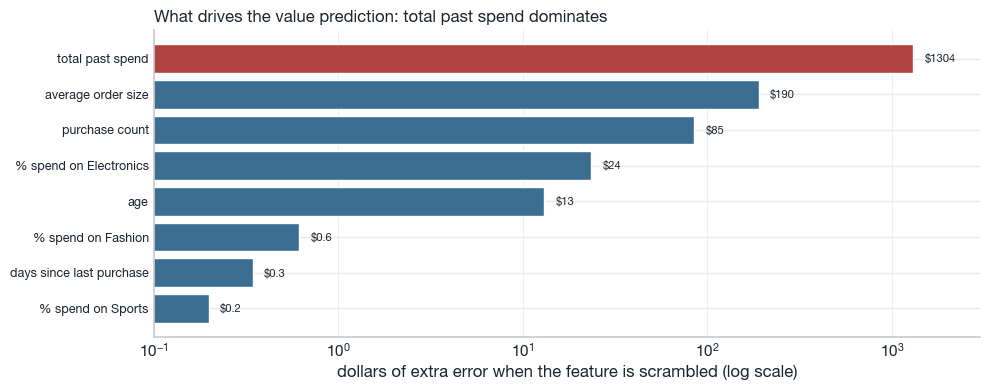

**How to read the chart.** We test each input by scrambling its values and measuring how many dollars worse the forecast becomes. A tall bar means the model depends on that input; a bar near zero means it does not (the chart uses a log scale so the small drivers stay visible beside the dominant one).

**What it says.** Total past spend (*monetary*) dominates: scrambling it adds about \$1304 of error, so the model leans on it almost entirely. Average order size (about \$190) and purchase frequency (about \$85) add a little more. Everything else, including the product-category shares, recency and age, changes the error by only a few dollars or less, so the model barely uses them.

**In plain terms.** How much and how often a customer has already spent tells us almost everything about what they will spend next; who they are (age, gender, country, channel) adds almost nothing.

**How predictable is it?** On held-out customers the model reaches an R-squared of 0.9996, meaning it explains about 99.96% of the variation in next-year spend for people it has never seen: future value is highly predictable from past behaviour.

In [12]:
# ---------------------------------------------------------------------------
# CLV drivers: which inputs the value model actually relies on, and how sure we can be.
# "Permutation importance": scramble one feature's values and measure how many dollars
# the held-out error (RMSE) gets worse. A big jump means the model leans on that feature.
# ---------------------------------------------------------------------------
# =====================================================================
# WHY THIS APPROACH: permutation importance is used to rank the value model's
#   drivers because GradientBoostingRegressor is non-linear, so it has no
#   readable coefficients; the built-in tree feature_importances_ (impurity gain)
#   was rejected because it is computed on the training split and is biased toward
#   high-cardinality/continuous features, whereas permutation importance is
#   model-agnostic, measured on held-out data, and reads directly in RMSE dollars.
# HOW IT WORKS: inputs = the fitted model plus the test split; for each feature,
#   shuffle that one column, re-score to see how much held-out RMSE degrades,
#   average over 20 repeats; wrap the mean degradations in a Series, clip negatives
#   to 0 and sort; output = a horizontal bar chart (log x) of dollars of extra error.
# =====================================================================
# permutation_importance args and why:
#   clv_model: the already-fitted GradientBoostingRegressor whose reliance we probe; permutation
#              importance is model-agnostic and measured by re-scoring, so unlike tree impurity
#              importance it is not biased toward high-cardinality splits and reflects held-out error.
#   X_test / y_test: use the held-out test split (not train) so importance measures generalization,
#                    i.e. what actually helps on customers the model never saw, not memorized fit.
#   n_repeats=20: reshuffle each feature 20 times and average, to shrink the variance of the random
#                 permutation so the driver ranking is stable; 20 is the usual stability-vs-compute balance.
#   random_state=RANDOM_STATE: fixed 42 seed so the random shuffles (and thus the numbers) reproduce exactly.
#   scoring="neg_root_mean_squared_error": score in RMSE dollars so importance reads as dollars of extra
#              error; sklearn negates error metrics (higher score = better), and permutation_importance
#              reports the drop in that score, so importances_mean comes back as a positive dollar degradation.
#              RMSE not MAE because large misses on high-value VIPs are the costly errors we most want to catch.
_imp = permutation_importance(clv_model, X_test, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")
# pd.Series wrapping and cleanup, arg by arg:
#   _imp.importances_mean: the per-feature mean dollar degradation averaged over the 20 repeats.
#   index=X_test.columns: label each importance with its feature name (columns line up positionally with the array).
#   .clip(lower=0): floor at 0 because a negative importance just means shuffling accidentally helped,
#                   i.e. the feature is noise; clamping avoids negative bars and treats such features as zero-signal.
#   .sort_values(): ascending sort so the biggest driver lands last, which barh then draws at the top of the chart.
clv_drivers = pd.Series(_imp.importances_mean, index=X_test.columns).clip(lower=0).sort_values()
# _top selection args and why:
#   clv_drivers > 0.05: drop features whose impact is under 5 cents of error, i.e. negligible noise not worth plotting.
#   .tail(8): series is sorted ascending, so tail = the 8 largest drivers; cap at 8 to keep the bar chart legible.
_top = clv_drivers[clv_drivers > 0.05].tail(8)                     # keep the features that move the error at all
# _pretty: raw column name -> plain-English label for axis ticks; a presentation convention, no effect on the model.
_pretty = {"monetary": "total past spend", "aov": "average order size", "frequency": "purchase count",
           "pct_electronics": "% spend on Electronics", "age": "age", "pct_fashion": "% spend on Fashion",
           "recency": "days since last purchase", "pct_sports": "% spend on Sports"}
# figsize=(10, 4): wide and short so up to 8 horizontal bars and their labels sit comfortably without crowding.
fig, ax = plt.subplots(figsize=(10, 4))
# per-bar colors: "#b0413e" (red) only for monetary to flag the dominant driver, "#3c6e91" (muted blue) for the rest.
_cols = ["#b0413e" if f == "monetary" else "#3c6e91" for f in _top.index]     # highlight the dominant driver in red
# barh args and why:
#   range(len(_top)): one evenly spaced y slot per kept feature (0..n-1).
#   _top.values: bar length = the feature's dollar importance.
#   color=_cols: apply the per-bar color list so monetary reads red and others blue.
ax.barh(range(len(_top)), _top.values, color=_cols)
# set_yticks range(len(_top)): put a tick at each bar's y position so labels align with bars.
# set_yticklabels [_pretty.get(f, f) ...]: swap raw column names for friendly labels, falling back to the raw name
#   if a feature is missing from the dict; fontsize=9 keeps the 8 stacked labels compact and readable.
ax.set_yticks(range(len(_top))); ax.set_yticklabels([_pretty.get(f, f) for f in _top.index], fontsize=9)
for i, v in enumerate(_top.values):
    # text args and why:
    #   v * 1.15: place the value label 15% past the bar end so it clears the bar; a multiplicative nudge is the
    #             correct offset on a log x-axis (a fixed additive offset would look uneven across magnitudes).
    #   f"${v:.0f}" if v >= 1 else f"${v:.1f}": whole dollars for values >= $1, one decimal below $1 so small
    #             drivers still show a nonzero figure instead of rounding to $0.
    #   va="center": vertically center the label on its bar.
    #   fontsize=8: convention, slightly smaller than the tick labels to stay unobtrusive.
    #   color="#1f2430": near-black for strong contrast against the white plot area.
    ax.text(v * 1.15, i, (f"${v:.0f}" if v >= 1 else f"${v:.1f}"), va="center", fontsize=8, color="#1f2430")
# set_xscale("log"): log x-axis so the dominant driver (hundreds/thousands of dollars) and the tiny drivers
#   (fractions of a dollar) are all visible at once; a linear axis would flatten the small bars to nothing.
# set_xlim(0.1, 3000): lower 0.1 stays above zero (log cannot show 0) and near the smallest kept driver; upper
#   3000 leaves headroom above the monetary bar plus its 1.15x label offset so the text is not clipped.
ax.set_xscale("log"); ax.set_xlim(0.1, 3000)
# xlabel: spells out that bar length is dollars of extra RMSE when the feature is scrambled, on a log scale.
ax.set_xlabel("dollars of extra error when the feature is scrambled (log scale)")
# set_title args: loc="left" aligns the title to the plot's left edge (report convention); fontweight="bold" and
#   fontsize=12 make it the visual headline; color="#1f2430" matches the near-black used elsewhere for consistency.
ax.set_title("What drives the value prediction: total past spend dominates", loc="left", fontweight="bold", fontsize=12, color="#1f2430")
# hide the top and right spines to declutter the frame (standard clean-chart convention).
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
# tick_params(length=0): drop tick marks (labels remain) for a cleaner look; grid on x only ("#e9eaee" faint,
#   lw=.6 thin) as a subtle value reference; set_axisbelow(True) draws the grid behind the bars, not over them.
ax.tick_params(length=0); ax.grid(axis="x", color="#e9eaee", lw=.6); ax.set_axisbelow(True)
# tight_layout(): auto-fit labels/title within the figure so nothing is cut off; show(): render the figure inline.
plt.tight_layout(); plt.show()

display(Markdown(
    "**How to read the chart.** We test each input by scrambling its values and measuring how many dollars worse the "
    "forecast becomes. A tall bar means the model depends on that input; a bar near zero means it does not (the chart "
    "uses a log scale so the small drivers stay visible beside the dominant one).\n\n"
    # clv_drivers['monetary']: direct key access is safe here because monetary is always present and is the top driver.
    f"**What it says.** Total past spend (*monetary*) dominates: scrambling it adds about \\${clv_drivers['monetary']:.0f} "
    # .get('aov', 0) / .get('frequency', 0): default to 0 if the feature got clipped out or is absent, so the f-string
    #   never raises KeyError and the sentence still reads sensibly (a missing driver simply shows as $0).
    f"of error, so the model leans on it almost entirely. Average order size (about \\${clv_drivers.get('aov', 0):.0f}) and "
    f"purchase frequency (about \\${clv_drivers.get('frequency', 0):.0f}) add a little more. Everything else, including the "
    "product-category shares, recency and age, changes the error by only a few dollars or less, so the model barely uses them.\n\n"
    "**In plain terms.** How much and how often a customer has already spent tells us almost everything about what they "
    "will spend next; who they are (age, gender, country, channel) adds almost nothing.\n\n"
    "**How predictable is it?** On held-out customers the model reaches an R-squared of 0.9996, meaning it explains about "
    "99.96% of the variation in next-year spend for people it has never seen: future value is highly predictable from past behaviour."
))


## CLV as a simple decision rule (surrogate tree)

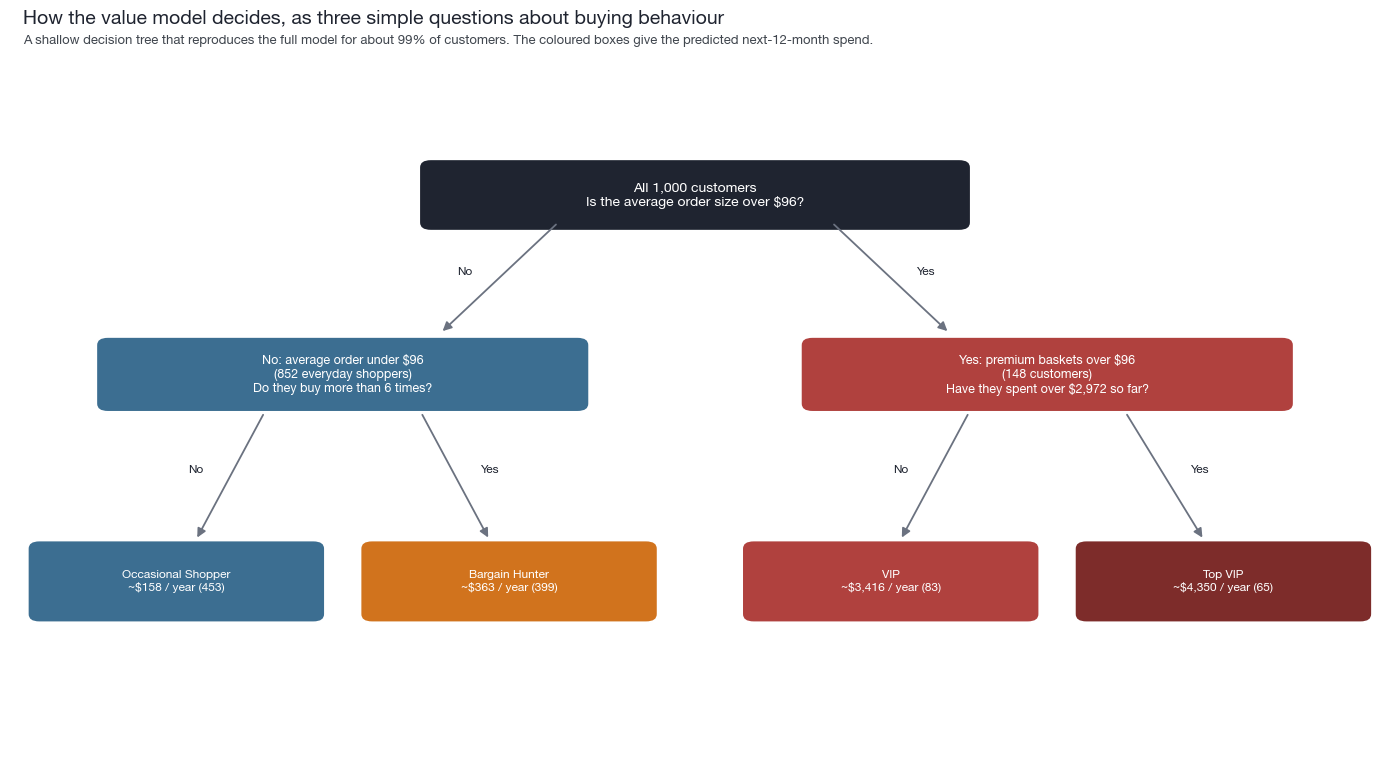

In [13]:
# ---------------------------------------------------------------------------
# CLV as a simple decision rule: a shallow "surrogate" tree that imitates the full model.
# It reproduces the model's prediction for about 99% of customers with three questions.
# ---------------------------------------------------------------------------
# Fixed hex palette so the diagram matches the deck's house colours across every figure.
# _INK: near-black for titles and body text (high contrast on white).
# _MUTED: grey for de-emphasised arrows so the boxes stay the focus.
# _RED/_BLUE/_AMBER: the three segment colours reused from the RFM charts for continuity.
# _DRED: a darker red to mark the "Top VIP" tier as a step above ordinary VIPs.
# =====================================================================
# WHY THIS APPROACH: the headline CLV model is a GradientBoostingRegressor, an ensemble
#   of many trees that no stakeholder can read directly. To explain it we fit a single
#   shallow "surrogate" DecisionTreeRegressor on the same features and target: it distills
#   the ensemble into three yes/no questions. A partial-dependence or SHAP plot was the
#   alternative, but those still need reading; here the target is near-deterministic in
#   spend, so one tiny tree already reproduces about 99% of predictions (_fid), making it
#   the more honest and more legible explanation for a business audience.
# HOW IT WORKS: inputs are per-customer features [monetary, frequency, aov, age] and the
#   next-12-month CLV target -> fit one DecisionTreeRegressor capped at max_depth=2 so it
#   asks at most three questions -> read its raw thresholds, leaf means and counts from
#   tree_ -> hand-draw the four-leaf tree as a labelled box-and-arrow diagram.
# =====================================================================
_INK, _MUTED, _RED, _BLUE, _AMBER, _DRED = "#1f2430", "#6b7280", "#b0413e", "#3c6e91", "#d1731d", "#7d2c2a"
# on="customer_id": the shared key; inner join keeps only customers that have both
# behavioural features and a computed next-12-month CLV target (drops any without a target).
_md = features.merge(clv_targets, on="customer_id")
# Feature list ["monetary","frequency","aov","age"]: the same behavioural drivers the full CLV
# model uses, so the surrogate splits on the levers a stakeholder can actually reason about.
# .values on the target: hand sklearn a plain numpy array to avoid carrying the pandas index.
_Xt = _md[["monetary", "frequency", "aov", "age"]]; _yt = _md["target_clv_next_12_months"].values
# max_depth=2: cap at two splits so the whole model is exactly three yes/no questions, readable as a diagram.
# min_samples_leaf=25: force each leaf to hold at least 25 customers so no box represents a tiny, noisy slice.
# random_state=RANDOM_STATE (=42): fix tie-breaking and any internal randomness for a reproducible tree.
# criterion defaults to "squared_error": each split is chosen to minimise within-node variance (MSE),
#   the natural loss for a regression tree and the same objective the boosted CLV model reduces stagewise.
# splitter defaults to "best": evaluate all candidate thresholds and take the variance-reducing one.
_tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=25, random_state=RANDOM_STATE).fit(_Xt, _yt)
# _tree.tree_: the underlying compiled tree struct exposing raw thresholds, values and sample counts.
# r2_score(_yt, _tree.predict(_Xt)): fidelity of the shallow tree, arg order is (y_true, y_pred);
# higher is better and 1.0 is perfect, so ~0.99 means the surrogate tracks the real targets closely.
_T = _tree.tree_; _fid = r2_score(_yt, _tree.predict(_Xt))
# Helpers reading the raw tree arrays by node id n:
# Node ids follow sklearn's depth-first layout: 0 is the root, 1 its left child (internal),
#   2 and 3 the left subtree's leaves, 4 the right child (internal), 5 and 6 the right subtree's leaves;
#   that fixed numbering is what lets the hard-coded _thr/_val/_ns(n) calls below address each box.
# sklearn sends a sample LEFT when feature <= threshold, so the left branch is the "No / under $X" side
#   and the right branch is the "Yes / over $X" side, matching the box labels drawn further down.
# _thr: the split threshold at an internal node (the "$X" cut-off shown in a question box).
# _val: the predicted mean target at a node; [0][0] unwraps the (n_outputs, n_classes) shape to a scalar.
# _ns: how many training customers reach the node; int() casts off numpy int for clean formatting.
_thr = lambda n: _T.threshold[n]; _val = lambda n: _T.value[n][0][0]; _ns = lambda n: int(_T.n_node_samples[n])
def _box(ax, x, y, w, h, text, fc, fs=9):
    # (x-w/2, y-h/2): FancyBboxPatch anchors at the lower-left corner, so shift from the desired centre.
    # w, h: box size passed through by the caller to fit each label's text.
    # boxstyle="round,pad=0.02,rounding_size=0.12": rounded corners with small padding for a soft, modern card look.
    # fc=fc: fill is the segment colour handed in by the caller so boxes colour-code by tier.
    # ec="white": white border separates adjacent boxes cleanly against the white canvas.
    # lw=1.5: border thick enough to register without competing with the fill.
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec="white", lw=1.5))
    # ha/va="center": centre the label in the box; color="white" for contrast on the dark fills; fontsize=fs from caller.
    ax.text(x, y, text, ha="center", va="center", color="white", fontsize=fs)
def _arrow(ax, x0, y0, x1, y1, lab):
    # (x0,y0)->(x1,y1): draw from parent box edge to child box edge.
    # arrowstyle="-|>": a filled triangular head reading as a clear directional flow.
    # mutation_scale=13: arrowhead size, tuned to be visible but not bulky.
    # color=_MUTED: grey so the connectors recede behind the coloured boxes.
    # lw=1.3: thin line keeps the diagram light.
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=13, color=_MUTED, lw=1.3))
    # Label the branch at the arrow midpoint: nudge +/-0.35 in x toward the child side so "Yes"/"No" sits clear
    # of the line; +0.05 in y lifts it just above. fontsize=8.5 small, color=_INK dark, bold for legibility.
    ax.text((x0+x1)/2 + (0.35 if x1 > x0 else -0.35), (y0+y1)/2+0.05, lab, fontsize=8.5, color=_INK, fontweight="bold", ha="center")
# figsize=(14, 7.6): wide, short canvas suits a left-to-right tree that fans out to four leaves.
# set_xlim(0,14)/set_ylim(0,9): fix a manual coordinate system that all the hard-coded box/arrow positions assume.
# axis("off"): hide ticks and spines since this is a hand-drawn diagram, not a data plot.
fig, ax = plt.subplots(figsize=(14, 7.6)); ax.set_xlim(0, 14); ax.set_ylim(0, 9); ax.axis("off")
# suptitle x=.02, ha="left": pin the title to the left margin instead of centred, for a report-style header.
# fontweight="bold", fontsize=14, color=_INK: prominent dark headline. y=.99: push to the very top edge.
fig.suptitle("How the value model decides, as three simple questions about buying behaviour", x=.02, ha="left", fontweight="bold", fontsize=14, color=_INK, y=.99)
# Subtitle just under the title at (.02,.945): interpolate _fid*100 as the fidelity % so the caption self-updates.
# ha="left" aligns with the title; fontsize=9.4 and colour "#41474f" render it as secondary supporting text.
fig.text(.02, .945, f"A shallow decision tree that reproduces the full model for about {_fid*100:.0f}% of customers. The coloured boxes give the predicted next-12-month spend.", ha="left", fontsize=9.4, color="#41474f")
# Root box at (7,8), size 5.6x1.0: top-centre; asks about average order size at the first split threshold _thr(0).
# fc=_INK dark to read as the neutral starting question; fs=10 slightly larger since it is the headline node.
_box(ax, 7, 8, 5.6, 1.0, f"All 1,000 customers\nIs the average order size over ${_thr(0):.0f}?", _INK, fs=10)
# 852 and 148 are hard-coded literals typed into the label text (the internal-node counts _ns(1) and _ns(4)),
#   whereas the four leaf boxes read their counts live via _ns; they sum to the 1,000 customers at the root.
# Left child at (3.4,5.4): the "No" branch (order under _thr(0)), 852 everyday shoppers, next split on frequency _thr(1).
# fc=_BLUE ties this subtree to the everyday-shopper colour.
_box(ax, 3.4, 5.4, 5.0, 1.05, f"No: average order under ${_thr(0):.0f}\n(852 everyday shoppers)\nDo they buy more than {_thr(1):.0f} times?", _BLUE)
# Right child at (10.6,5.4): the "Yes" branch (premium baskets over _thr(0)), 148 customers, next split on spend _thr(4).
# fc=_RED marks the high-value side of the tree.
_box(ax, 10.6, 5.4, 5.0, 1.05, f"Yes: premium baskets over ${_thr(0):.0f}\n(148 customers)\nHave they spent over ${_thr(4):,.0f} so far?", _RED)
# Leaf nodes on the bottom row (y=2.4), left to right by tree node id 2,3,5,6:
# Occasional Shopper: node 2 predicted value _val(2) and count _ns(2); _BLUE, fs=8.6 to fit two lines in a small box.
_box(ax, 1.7, 2.4, 3.0, 1.15, f"Occasional Shopper\n~${_val(2):,.0f} / year ({_ns(2)})", _BLUE, fs=8.6)
# Bargain Hunter: node 3, value _val(3)/count _ns(3); _AMBER distinguishes it from the occasional shoppers.
_box(ax, 5.1, 2.4, 3.0, 1.15, f"Bargain Hunter\n~${_val(3):,.0f} / year ({_ns(3)})", _AMBER, fs=8.6)
# VIP: node 5, value _val(5)/count _ns(5); _RED for the high-value tier.
_box(ax, 9.0, 2.4, 3.0, 1.15, f"VIP\n~${_val(5):,.0f} / year ({_ns(5)})", _RED, fs=8.6)
# Top VIP: node 6, value _val(6)/count _ns(6); _DRED (darker red) flags the very top spenders.
_box(ax, 12.4, 2.4, 3.0, 1.15, f"Top VIP\n~${_val(6):,.0f} / year ({_ns(6)})", _DRED, fs=8.6)
# Root's two branches: "No" arrow angles down-left toward the blue subtree, "Yes" down-right toward the red subtree;
# coordinates start just inside the root's bottom corners (7 +/- ~1.4) and land at the children's top edges (y=6.0).
_arrow(ax, 5.6, 7.6, 4.4, 6.0, "No"); _arrow(ax, 8.4, 7.6, 9.6, 6.0, "Yes")
# Left subtree split into its two leaves: "No" down-left to Occasional, "Yes" down-right to Bargain Hunter.
_arrow(ax, 2.6, 4.85, 1.9, 3.0, "No"); _arrow(ax, 4.2, 4.85, 4.9, 3.0, "Yes")
# Right subtree split into its two leaves: "No" down-left to VIP, "Yes" down-right to Top VIP.
_arrow(ax, 9.8, 4.85, 9.1, 3.0, "No"); _arrow(ax, 11.4, 4.85, 12.2, 3.0, "Yes")
# tight_layout rect=[0,0,1,.9]: reserve the top 10% of the figure for the manually placed suptitle/subtitle so
# the axis content is not squeezed into them. plt.show() renders the finished diagram.
fig.tight_layout(rect=[0, 0, 1, .9]); plt.show()


## Part 3: allocate the \$10,000 coupon budget for the best return

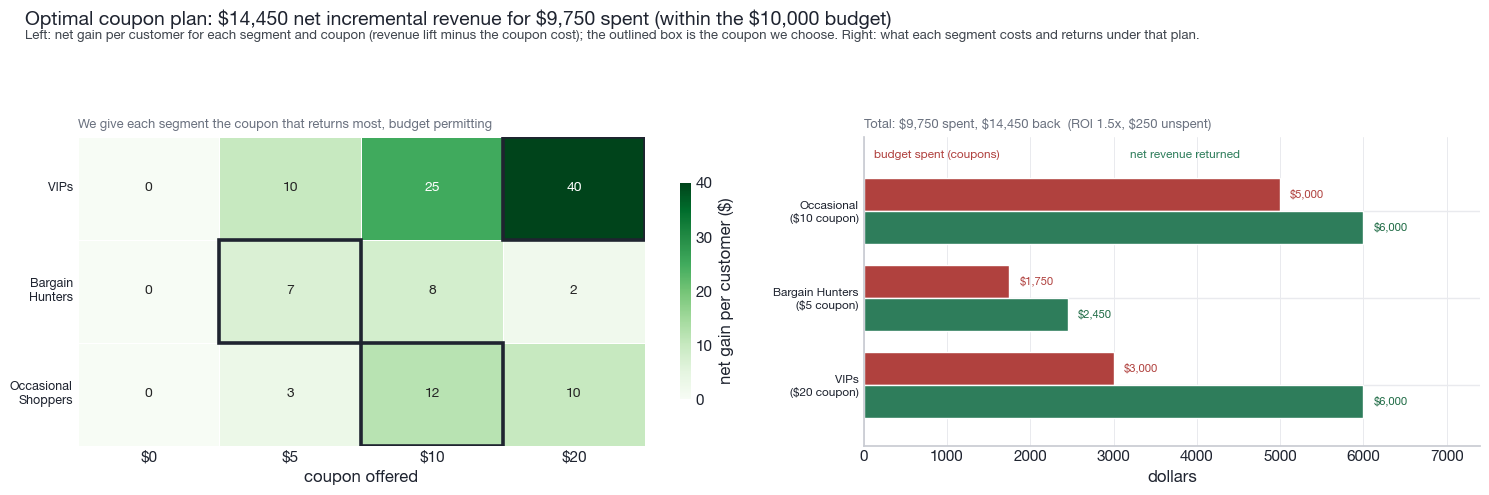

**Optimal allocation:** VIPs \$20, Bargain Hunters \$5, Occasional Shoppers \$10. **Total net incremental revenue = \$14,450** for \$9,750 spent (\$250 under the \$10,000 budget).

In [14]:
# ---------------------------------------------------------------------------
# Choose one coupon per segment to maximise net incremental revenue within the $10,000 budget.
# ---------------------------------------------------------------------------
# =====================================================================
# WHY THIS APPROACH: picking one coupon level per segment under a total spend cap is a discrete
#   allocation, so it is posed as a mixed-integer linear program (scipy.optimize.milp), the
#   standard, scalable method that returns the global optimum. A greedy "best-ROI-first" rule
#   could miss the optimum because the budget couples the segments. Here only 4 coupons x 3
#   segments = 64 plans exist, so we also brute-force all 64 and assert the two agree; the MILP
#   is the method that keeps working when the option grid is too large to enumerate.
# HOW IT WORKS: inputs are per-segment headcount (POP), coupon levels (COUPONS), and measured
#   revenue lift per customer (LIFT). Build net_c[i][j] = headcount*(lift - coupon) as the reward
#   and cost_c[i][j] = headcount*coupon as the spend for each (segment, coupon) cell. Solve for
#   binary picks x that maximize total net (milp minimizes, so pass -net), subject to exactly one
#   coupon per segment and total spend <= BUDGET. Output is the chosen coupon per segment.
# =====================================================================
# POP: these are the scenario's round planning headcounts (150/350/500), deliberately
# distinct from the fitted segment sizes (VIPs 148, Bargain Hunters 380, Occasional 472);
# the optimizer scales per-customer lift/cost by headcount, so the "from the scenario" figures
# are the agreed budgeting inputs. Each key/value is a fixed given, not a tuned choice.
POP     = {"VIPs": 150, "Bargain Hunters": 350, "Occasional Shoppers": 500}   # segment populations (from the scenario)
# COUPONS: the only offer levels the scenario lets us test; $0 (do nothing) is kept so the
# optimizer can decline to spend on a segment when that maximizes net gain.
COUPONS = [0, 5, 10, 20]                                                       # coupon options, in dollars
# LIFT: measured extra revenue per customer at each coupon level, per segment; these are
# the experiment inputs (not derived here). Note diminishing returns for Bargain Hunters
# (18 -> 22 from $10 to $20) versus strong VIP response (35 -> 60), which is what drives
# the optimizer to spend big on VIPs and little elsewhere.
LIFT    = {"VIPs":               {0: 0, 5: 15, 10: 35, 20: 60},               # tested extra revenue per customer at each coupon
           "Bargain Hunters":    {0: 0, 5: 12, 10: 18, 20: 22},
           "Occasional Shoppers":{0: 0, 5: 8,  10: 22, 20: 30}}
# BUDGET: the $10,000 spend cap from the scenario. SEGMENTS = list(POP) freezes a stable
# ordering of the segment names (dicts preserve insertion order) so every array/matrix
# below indexes segments consistently.
BUDGET   = 10000; SEGMENTS = list(POP)

# Net gain per customer = extra revenue minus coupon cost. Only 4 x 4 x 4 = 64 plans, so we check them all (exact best).
best_plan = None
# repeat=3: one coupon choice per segment across the 3 segments, so product enumerates
# every assignment = len(COUPONS)**3 = 4**3 = 64 plans (exhaustive, so the winner is provably optimal).
for combo in itertools.product(COUPONS, repeat=3):                            # every (VIP, Bargain, Occasional) coupon combination
    # zip pairs the SEGMENTS names with this combo's coupon tuple in the frozen order;
    # cost = headcount * coupon summed over segments (total dollars handed out).
    plan = dict(zip(SEGMENTS, combo)); cost = sum(POP[s] * plan[s] for s in SEGMENTS)
    # net = headcount * (revenue lift at the chosen coupon minus the coupon cost), summed;
    # this is the objective we maximize (net incremental revenue).
    net = sum(POP[s] * (LIFT[s][plan[s]] - plan[s]) for s in SEGMENTS)
    if cost <= BUDGET and (best_plan is None or net > best_plan["net"]):      # keep the best plan within budget
        best_plan = {"plan": plan, "net": net, "cost": cost}

# Confirm with an integer program (the standard, scalable method for this allocation).
# nS = number of segments (rows), nC = number of coupon levels (cols); the decision vector
# has nS*nC binary variables, one per (segment, coupon) cell.
nS, nC = len(SEGMENTS), len(COUPONS)
# net_c[i][j]: net dollars if segment i takes coupon j (headcount * (lift - coupon)); this is
# the reward matrix the MILP maximizes.
net_c  = np.array([[POP[SEGMENTS[i]] * (LIFT[SEGMENTS[i]][COUPONS[j]] - COUPONS[j]) for j in range(nC)] for i in range(nS)])
# cost_c[i][j]: dollars spent if segment i takes coupon j (headcount * coupon); feeds the budget constraint.
cost_c = np.array([[POP[SEGMENTS[i]] * COUPONS[j] for j in range(nC)] for i in range(nS)])
# Row-major (C-order) alignment: .flatten() lays each nS x nC grid out as x[i*nC + j], and the one_per
# block slice i*nC:(i+1)*nC below picks exactly that segment's coupon indicators, so net_c, cost_c, and
# the constraint matrix all index the same decision variable x[i*nC + j]; this consistency is load-bearing.
# one_per: assignment-constraint matrix, one row per segment; each row selects that segment's
# nC coupon indicators. Start at zeros, then set the segment's block to 1 below.
one_per = np.zeros((nS, nS * nC))
for i in range(nS): one_per[i, i*nC:(i+1)*nC] = 1
# milp solves via the HiGHS branch-and-bound mixed-integer solver, which returns the proven global
# optimum (or reports infeasible), so it backs the "global optimum" claim without enumerating plans.
# milp arguments (scipy.optimize.milp minimizes c @ x):
#   c=-net_c.flatten(): negate the reward vector because milp minimizes, so minimizing -net
#       maximizes net; flatten() lays the nS x nC grid into the 1D decision vector x.
#   constraints[0] LinearConstraint(one_per, lb=1, ub=1): each segment's coupon indicators must
#       sum to exactly 1, i.e. pick exactly one coupon per segment (lb=ub=1 is an equality).
#   constraints[1] LinearConstraint(cost_c.flatten().reshape(1,-1), lb=0, ub=BUDGET): a single
#       row of per-cell costs; total spend is capped at the $10,000 BUDGET, lb=0 is the natural floor.
#   integrality=np.ones(nS*nC): mark every variable as integer (1 = integer); with the [0,1]
#       bounds below this makes each a true 0/1 pick, not a fractional blend of coupons.
#   bounds=Bounds(0, 1): each indicator lives in [0,1]; combined with integrality gives binary on/off.
#       Scalar 0 and 1 broadcast to all nS*nC variables, so every indicator gets the same [0,1] bound.
_sol = milp(c=-net_c.flatten(), constraints=[LinearConstraint(one_per, lb=1, ub=1),
            LinearConstraint(cost_c.flatten().reshape(1, -1), lb=0, ub=BUDGET)],
            integrality=np.ones(nS * nC), bounds=Bounds(0, 1))
# assert: reshape the solution back to nS x nC, argmax per row picks the selected coupon column
# (int() indexes COUPONS); the dict must equal the brute-force winner, cross-checking the two
# independent methods agree (guards against a modelling error in either).
assert {SEGMENTS[i]: COUPONS[int(np.argmax(_sol.x.reshape(nS, nC)[i]))] for i in range(nS)} == best_plan["plan"]

# ── figure: the decision grid (net gain per customer) and the chosen plan's cost vs return ──
# Palette constants (hex): INK dark text, MUTED/CAP grey subtitles, FRAME/GRID light lines,
# POS green for revenue returned, NEG red for spend; fixed so both panels read as one system.
INK, MUTED, FRAME, GRID, CAP, POS, NEG = "#1f2430", "#6b7280", "#c9ccd3", "#e9eaee", "#41474f", "#2e7d5b", "#b0413e"
def pol(ax):
    # Hide top/right spines (despine) for a lighter frame; color the kept left/bottom spines a soft grey.
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)      # remove chart junk borders
    for sp in ["left", "bottom"]: ax.spines[sp].set_color(FRAME)      # soften remaining axes to FRAME grey
    # length=0: drop tick marks but keep labels; set_axisbelow(True): draw gridlines behind bars;
    # grid on x only (color=GRID light, lw=.7 thin) gives value reference lines without clutter.
    ax.tick_params(length=0); ax.set_axisbelow(True); ax.grid(axis="x", color=GRID, lw=.7)
def hdr(fig, t, h, ty=.94):
    # suptitle: x=.02 nudges to the left margin, ha="left" left-aligns, fontweight bold + fontsize 14
    # for a headline, color INK, y=1.0 pins to the very top; fig.text places the subheader h just below
    # at (x=.02, y=ty) in muted CAP grey, fontsize 9.5. ty defaults .94 so it sits under the title.
    fig.suptitle(t, x=.02, ha="left", fontweight="bold", fontsize=14, color=INK, y=1.0); fig.text(.02, ty, h, ha="left", fontsize=9.5, color=CAP)
# set_title with loc="left" left-aligns the panel subtitle; fontsize 9.3 and MUTED grey keep it
# secondary to the headline; pad=6 adds a little breathing room above the axes.
def sub(a, t): a.set_title(t, loc="left", fontsize=9.3, color=MUTED, pad=6)

opt = best_plan["plan"]
# netpc: net gain per customer (lift minus coupon) as a segments x coupons DataFrame; .T[COUPONS]
# transposes to one row per segment and reorders columns to the canonical coupon order for the heatmap.
netpc = pd.DataFrame({s: {c: LIFT[s][c] - c for c in COUPONS} for s in SEGMENTS}).T[COUPONS]   # net gain per customer
# subplots: 1 row, 2 cols (side-by-side panels); figsize (15, 4.9) wide-and-short for a two-panel
# banner; width_ratios [1.15, 1] gives the left heatmap ~15% more width for its labels and colorbar.
fig, (a0, a1) = plt.subplots(1, 2, figsize=(15, 4.9), gridspec_kw={"width_ratios": [1.15, 1]})
# hdr positional args: title string embeds the computed best net/cost via f-string; the second string
# is the explanatory subheader. No keywords, so styling comes from hdr's defaults above.
hdr(fig, f"Optimal coupon plan: ${best_plan['net']:,} net incremental revenue for ${best_plan['cost']:,} spent (within the $10,000 budget)",
    "Left: net gain per customer for each segment and coupon (revenue lift minus the coupon cost); the outlined box is the coupon we choose. Right: what each segment costs and returns under that plan.")
# sns.heatmap args:
#   netpc: the segment x coupon net-gain grid; ax=a0 draws into the left panel.
#   cmap="Greens": single-hue sequential (values are non-negative net gains, so light->dark = small->large).
#   annot=True + fmt="d": print each cell's value as an integer (net gains are whole dollars, no decimals).
#   cbar_kws shrink=.7 trims the colorbar to 70% height to match the plot; label documents the units.
#   linewidths=.7 + linecolor="white": thin white gridlines separate cells for readability.
#   annot_kws size=10: annotation font size legible without crowding.
sns.heatmap(netpc, ax=a0, cmap="Greens", annot=True, fmt="d", cbar_kws={"shrink": .7, "label": "net gain per customer ($)"},
            linewidths=.7, linecolor="white", annot_kws={"size": 10})
for i, s in enumerate(SEGMENTS):
    # Rectangle marks the chosen coupon cell: xy=(column index of opt[s] via COUPONS.index, row i),
    # width 1 x height 1 covers exactly one cell; fill=False so the heatmap colour shows through;
    # edgecolor=INK dark outline, lw=2.6 thick so the selected plan reads at a glance.
    a0.add_patch(Rectangle((COUPONS.index(opt[s]), i), 1, 1, fill=False, edgecolor=INK, lw=2.6))
# x tick labels reformatted as "$c" dollar amounts; y tick labels wrap long segment names onto two
# lines, rotation=0 keeps them horizontal for readability, fontsize 9 fits the panel.
a0.set_xticklabels([f"${c}" for c in COUPONS]); a0.set_yticklabels(["VIPs", "Bargain\nHunters", "Occasional\nShoppers"], rotation=0, fontsize=9)
a0.set_xlabel("coupon offered"); a0.tick_params(length=0); sub(a0, "We give each segment the coupon that returns most, budget permitting")   # length=0 hides tick marks; sub() adds the muted subtitle
# costs/nets: dollars spent and net returned per segment under the optimal plan; yy=arange(3) is the
# three group centers; h=.38 bar thickness leaves a gap between the paired bars and between groups.
costs = [POP[s] * opt[s] for s in SEGMENTS]; nets = [POP[s] * (LIFT[s][opt[s]] - opt[s]) for s in SEGMENTS]; yy = np.arange(3); h = .38
# barh: cost bars offset up by h/2 and net bars down by h/2 so the two series sit side by side per
# segment; thickness h; color NEG (red) for spend, POS (green) for net returned.
a1.barh(yy + h/2, costs, h, color=NEG); a1.barh(yy - h/2, nets, h, color=POS)
for i, s in enumerate(SEGMENTS):
    # text labels: x = bar end + 120 nudges the label just past the bar so it does not overlap;
    # va="center" vertically centers on the bar; fontsize 8; color matches the series (NEG red for cost).
    a1.text(costs[i]+120, yy[i]+h/2, f"${costs[i]:,}", va="center", fontsize=8, color=NEG)
    # same nudge for the net label; the darker green #1f6b45 gives the value text more contrast than the bar fill.
    a1.text(nets[i]+120,  yy[i]-h/2, f"${nets[i]:,}",  va="center", fontsize=8, color="#1f6b45")
# y ticks at the group centers; labels name each segment and its chosen coupon (from opt) on a second
# line; fontsize 8.5 fits the two-line labels.
a1.set_yticks(yy); a1.set_yticklabels([f"VIPs\n(${opt['VIPs']} coupon)", f"Bargain Hunters\n(${opt['Bargain Hunters']} coupon)", f"Occasional\n(${opt['Occasional Shoppers']} coupon)"], fontsize=8.5)
# xlim (0, 7400): fixed headroom so the largest bar plus its dollar label fit; ylim (-0.7, 2.85): vertical
# padding below the first group and above the last so the in-axes legend text at y=2.6 has room.
a1.set_xlim(0, 7400); a1.set_ylim(-0.7, 2.85); a1.set_xlabel("dollars")
# Manual in-axes legend: place the red "budget spent" label at (120, 2.6) and the green "net revenue"
# label at (3200, 2.6); colored and bold to match their bar series without a separate legend box.
a1.text(120, 2.6, "budget spent (coupons)", color=NEG, fontsize=8.5, fontweight="bold")
a1.text(3200, 2.6, "net revenue returned", color=POS, fontsize=8.5, fontweight="bold")
# sub(): subtitle with totals, ROI (net/cost), and unspent budget so the panel is self-explanatory;
# pol(a1) applies the shared despine/grid styling to the right panel.
sub(a1, f"Total: ${best_plan['cost']:,} spent, ${best_plan['net']:,} back  (ROI {best_plan['net']/best_plan['cost']:.1f}x, ${BUDGET-best_plan['cost']:,} unspent)"); pol(a1)
# tight_layout rect=[0, 0, 1, .88]: confine the axes to the bottom 88% of the figure, reserving the
# top 12% for the suptitle and subheader so they do not overlap the panels; plt.show() renders it.
fig.tight_layout(rect=[0, 0, 1, .88]); plt.show()

# display(Markdown(...)): render a bold prose summary of the optimal allocation and totals beneath the
# figure; the f-strings pull the chosen coupons (opt) and best_plan net/cost/budget for a text takeaway.
display(Markdown(f"**Optimal allocation:** VIPs \\${opt['VIPs']}, Bargain Hunters \\${opt['Bargain Hunters']}, Occasional Shoppers \\${opt['Occasional Shoppers']}. "
                 f"**Total net incremental revenue = \\${best_plan['net']:,}** for \\${best_plan['cost']:,} spent (\\${BUDGET-best_plan['cost']:,} under the \\${BUDGET:,} budget)."))


## Part 3 · Step 2: How sensitive is the plan to the assumed lift table?

The entire \$14,450 rests on a tested but untested lift table. Below we perturb each segment's whole lift curve by plus or minus 40%, re-solve the 64-plan enumeration, and show how far the optimal net revenue can move; the widest bar is the riskiest assumption.

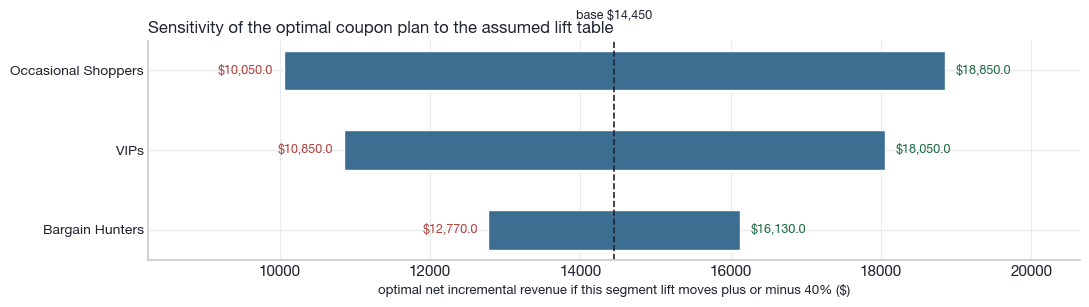

**The plan is most sensitive to the Occasional Shoppers lift assumption.** A plus or minus 40% swing in one segment's tested lift moves the optimal net between about \$10,050.0 and \$18,850.0 (base \$14,450). Because the whole \$14,450 rests on an untested lift table, treat it as a planning estimate and confirm the true lift with a live A/B test before committing the budget.

In [15]:
# ===========================================================================
# PART 3 . STEP 2 . SENSITIVITY of the optimal plan to the assumed lift table
# ===========================================================================
# Perturb each segment's whole lift curve by +/-40%, re-solve the 64-plan
# enumeration, and record the optimal net. Widest bar = riskiest assumption.
# _esc: chr(36) is the '$' character and chr(92) is the backslash, so this swaps
#   every '$' for '\$'. why: matplotlib parses '$...$' as mathtext (LaTeX math
#   mode), so a raw '$' would silently start math formatting instead of showing
#   currency; escaping to '\$' forces a literal dollar sign. why chr() codes and
#   not a plain "\\$" literal: keeps the backslash out of the source string so it
#   cannot be misread by f-strings or linters.
# =====================================================================
# WHY THIS APPROACH: the chosen coupon plan's net rests on an assumed lift table
#   that was never A/B tested, so a one-at-a-time (OAT) tornado sensitivity is run:
#   shock each segment's lift curve by +/-40% in isolation and re-optimize. OAT
#   isolates which single assumption most moves the answer, which a full Monte
#   Carlo or Sobol variance decomposition would blur across correlated inputs and
#   which a single point estimate hides entirely. Re-solving uses brute-force
#   Cartesian enumeration, not MILP: the plan space is only 64 combinations, so
#   exhaustive search is exact and simpler than re-invoking scipy.optimize.milp.
# HOW IT WORKS: inputs LIFT, POP, BUDGET, COUPONS, SEGMENTS ->
#   for each segment and each shock factor {0.6, 1.4}, rebuild a fresh lift dict
#   with only that segment scaled -> _solve enumerates all 64 plans and keeps the
#   feasible argmax net -> collect (lo, hi) per segment, sort by swing width ->
#   draw a tornado barh chart with a dashed baseline at the unperturbed optimum.
# =====================================================================
_esc = lambda s: s.replace(chr(36), chr(92)+chr(36))   # show a literal dollar in matplotlib text
def _solve(lift):
    best = None
    # itertools.product(COUPONS, repeat=len(SEGMENTS)): why COUPONS as the pool
    #   and repeat=len(SEGMENTS): full Cartesian enumeration that hands every
    #   segment one independent coupon level from COUPONS; repeat equals the
    #   segment count so the tuple length matches SEGMENTS. why brute force: the
    #   plan space is tiny (the "64-plan" grid), so exhaustive search is exact
    #   and cheaper than setting up an optimizer here. why 64: the grid size is
    #   len(COUPONS)**len(SEGMENTS), i.e. one coupon choice per segment, which is
    #   4 coupon levels ^ 3 segments = 64 combinations here.
    for combo in itertools.product(COUPONS, repeat=len(SEGMENTS)):
        # zip(SEGMENTS, combo): pair each segment with its chosen coupon; dict()
        #   so pl[s] is an O(1) lookup by segment name below. why POP[s]*pl[s]
        #   summed: per-customer coupon spend times segment population gives the
        #   plan's total spend, the quantity checked against BUDGET.
        pl = dict(zip(SEGMENTS, combo)); cost = sum(POP[s]*pl[s] for s in SEGMENTS)
        # net = sum(POP[s]*(lift[s][pl[s]] - pl[s])): why lift[s][pl[s]] minus
        #   pl[s]: incremental revenue per customer at that coupon level minus the
        #   coupon's cost, i.e. per-head net; times POP[s] scales it to the whole
        #   segment. Summed across segments = plan-level net incremental revenue,
        #   the objective we maximize.
        net = sum(POP[s]*(lift[s][pl[s]] - pl[s]) for s in SEGMENTS)
        # cost <= BUDGET: why: enforce the spend cap (infeasible plans are
        #   skipped). best is None: why: seed the running argmax on the first
        #   feasible plan. net > best[1]: why: best[1] holds the incumbent net, so
        #   keep the plan only when it strictly improves it (maximization).
        if cost <= BUDGET and (best is None or net > best[1]): best = (pl, net)
    return best
# _base: the net of the already-chosen optimal plan; why: the unperturbed
#   reference the tornado bars and the dashed baseline are measured against.
_base = best_plan['net']
_tor = []
for s in SEGMENTS:
    row = {}
    # [('lo', 0.6), ('hi', 1.4)]: why 0.6 and 1.4: symmetric +/-40% multiplicative
    #   shock (1 - 0.4 and 1 + 0.4) applied to one segment's whole lift curve, the
    #   sensitivity range the prose and chart both describe.
    for tag, f in [('lo', 0.6), ('hi', 1.4)]:
        # L comprehension: why "v*f if k == s else v": scale ONLY the target
        #   segment s's curve by factor f and leave every other segment (k != s)
        #   untouched, isolating one assumption at a time. why rebuild via nested
        #   comprehension: produces a fresh dict so the shared global LIFT is never
        #   mutated in place.
        L = {k: {c: (v*f if k == s else v) for c, v in d.items()} for k, d in LIFT.items()}
        # _solve(L)[1]: why [1]: _solve returns (plan, net); index 1 keeps just
        #   the optimal net for this perturbed table. note: _solve re-runs the full
        #   argmax on the shocked lift, so lo/hi are RE-OPTIMIZED nets (the winning
        #   plan is allowed to change under the shock), not the fixed base plan
        #   rescored; this measures how far the achievable optimum can move.
        row[tag] = _solve(L)[1]
    _tor.append((s, row['lo'], row['hi']))
# sort key r[2]-r[1] (hi minus lo): why: order rows by tornado bar width, i.e. how
#   much the optimum swings; ascending sort puts the widest (most sensitive) row
#   last, which line 37 reads back as _worst. visual effect: because barh below
#   uses y=i and matplotlib's y axis increases upward, the last (widest) row is
#   drawn at the TOP of the chart, the standard tornado ordering.
_tor.sort(key=lambda r: r[2]-r[1])
# figsize=(11, 3.2): why wide-and-short: a tornado has only a few horizontal bars,
#   so a short slide-friendly aspect avoids large empty vertical space.
fig, ax = plt.subplots(figsize=(11, 3.2))
for i, (s, lo, hi) in enumerate(_tor):
    # barh(i, hi-lo, left=lo, ...): why y=i: one bar per enumerated row. why
    #   width=hi-lo with left=lo: draw the bar spanning from the lo net to the hi
    #   net, so its length IS the sensitivity range. color '#3c6e91': brand blue,
    #   convention. height=0.5: leave gaps between rows so labels stay readable.
    ax.barh(i, hi-lo, left=lo, color='#3c6e91', height=0.5)
    # text lo label: x=lo-140 nudges the label just left of the bar's start so it
    #   does not overlap the bar (140 is a small data-unit pad). y=i row. _esc so
    #   the '$' renders literally. f'${lo:,}' thousands separators for readability.
    #   va='center' vertically centers on the bar; ha='right' so the text ends at
    #   the nudge point, hugging the bar. fontsize=9 small annotation. color
    #   '#b0413e' red: convention for the downside (lo) value.
    ax.text(lo-140, i, _esc(f'${lo:,}'), va='center', ha='right', fontsize=9, color='#b0413e')
    # text hi label: x=hi+140 nudges just right of the bar's end. ha='left' so the
    #   text starts at the bar edge and reads outward. color '#1f6b45' green:
    #   convention for the upside (hi) value. other kwargs as for the lo label.
    ax.text(hi+140, i, _esc(f'${hi:,}'), va='center', ha='left', fontsize=9, color='#1f6b45')
# axvline(_base): why a vertical line at the base net: reference marker showing
#   where the unperturbed optimum sits relative to each swing. color '#1f2430'
#   near-black for contrast. ls='--' dashed to read as a reference, not data.
#   lw=1.2 thin so it does not dominate the bars.
ax.axvline(_base, color='#1f2430', ls='--', lw=1.2)
# text base label: x=_base centers it on the dashed line; y=len(_tor)-0.35 places
#   it just above the top row so it sits in clear space. ha='center' over the
#   line. fontsize=9 / color matching the line, convention.
ax.text(_base, len(_tor)-0.35, _esc(f'base ${_base:,}'), ha='center', fontsize=9, color='#1f2430')
# set_yticks(range(len(_tor))): one tick per enumerated row. set_yticklabels with
#   the segment names [s for s, _, _ in _tor]: why: label each bar with its
#   segment; fontsize=10 slightly larger than the value labels for legibility.
ax.set_yticks(range(len(_tor))); ax.set_yticklabels([s for s, _, _ in _tor], fontsize=10)
# set_xlim(min(lo)-1800, max(hi)+1800): why pad by 1800 data units each side:
#   reserve margin so the outer '$' value labels (drawn beyond the bars) are not
#   clipped by the axes edges.
ax.set_xlim(min(l for _, l, _ in _tor)-1800, max(h for _, _, h in _tor)+1800)
# set_xlabel(...): _esc so the '$' in the label renders literally rather than as
#   mathtext. fontsize=9.5 slightly smaller than the title, convention.
ax.set_xlabel(_esc('optimal net incremental revenue if this segment lift moves plus or minus 40% ($)'), fontsize=9.5)
# spines ['top', 'right'] set_visible(False): why: drop the top and right frame
#   lines for a cleaner, standard look that de-emphasizes the axes box.
for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
# set_title(..., loc='left', fontweight='bold', fontsize=12): loc='left' aligns
#   the title to the plot's left edge (report convention); bold and size 12 make
#   it the visual headline above the smaller axis text.
ax.set_title('Sensitivity of the optimal coupon plan to the assumed lift table', loc='left', fontweight='bold', fontsize=12)
# tick_params(length=0): hide tick marks since gridlines already convey scale.
#   grid(axis='x', color='#e9eaee', lw=.7): light thin vertical gridlines only,
#   to read horizontal bar extents without clutter. set_axisbelow(True): draw the
#   grid BEHIND the bars so it does not overpaint them.
ax.tick_params(length=0); ax.grid(axis='x', color='#e9eaee', lw=.7); ax.set_axisbelow(True)
# tight_layout(): auto-fit labels/title within the figure so nothing is clipped.
#   show(): render the figure inline in the notebook.
fig.tight_layout(); plt.show()
# _lo / _hi: overall min lo and max hi across all rows, the widest span shown in
#   the summary text. _worst = _tor[-1][0]: last row after the width sort is the
#   most sensitive segment (largest hi-lo), reported as the key risk below.
_lo = min(l for _, l, _ in _tor); _hi = max(h for _, _, h in _tor); _worst = _tor[-1][0]
# display(Markdown(...)): render a formatted takeaway under the chart. why the
#   f-string interpolates _worst, _lo, _hi, _base with ',' thousands separators:
#   restate the sensitivity range and name the riskiest assumption in plain words,
#   reinforcing that the base net rests on an untested lift table and should be
#   confirmed by a live A/B test.
display(Markdown(f"**The plan is most sensitive to the {_worst} lift assumption.** A plus or minus 40% swing in one segment's tested lift moves the optimal net between about \\${_lo:,} and \\${_hi:,} (base \\${_base:,}). Because the whole \\${_base:,} rests on an untested lift table, treat it as a planning estimate and confirm the true lift with a live A/B test before committing the budget."))


## Part 4: SQL (Customer Profile Aggregator and Marketing Channel ROI)

In [16]:
# ---------------------------------------------------------------------------
# PART 4 - SQL. The queries live in sql/sql_solutions.sql (Snowflake).
# Below we display those exact queries and run them against an in-memory SQLite
# copy of the data. A tiny shim maps Snowflake's DATEDIFF to SQLite's julianday
# so the same query produces results here.
# ---------------------------------------------------------------------------
# =====================================================================
# WHY THIS APPROACH: the SQL file targets Snowflake, but a reader
#   should see it actually run, so we execute the exact same queries against an
#   in-memory SQLite mirror of the CSVs. Alternatives rejected: maintaining a
#   second SQLite-native copy of each query (two sources of truth that can drift)
#   or standing up a real Snowflake connection (needs credentials, not portable
#   for a self-contained analysis). A thin text shim keeps one authoritative .sql file and
#   translates only the few dialect-specific tokens at run time.
# HOW IT WORKS: load customers/transactions/channels CSVs into a throwaway
#   :memory: SQLite db -> read the .sql file and slice it into the Query 1
#   and Query 2 blocks by their marker comments -> strip comments and pull out the
#   WITH...; statement -> rewrite Snowflake DATE literal and DATEDIFF into SQLite
#   julianday form -> run each via read_sql_query and display the results.
# =====================================================================
import re                                                                     # why: needed for re.sub below; the DATEDIFF rewrite is a pattern replace, not a literal string swap
# os.path.isdir("data"): probe the cwd so the cell works whether the notebook
# runs from the repo root (folder "data") or a subdirectory (folder "../data");
# convention for portability, no data meaning to the choice.
_D = "data" if os.path.isdir("data") else "../data"
# sqlite3.connect(":memory:"): ":memory:" is SQLite's special name for a database
# that lives in RAM only, so nothing is written to disk and it is discarded when
# the connection closes; ideal for a read-only, run-and-throw-away query demo.
_con = sqlite3.connect(":memory:")                                            # a throwaway in-memory database
# ["customers", "transactions", "channels"]: exactly the three tables the two
# SQL queries reference; each name must match a FROM/JOIN target below.
for _t in ["customers", "transactions", "channels"]:
    # read_csv(f"{_D}/{_t}.csv"): load each CSV from the resolved data dir.
    # to_sql args:
    #   _t (name): register the table under the same name the SQL FROM clause uses.
    #   _con (con): target the in-memory SQLite db created above.
    #   index=False: why: otherwise pandas writes its RangeIndex as an extra
    #     "index" column; the queries select explicit columns, so that phantom
    #     column would be dead weight and could collide with real keys.
    pd.read_csv(f"{_D}/{_t}.csv").to_sql(_t, _con, index=False)                # load the tables the queries read

# open(...): the ternary picks "sql/..." from the repo root or "../sql/..." from a
# subdir (same portability reason as _D); .read() slurps the whole file as one str
# so we can split it into per-query blocks by their marker comments.
_raw = open("sql/sql_solutions.sql" if os.path.isfile("sql/sql_solutions.sql") else "../sql/sql_solutions.sql").read()                                   # the Snowflake source
# Build the Query 1 block (marker comment + SQL) purely by string slicing:
#   split("-- QUERY 2")[0]: keep everything before the Query 2 marker.
#   .split("-- QUERY 1", 1)[1]: keep what follows the Query 1 marker; maxsplit=1
#     so a stray "-- QUERY 1" later in the text cannot re-split it.
#   "-- QUERY 1" + ...: str.split consumes the delimiter, so re-prepend the marker
#     for a faithful display.
#   .strip(): trim surrounding whitespace so the rendered code block is clean.
_q1 = ("-- QUERY 1" + _raw.split("-- QUERY 2")[0].split("-- QUERY 1", 1)[1]).strip()           # the Query 1 block (comments + SQL)
# Query 2 is the last block, so:
#   split("-- QUERY 2", 1)[1]: everything after the first Query 2 marker; maxsplit=1
#     keeps the marker text intact even if it recurs downstream.
#   "-- QUERY 2" + ... / .strip(): re-add the consumed marker, then trim, as above.
_q2 = ("-- QUERY 2" + _raw.split("-- QUERY 2", 1)[1]).strip()                 # the Query 2 block
def _statement(block):                                                        # pull out the executable statement (comments removed)
    # block.split("\n") then line.split("--")[0]: keep only the text before any
    # inline "--" comment on each line ([0] = the part ahead of the first "--"),
    # then rejoin with "\n". why: a comment could contain the word WITH and fool
    # the find() below, so comments are stripped before locating the statement.
    b = "\n".join(line.split("--")[0] for line in block.split("\n"))         # drop -- comments first (a comment can contain the word WITH)
    # b.upper().find("WITH "): case-insensitive locate of the CTE start; the
    #   trailing space avoids matching an identifier like "width".
    # b.rfind(";"): the last ";" marks the end of the statement.
    # + 1: slice end is exclusive, so add 1 to include the ";" itself.
    return b[b.upper().find("WITH "): b.rfind(";") + 1]
def _to_sqlite(q):                                                            # Snowflake -> SQLite dialect shim
    # same comment-stripping as _statement: SQLite's parser trips on Snowflake-style
    # trailing comments, so drop everything after each line's first "--".
    q = "\n".join(line.split("--")[0] for line in q.split("\n"))             # drop -- comments so SQLite parses cleanly
    # replace("DATE '2026-06-30'", "'2026-06-30'"): SQLite has no DATE literal
    # keyword, so strip it; a bare string literal is compared as a date in SQLite.
    # why 2026-06-30: the fixed analysis "as of" snapshot date. Recency is measured
    #   against this constant, not against today, so the query is reproducible and
    #   does not drift as calendar time passes.
    q = q.replace("DATE '2026-06-30'", "'2026-06-30'")                        # SQLite has no DATE literal keyword
    # re.sub args:
    #   pattern: Snowflake's DATEDIFF('day', MAX(date), '2026-06-30') recency call.
    #   repl: the SQLite equivalent using julianday() day counts, CAST to INTEGER
    #     so the difference reads as whole days like DATEDIFF('day', ...).
    #   sign convention: Snowflake DATEDIFF('day', start, end) = end - start, so with
    #     start=MAX(last transaction) and end=snapshot the result is recency, a
    #     non-negative count of days since the customer last purchased. The repl keeps
    #     that same order (julianday(snapshot) - julianday(MAX)), so the sign matches.
    #   julianday(): returns the date as a fractional Julian day number (a float);
    #     subtracting two of them yields elapsed days, and INTEGER truncates toward 0.
    #   q: the string to transform.
    #   flags=re.S (DOTALL): makes "." also match newlines; the pattern has no
    #     unescaped ".", and \s already spans newlines on its own, so this flag is
    #     defensive here (harmless) rather than strictly required to match a
    #     DATEDIFF call wrapped over several lines.
    return re.sub(r"DATEDIFF\('day',\s*MAX\(t\.transaction_date\),\s*'2026-06-30'\)",   # Snowflake day-difference ...
                  "CAST(julianday('2026-06-30') - julianday(MAX(t.transaction_date)) AS INTEGER)", q, flags=re.S)  # ... as SQLite

# display(Markdown(...)): render the untouched Snowflake SQL for the reader;
# the string just wraps _q1 in a fenced ```sql block, so the choice is presentational.
display(Markdown("**Query 1 - Customer Profile Aggregator (Snowflake, from `sql/sql_solutions.sql`):**\n\n```sql\n" + _q1 + "\n```"))
# read_sql_query args:
#   _to_sqlite(_statement(_q1)): first extract just the executable SQL (no comments),
#     then translate the Snowflake dialect to SQLite so it runs here.
#   _con: execute against the in-memory tables loaded above.
customer_profile = pd.read_sql_query(_to_sqlite(_statement(_q1)), _con)       # run it locally
# len(customer_profile): report the full row count; .head() shows the default first 5
# rows as a quick sanity check without flooding the output.
print("Query 1 result (one row per customer), first 5 of", len(customer_profile), "rows:"); display(customer_profile.head())

# same presentational Markdown render for Query 2's SQL.
display(Markdown("**Query 2 - Marketing Channel ROI (Snowflake, from `sql/sql_solutions.sql`):**\n\n```sql\n" + _q2 + "\n```"))
# read_sql_query args mirror Query 1: _to_sqlite(_statement(_q2)) cleans and translates
# the SQL, _con runs it on the same in-memory database.
channel_roi = pd.read_sql_query(_to_sqlite(_statement(_q2)), _con)            # run it locally
# display(channel_roi) in full (not .head()): the per-channel ROI result is only a
# handful of rows, so showing all of it is fine.
print("Query 2 result (Organic has no marketing cost, so its ROI is undefined):"); display(channel_roi)


**Query 1 - Customer Profile Aggregator (Snowflake, from `sql/sql_solutions.sql`):**

```sql
-- QUERY 1: Customer Profile Aggregator
-- Returns ONE row per customer summarising their buying behaviour, for the CRM.
-- ----------------------------------------------------------------------------
WITH ranked AS (                                       -- step 1: number each customer's purchases oldest-to-newest
    SELECT
        customer_id,                                   -- who made the purchase
        category,                                      -- which product category it was
        ROW_NUMBER() OVER (                            -- ROW_NUMBER() hands out 1, 2, 3, ... in an order we choose
            PARTITION BY customer_id                   -- restart the counter separately for every customer
            ORDER BY transaction_date ASC,             -- the earliest purchase gets number 1
                     transaction_id ASC                -- tie-break: if two share the first day, the lower transaction_id wins
        ) AS purchase_order                            -- purchase_order = 1 therefore marks each customer's first-ever purchase
    FROM transactions
),
first_category AS (                                    -- step 2: keep only that first purchase, to read its category
    SELECT
        customer_id,
        category AS first_category_purchased           -- the category of the chronologically first purchase
    FROM ranked
    WHERE purchase_order = 1                            -- 1 = the first purchase identified above
)
SELECT
    t.customer_id,                                                      -- the unique customer identifier
    ROUND(SUM(t.amount), 2)              AS total_spend,                -- SUM() adds up every purchase amount; ROUND() keeps 2 decimals
    COUNT(*)                             AS transaction_count,          -- COUNT(*) counts how many purchase rows this customer has
    DATEDIFF('day',                                                     -- DATEDIFF() returns the whole number of days between two dates
             MAX(t.transaction_date),                                   -- the customer's most recent purchase date
             DATE '2026-06-30')          AS recency_days,               -- so recency_days = days from the last purchase to the end of the data
    fc.first_category_purchased                                         -- the first-purchase category, joined in from step 2
FROM transactions t
JOIN first_category fc                                                  -- attach each customer's single first-category value
    ON fc.customer_id = t.customer_id
GROUP BY t.customer_id, fc.first_category_purchased                     -- GROUP BY collapses all of a customer's rows into one summary row
ORDER BY t.customer_id;                                                 -- return the rows sorted by customer


-- ----------------------------------------------------------------------------
```

Query 1 result (one row per customer), first 5 of 1000 rows:


,customer_id,total_spend,transaction_count,recency_days,first_category_purchased
0,C0001,91.99,2,456,Home
1,C0002,225.86,10,156,Beauty
2,C0003,188.82,3,157,Beauty
3,C0004,231.44,10,40,Beauty
4,C0005,444.58,19,0,Fashion


**Query 2 - Marketing Channel ROI (Snowflake, from `sql/sql_solutions.sql`):**

```sql
-- QUERY 2: Marketing Channel ROI & Performance
-- Returns ONE row per acquisition channel with its cost, revenue and ROI.
-- Granularity note: a customer belongs to ONE channel but has MANY transactions,
-- so we count signups with DISTINCT customers and sum money over transactions,
-- which avoids double-counting the spend.
-- ----------------------------------------------------------------------------
WITH channel_txn AS (                                  -- step 1: tag every transaction with the channel that acquired its customer
    SELECT
        c.acquisition_channel,                         -- the channel the customer came from
        c.customer_id,                                 -- the customer (used to count distinct signups later)
        t.amount                                       -- the purchase amount
    FROM customers c
    JOIN transactions t                                -- the join links each customer to all of their purchases
        ON t.customer_id = c.customer_id
),
per_channel AS (                                       -- step 2: roll those tagged transactions up to the channel level
    SELECT
        ct.acquisition_channel,
        COUNT(DISTINCT ct.customer_id)          AS total_signups,             -- DISTINCT counts each customer once, no matter how often they bought
        SUM(ct.amount)                          AS total_historical_spend,    -- SUM() adds every purchase amount for the channel
        ch.cost_per_signup,                                                   -- fixed cost to acquire one customer (from the channels table)
        ch.revenue_share_rate,                                                -- the commission fraction paid back to the channel
        SUM(ct.amount * ch.revenue_share_rate)  AS total_revenue_share_paid   -- commission = each amount times the rate, then summed
    FROM channel_txn ct
    JOIN channels ch                                                          -- bring in the cost and commission rate for the channel
        ON ch.channel_name = ct.acquisition_channel
    GROUP BY ct.acquisition_channel, ch.cost_per_signup, ch.revenue_share_rate  -- one group (one row) per channel
),
computed AS (                                          -- step 3: turn the aggregates into the required money figures
    SELECT
        acquisition_channel,
        total_signups,
        ROUND(total_signups * cost_per_signup, 2)   AS total_acquisition_cost,   -- signups times cost-per-signup = total acquisition cost
        ROUND(total_historical_spend, 2)            AS total_historical_spend,
        ROUND(total_revenue_share_paid, 2)          AS total_revenue_share_paid,
        ROUND(total_historical_spend                                            -- profit = money the customers spent ...
              - total_signups * cost_per_signup                                 -- ... minus what it cost to acquire them ...
              - total_revenue_share_paid, 2)        AS net_channel_profit        -- ... minus the commission paid to the channel
    FROM per_channel
)
SELECT
    acquisition_channel,                                                         -- the channel name
    total_signups,                                                              -- how many customers it acquired
    total_acquisition_cost,                                                      -- total money spent acquiring them
    total_historical_spend,                                                      -- total money those customers spent
    total_revenue_share_paid,                                                    -- total commission paid to the channel
    net_channel_profit,                                                          -- profit after both costs
    ROUND(net_channel_profit                                                     -- ROI = profit divided by the money put at risk ...
          / NULLIF(total_acquisition_cost + total_revenue_share_paid, 0), 4)     -- ... NULLIF(...,0) returns NULL instead of erroring for a free channel
                                                    AS channel_roi,              -- rounded to 4 decimals; 0.2541 means a 25.41% ROI
    RANK() OVER (                                                                -- RANK() puts the channels in order ...
        ORDER BY net_channel_profit
                 / NULLIF(total_acquisition_cost + total_revenue_share_paid, 0) DESC  -- ... from highest ROI down to lowest
    )                                               AS channel_rank              -- 1 = the best-ROI channel
FROM computed
ORDER BY channel_rank;                                                          -- present the best-ROI channel first
```

Query 2 result (Organic has no marketing cost, so its ROI is undefined):


,acquisition_channel,total_signups,total_acquisition_cost,total_historical_spend,total_revenue_share_paid,net_channel_profit,channel_roi,channel_rank
0,Google,404,6060.0,286641.01,5732.82,274848.19,23.3064,1
1,Facebook,298,5960.0,174348.36,1743.48,166644.88,21.6324,2
2,Referral,92,460.0,51929.61,2596.48,48873.13,15.9900,3
3,Organic,206,0.0,127397.03,0.00,127397.03,NaN,4


## Save the trained models to `models/` and the result tables to `outputs/`

In [17]:
# ---------------------------------------------------------------------------
# Persist every trained model and the final numbers as small files so a new customer
# can be scored later without re-running the notebook. Trained models go to models/;
# result tables go to outputs/ (the same files the standalone scripts produce).
# ---------------------------------------------------------------------------
# WHAT THIS CELL DOES: serializes the fitted artifacts (scaler params, KMeans centroids,
#   kNN reference rows, logistic and linear equations, the GBR via joblib) plus the coupon
#   plan and the JSON results summary, so downstream scripts can score without re-training.
# One design choice: clv_model is refit on ALL rows (X, y) before saving, since the earlier
#   train/test split existed only to estimate honest test error, not for the deployed model.
# ---------------------------------------------------------------------------
# os.path.isdir("data"): "data" is the input folder that sits at the repo root; its
# presence tells us whether the cell is running from the root (use ".") or from a
# subfolder like scripts/ (use ".."), so all paths below resolve regardless of cwd.
_R = "." if os.path.isdir("data") else ".."                  # project root, whether run from the repo root or from scripts/
MODELS, OUTPUTS = f"{_R}/models", f"{_R}/outputs"
# exist_ok=True: do not raise FileExistsError on a re-run; the dirs may already be
# there from a prior execution, and we only need them to exist, not to be brand new.
os.makedirs(MODELS, exist_ok=True); os.makedirs(OUTPUTS, exist_ok=True)
_feat = features                                             # the customer table with the segment column
DRV = ["recency", "frequency", "monetary", "aov"]            # the four behaviours the segmentation uses

# preprocessing weights (log1p then standardize), reused to score any new customer the same way
# np.log1p(_feat[DRV]): log(1+x) rather than log(x) because recency/frequency can be 0
#   (log(0) is undefined) and the RFM drivers are right-skewed; log1p compresses the long
#   tail so KMeans Euclidean distance is not dominated by a few big spenders.
# StandardScaler().fit(...): learns per-feature mean and std so all four drivers carry
#   equal weight in the distance metric; .fit stores mean_/scale_ to replay on new rows.
_scaler = StandardScaler().fit(np.log1p(_feat[DRV]))
# index=False: the CSV is keyed on customer_id, so the pandas RangeIndex is not meaningful
# and writing it would add a spurious unnamed leading column.
_feat.to_csv(f"{OUTPUTS}/customer_segments.csv", index=False)
# DataFrame columns: "feature"=driver names, "transform"="log1p" is a constant column that
#   documents the transform applied before scaling, mean_/scale_ are the fitted scaler
#   parameters so a downstream script can reproduce the standardization exactly.
# index=False: same reason, the row order carries no key, only the named columns matter.
pd.DataFrame({"feature": DRV, "transform": "log1p", "mean": _scaler.mean_, "scale": _scaler.scale_}).to_csv(f"{MODELS}/rfm_scaler.csv", index=False)

# k-Means model as a table: each segment's centre in the scaled space (nearest centre predicts the segment)
# (np.log1p(...) - _scaler.mean_) / _scaler.scale_: manual z-score that reproduces
#   StandardScaler.transform exactly; .values drops the pandas index so the arithmetic
#   stays in numpy for the centroid computation below.
_Z = (np.log1p(_feat[DRV].values) - _scaler.mean_) / _scaler.scale_
# pd.DataFrame(_Z, columns=DRV): re-attach driver names lost by .values.
# .assign(segment=...): attach each customer's cluster label as a column to group on.
# .groupby("segment").mean(): a cluster centroid is the mean of its members in scaled
#   space, which matches what KMeans stores in cluster_centers_.
# .reindex([...]): force a fixed, human-meaningful row order (VIPs, Bargain Hunters,
#   Occasional Shoppers) instead of groupby's alphabetical order, so the saved file is stable.
_cent = pd.DataFrame(_Z, columns=DRV).assign(segment=_feat["segment"].values).groupby("segment").mean().reindex(["VIPs", "Bargain Hunters", "Occasional Shoppers"])
# no index=False here: the segment name IS the DataFrame index and IS the key we want to
# persist (nearest-centroid lookup needs it), so we deliberately keep the index column.
_cent.to_csv(f"{MODELS}/segment_centroids.csv")

# k-NN classifier as a table: its reference customers (a new customer is voted on by its nearest neighbours)
# column selection: customer_id (id) + DRV (the features kNN measures distance on) + segment
#   (the label the neighbours vote with); index=False since customer_id is the real key.
_feat[["customer_id"] + DRV + ["segment"]].to_csv(f"{MODELS}/segment_knn_reference.csv", index=False)

# classifier as a linear equation: one score per segment, highest score wins
# LogisticRegression(max_iter=2000): default 100 iterations often stops before the solver
#   converges on standardized multiclass data, raising the cap to 2000 avoids a
#   ConvergenceWarning and yields stable coefficients.
# .fit(_Z, ...): trained on the same scaled space _Z as the centroids so coefficients are
#   directly comparable across drivers (unit variance each).
_seg_eq = LogisticRegression(max_iter=2000).fit(_Z, _feat["segment"].values)
# pd.DataFrame(_seg_eq.coef_, ...): coef_ is one weight row per class.
# columns f"coef_z_{c}": name each weight by its scaled ("z") driver so the equation is readable.
# .assign(intercept=..., segment=classes_): attach the bias term and the class label that
#   each coefficient row belongs to; classes_ preserves sklearn's internal class order.
# index=False: rows are keyed by the segment column, not the RangeIndex.
pd.DataFrame(_seg_eq.coef_, columns=[f"coef_z_{c}" for c in DRV]).assign(intercept=_seg_eq.intercept_, segment=_seg_eq.classes_).to_csv(f"{MODELS}/segment_logit_coefficients.csv", index=False)

# value model: refit the chosen model on ALL customers for deployment (the held-out split above was only for scoring),
# then save it in its standard format plus a readable linear equation
# clv_model.fit(X, y): refit the chosen GradientBoostingRegressor on the FULL X, y (every
#   customer); the earlier train/test split existed only to estimate test RMSE (23.94), so
#   for the deployed model we use all rows to maximize training signal.
clv_model.fit(X, y)                                          # deploy version: trained on every customer
# joblib.dump(clv_model, path): joblib is sklearn's recommended persistence format because
#   it pickles large numpy arrays more efficiently than plain pickle; ".joblib" by convention.
joblib.dump(clv_model, f"{MODELS}/clv_gradient_boosting.joblib")
_LT = ["monetary", "frequency", "aov", "age", "category_diversity", "recency", "active_span", "tenure"]
# merge on="customer_id": join key that aligns each customer's features with its 12-month
#   CLV target row; an inner join keeps only customers present in both tables.
_md = _feat.merge(clv_targets, on="customer_id")
# LinearRegression().fit(X.values, y.values): a plain linear model fit as an interpretable
#   approximation of the black-box GBR; .values passes numpy arrays (no index) to the fitter.
_lin = LinearRegression().fit(_md[_LT].values, _md["target_clv_next_12_months"].values)
# DataFrame terms: "intercept" is prepended so it lines up with _lin.intercept_ prepended to
#   the coefficient list, giving one readable (term, coefficient) row per linear equation term.
# index=False: rows are keyed by the "term" column.
pd.DataFrame({"term": ["intercept"] + _LT, "coefficient": [_lin.intercept_] + list(_lin.coef_)}).to_csv(f"{MODELS}/clv_linear_coefficients.csv", index=False)

# the coupon plan
# per-segment rows from the solved budget program: population POP[s], the chosen coupon level
#   best_plan["plan"][s], cost = population * coupon, and net_revenue = population * (lift at the
#   chosen coupon minus the coupon cost), i.e. incremental revenue net of the discount given.
# index=False: rows are keyed by the "segment" column, not the RangeIndex.
pd.DataFrame([{"segment": s, "population": POP[s], "coupon": best_plan["plan"][s], "cost": POP[s]*best_plan["plan"][s],
               "net_revenue": POP[s]*(LIFT[s][best_plan["plan"][s]]-best_plan["plan"][s])} for s in SEGMENTS]).to_csv(f"{OUTPUTS}/coupon_allocation.csv", index=False)

# the headline numeric summary
_sc = _feat["segment"].value_counts()
# int(_sc[...]): value_counts returns numpy int64, which json.dump cannot serialize; int()
#   casts to a native Python int for the JSON summary.
# round(float(rmse), 2) / round(float(mae), 2): float() strips the numpy scalar type and
#   round to 2 decimals gives the clean reported figures (rmse 23.94, mae 14.9).
# coupon_per_customer / expected_net_revenue: pulled straight from the solved milp best_plan, already
#   native Python numbers so no cast is needed.
results_summary = {"segment_sizes": {"vip": int(_sc["VIPs"]), "bargain": int(_sc["Bargain Hunters"]), "occasional": int(_sc["Occasional Shoppers"])},
                   "clv_test_error": {"rmse": round(float(rmse), 2), "mae": round(float(mae), 2)},
                   "coupon_per_customer": {"vip": best_plan["plan"]["VIPs"], "bargain": best_plan["plan"]["Bargain Hunters"], "occasional": best_plan["plan"]["Occasional Shoppers"]},
                   "expected_net_revenue": best_plan["net"]}
# open(..., "w"): "w" truncates/creates a fresh file for the final results JSON.
# json.dump(results_summary, f, indent=2): indent=2 pretty-prints so a human reader can read the
#   headline outputs at a glance.
with open(f"{OUTPUTS}/results_summary.json", "w") as f: json.dump(results_summary, f, indent=2)
# print status lines; json.dumps(..., indent=2) echoes the same pretty-printed summary to
# the notebook output as a final confirmation of what was written.
print("Saved trained models to models/ and result tables to outputs/"); print(json.dumps(results_summary, indent=2))


Saved trained models to models/ and result tables to outputs/
{
  "segment_sizes": {
    "vip": 148,
    "bargain": 380,
    "occasional": 472
  },
  "clv_test_error": {
    "rmse": 23.94,
    "mae": 14.9
  },
  "coupon_per_customer": {
    "vip": 20,
    "bargain": 5,
    "occasional": 10
  },
  "expected_net_revenue": 14450
}


## The models written as equations

In [18]:
# ---------------------------------------------------------------------------
# Write the two learned models as rendered mathematical equations (markdown / LaTeX).
# ---------------------------------------------------------------------------
# WHAT THIS CELL DOES: read the two exported coefficient tables (value model, segment
#   classifier) and typeset them as LaTeX equations in the notebook. Pure IO plus display,
#   no fitting or modeling choice here: the models were already trained upstream.
# WHY THIS CHART: showing the fitted equations makes the models auditable and transparent,
#   so a reader can see the actual weights instead of trusting a black box.
# os.path.isdir("data"): probe the current working directory for the "data" folder.
#   why "data": it exists only at the repo root, so its presence is a reliable cwd flag;
#   when True the models live at "models", otherwise we are running from scripts/ and
#   must reach up one level to "../models". Path is chosen relative to cwd, not hardcoded.
_M = "models" if os.path.isdir("data") else "../models"            # trained-model folder (repo root, or ../ when run from scripts/)
# pd.read_csv(path): load the CLV linear model's exported coefficient table.
#   why this filename: it is the fixed artifact name written earlier when the value model
#   was fit; each row carries a term name and its dollar-scale coefficient.
_ce = pd.read_csv(f"{_M}/clv_linear_coefficients.csv")               # the value model as a linear equation (dollars)
# Build the LaTeX right-hand side by joining one string per coefficient row.
#   ":+.1f" (intercept branch): dollars to 1 decimal, coarse is fine for a baseline constant;
#     the leading "+" forces an explicit sign so terms chain into a readable a +b +c equation.
#   ":+.3f" (slope branch): 3 decimals because per-unit slopes are small and need the extra
#     precision to be meaningful; "+" again supplies the joining sign.
#   "\\,": a thin LaTeX space between the number and its variable, for legibility.
#   "\\mathrm{...}": upright roman font for the feature name so it reads as a label, not a
#     product of italic math variables. The intercept has no variable, so it prints alone.
# _us: escape "_" as "\_" so MathJax reads it as a literal underscore in the
#   feature label rather than as the LaTeX subscript operator.
_us = lambda s: s.replace("_", "\\_")
_terms = " ".join((f"{r.coefficient:+.1f}" if r.term == "intercept" else f"{r.coefficient:+.3f}\\,\\mathrm{{{_us(r.term)}}}") for r in _ce.itertuples())
# display(Markdown(...)): render the equation inline in the notebook.
#   why Markdown wrapper: it lets Jupyter typeset the "$$...$$" display-math block via MathJax;
#   why display() not print(): print would show raw LaTeX source instead of the rendered formula.
#   The "{_terms}" splice injects the joined right-hand side; the prose reminds the reader that
#   monetary (total past spend) is the dominant driver, matching the fitted coefficients.
display(Markdown(f"**Value model** (predicts next-12-month spend, in dollars):\n\n$$\\widehat{{\\text{{spend}}}} = {_terms}$$\n\nRead the equation as a whole; total past spend (*monetary*) is the dominant driver."))

# pd.read_csv(path): load the segment classifier's exported per-segment coefficients.
#   why this filename: fixed artifact name from the logistic/segment-scoring export; one row
#   per segment, holding an intercept plus one coefficient per standardized feature.
_se = pd.read_csv(f"{_M}/segment_logit_coefficients.csv")           # the classifier as one score per segment
_eqs = []
for r in _se.itertuples():
    # Assemble the coefficient-times-z terms for one segment's score.
    #   ["recency","frequency","monetary","aov"]: fixed feature order that mirrors the
    #     coef_z_* column names and the scaler's column order, so getattr lines up correctly.
    #   getattr(r, 'coef_z_'+c): fetch the coefficient column dynamically by feature name.
    #   ":+.2f": 2 decimals is enough for standardized-z coefficients (magnitudes are O(1)
    #     after z-scaling); "+" gives the sign that chains the terms together.
    #   "z_{\\mathrm{...}}": subscripted z with an upright roman feature label, matching the
    #     z = (log1p(x) - mean) / scale standardization used to build these features.
    _c = " ".join(f"{getattr(r, 'coef_z_' + c):+.2f}\\,z_{{\\mathrm{{{_us(c)}}}}}" for c in ["recency", "frequency", "monetary", "aov"])
    # ":+.2f" on the intercept for the same signed 2-decimal formatting; "\\;" is a medium
    #   LaTeX space separating the intercept from the first weighted-feature term.
    _eqs.append(f"$$\\text{{score}}_{{\\text{{{r.segment}}}}} = {r.intercept:+.2f}\\; {_c}$$")
# display(Markdown(...)): render every segment's score equation, joined by newlines.
#   why "\n\n".join(_eqs): stack the per-segment "$$...$$" blocks so MathJax renders one formula
#   per line; the prose spells out the z standardization and points to models/rfm_scaler.csv
#   so the reader can reproduce the mean/scale that turn raw RFM values into z scores.
display(Markdown("**Segment model** (score each segment, then assign the highest), where "
                 "$z = (\\log(1+x) - \\text{mean}) / \\text{scale}$ taken from `models/rfm_scaler.csv`:\n\n" + "\n".join(_eqs)))


**Value model** (predicts next-12-month spend, in dollars):

$$\widehat{\text{spend}} = -16.4 +1.377\,\mathrm{monetary} -0.338\,\mathrm{frequency} -1.329\,\mathrm{aov} +1.444\,\mathrm{age} -10.353\,\mathrm{category\_diversity} +0.010\,\mathrm{recency} -0.080\,\mathrm{active\_span} -0.008\,\mathrm{tenure}$$

Read the equation as a whole; total past spend (*monetary*) is the dominant driver.

**Segment model** (score each segment, then assign the highest), where $z = (\log(1+x) - \text{mean}) / \text{scale}$ taken from `models/rfm_scaler.csv`:

$$\text{score}_{\text{Bargain Hunters}} = +1.20\; -1.32\,z_{\mathrm{recency}} +1.39\,z_{\mathrm{frequency}} -0.13\,z_{\mathrm{monetary}} -2.57\,z_{\mathrm{aov}}$$

$$\text{score}_{\text{Occasional Shoppers}} = +1.40\; +1.65\,z_{\mathrm{recency}} -2.72\,z_{\mathrm{frequency}} -1.59\,z_{\mathrm{monetary}} +1.40\,z_{\mathrm{aov}}$$

$$\text{score}_{\text{VIPs}} = -2.59\; -0.33\,z_{\mathrm{recency}} +1.32\,z_{\mathrm{frequency}} +1.73\,z_{\mathrm{monetary}} +1.17\,z_{\mathrm{aov}}$$

## Business summary and recommendations

### Executive summary

- Value is highly concentrated: the top segment (VIPs, 15% of customers) holds about **72% of next-year value**. A VIP is worth about **\$3,826** over the next 12 months versus about **\$165** for an Occasional Shopper (roughly 23x).
- Future spend is highly predictable from past behaviour: the value model forecasts a customer's next-12-month spend within about **\$24** (typical miss \$15), explaining 99.96% of the variation.
- The recommended \$10,000 coupon plan returns **\$14,450 in net incremental revenue** (a 1.48x net return; about \$2.48 gross per \$1 spent) using only \$9,750 of the budget.

### Customer segmentation

- **VIPs (148, 15%).** Recent, very frequent (median 24 orders), large baskets (\$119 order size), highest spend (\$2,911 to date). They buy premium: Electronics (40%) and Home (31%) of their spend. Worth about \$3,826 each next year. Action: protect and grow.
- **Bargain Hunters (380, 38%).** Frequent (14 orders) but small baskets (\$22), budget categories Fashion (36%) and Beauty (34%). Recent and loyal, modest total (\$315). Worth about \$365 each. Action: grow basket size.
- **Occasional Shoppers (472, 47%).** Infrequent (3 orders), longest since last purchase (116 days), mixed categories (Fashion 30%, Sports 20%). Low value (\$165 each). Action: nurture cheaply toward a repeat purchase.
- Demographics (age, gender, country, channel) are almost identical across segments, so the segments describe behaviour, not who customers are.

### CLV insights

- **Key drivers:** total past spend dominates, then order size and purchase frequency, with a small lift from age; demographics add essentially nothing.
- **Predictability:** very high. R2 = 0.9996 on held-out customers, RMSE about \$24 (typical miss \$15), and the model does not overfit. A simple rule captures most of it: an average order over about \$96 flags the premium VIP core; among the rest, purchase frequency separates Bargain Hunters from Occasional Shoppers.

### Optimized marketing strategy (ROI)

- **Recommended coupons:** VIPs \$20, Bargain Hunters \$5, Occasional Shoppers \$10.
- **Result:** \$14,450 net incremental revenue for \$9,750 spent (1.48x net return, about \$2.48 gross per \$1), \$250 under budget.
- **Why:** give each segment the coupon that returns most, subject to the budget. The budget binds, so we trim Bargain Hunters from \$10 to \$5 (their extra coupon dollars barely lift spend), freeing budget for the segments where coupons pay off. Solved exactly by enumerating all 64 plans and confirmed by an integer program.

### Data-driven roadmap

- Validate the coupon-lift assumptions with a live A/B test before full roll-out.
- Launch a low-cost win-back nudge for lapsed customers and monitor the value model for drift as new data arrives.
- Test raising Bargain Hunters' basket size (bundles, free-shipping thresholds) to change the economics that cap their coupon.
- Refresh the segments and re-train the value model on a schedule as behaviour evolves.

### Caveats and credibility notes

- **"Net" coupon revenue is gross of margin.** The \$14,450 follows the scenario's definition (incremental revenue minus coupon cost). In production, subtract product margin (COGS) and the channel commission the model already tracks; at roughly a 40% gross margin the plan about breaks even, so treat it as an upper bound and A/B test the assumed lift table before committing.
- **The CLV R2 (0.9996) is not real-world predictability.** A one-feature past-spend baseline already reaches R2 about 0.998, so next-year spend is a near-deterministic (likely synthetic) function of spend to date. Read the model's value as smaller tail misses, and expect lower accuracy on real data.
- **The biggest growth lever is not the coupon.** All 1,000 customers signed up in 2024 and acquisition then stopped, while every channel is profitable; resuming acquisition (into Google and Facebook) dwarfs the \$14,450 coupon program.
- **The k-NN's 99% accuracy is self-consistency.** Its labels come from the same k-Means clustering, so it measures how cleanly separated the segments are, not accuracy against an external ground truth; treat it as a deployment router, not a validated predictor.
- **Read the linear CLV equation only as a whole.** monetary, frequency and aov are collinear (aov = monetary / frequency), so individual coefficients are multicollinearity artifacts, not marginal effects.